In [26]:
%pip install numpy matplotlib seaborn pylatexenc sympy "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [27]:
import math
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Statevector
from qiskit import QuantumCircuit, QuantumRegister

from ApproximateEncoder import ApproximateEncoder
from GroverSearch import GroverSearch
from Visualization import state_analysis
from Loader import save_parameters, load_parameters

In [28]:
num_of_elements = 16
num_of_features = 4

hex_images = [0x0, 0x1, 0x2, 0x3, 0x4, 0x5, 0x6, 0x7, 0x8, 0x9, 0xA, 0xB, 0xC, 0xD, 0xE, 0xF]
dataset = [[(h >> j) & 1 for j in range(num_of_features - 1, -1, -1)] for h in hex_images]

query_index = 3  
query = dataset[query_index]

In [29]:
dataset

[[0, 0, 0, 0],
 [0, 0, 0, 1],
 [0, 0, 1, 0],
 [0, 0, 1, 1],
 [0, 1, 0, 0],
 [0, 1, 0, 1],
 [0, 1, 1, 0],
 [0, 1, 1, 1],
 [1, 0, 0, 0],
 [1, 0, 0, 1],
 [1, 0, 1, 0],
 [1, 0, 1, 1],
 [1, 1, 0, 0],
 [1, 1, 0, 1],
 [1, 1, 1, 0],
 [1, 1, 1, 1]]

In [30]:
query_index

3

In [31]:
query

[0, 0, 1, 1]

# <u>**Part 1: Approximate Encoding Using PQC**</u>

In [32]:
encoder = ApproximateEncoder()

In [33]:
pqc_depth_for_dataset_encoder = 8
pqc_depth_for_query_encoder = 3
epochs_dataset_encoder = 500
learning_rate_dataset_encoder = 0.05

## <u>**Encoding with AMPL scheme and FIDELITY cost function**</u>

In [34]:
# Load previously saved A, if available
A_saved_best_fidelity = 0

try:
    A_saved = load_parameters(scheme="AMPL", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]
    A_saved_depth = A_saved["depth"]

    print(f"Loaded saved dataset encoder. Fidelity = {A_saved_best_fidelity:.3f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset encoder. Train again.")

Loaded saved dataset encoder. Fidelity = 0.996



> Preparing dataset target state....

Number of index qubits: 4
Number of data qubits: 2
Total number of qubits: 6
Padded number of index states: 16
Padded number of data states: 4
Total number of states: 64

Original dataset: [[0. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]
 [0. 0. 1. 1.]
 [0. 1. 0. 0.]
 [0. 1. 0. 1.]
 [0. 1. 1. 0.]
 [0. 1. 1. 1.]
 [1. 0. 0. 0.]
 [1. 0. 0. 1.]
 [1. 0. 1. 0.]
 [1. 0. 1. 1.]
 [1. 1. 0. 0.]
 [1. 1. 0. 1.]
 [1. 1. 1. 0.]
 [1. 1. 1. 1.]]
Normalized dataset = 
[[0.        0.        0.        0.       ]
 [0.        0.        0.        0.1767767]
 [0.        0.        0.1767767 0.       ]
 [0.        0.        0.1767767 0.1767767]
 [0.        0.1767767 0.        0.       ]
 [0.        0.1767767 0.        0.1767767]
 [0.        0.1767767 0.1767767 0.       ]
 [0.        0.1767767 0.1767767 0.1767767]
 [0.1767767 0.        0.        0.       ]
 [0.1767767 0.        0.        0.1767767]
 [0.1767767 0.        0.1767767 0.       ]
 [0.1767767 0.        0.1767767 0.17

<IPython.core.display.Latex object>


Target norm: 0.9999999999999999
Nonzero amplitudes: 32

> Starting training....

Number of parameters = 48

> Using adam optimization....
Epoch 1 - Loss 0.9816199775731611 - Fidelity 0.01838002242683894
Epoch 2 - Loss 0.9493052823121884 - Fidelity 0.05069471768781164
Epoch 3 - Loss 0.9008852972715139 - Fidelity 0.0991147027284861
Epoch 4 - Loss 0.8431495278142582 - Fidelity 0.15685047218574175
Epoch 5 - Loss 0.7835900755222713 - Fidelity 0.21640992447772872
Epoch 6 - Loss 0.7284000156834047 - Fidelity 0.27159998431659527
Epoch 7 - Loss 0.6815919168767116 - Fidelity 0.3184080831232884
Epoch 8 - Loss 0.6396731424092368 - Fidelity 0.36032685759076316
Epoch 9 - Loss 0.5974774489804627 - Fidelity 0.40252255101953727
Epoch 10 - Loss 0.5529710379424229 - Fidelity 0.44702896205757714
Epoch 11 - Loss 0.5079608938023513 - Fidelity 0.4920391061976487
Epoch 12 - Loss 0.46556383372953636 - Fidelity 0.5344361662704636
Epoch 13 - Loss 0.4283844082292513 - Fidelity 0.5716155917707487
Epoch 14 - Loss 

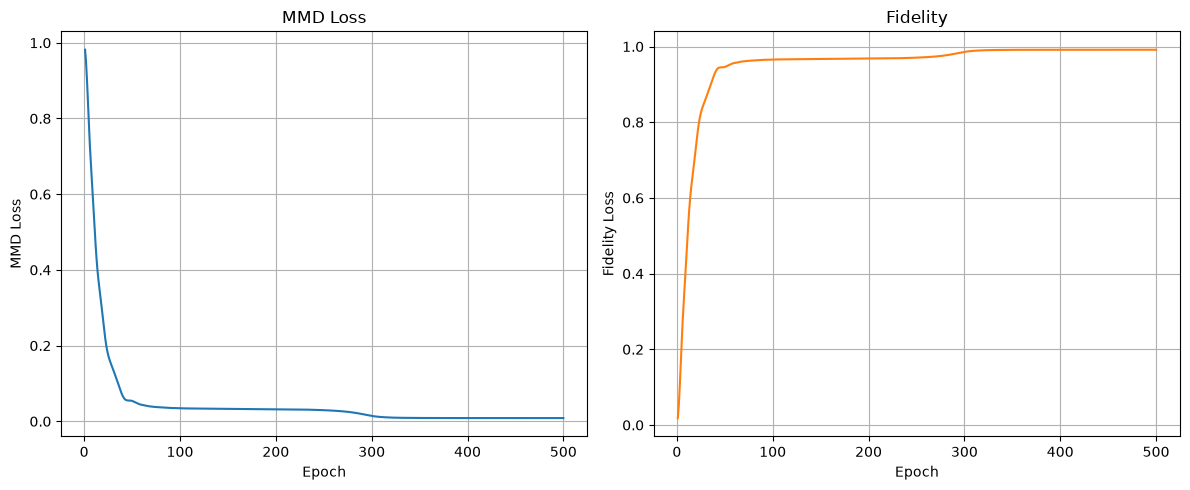


> Training finished.
Number of qubits: 6
Circuit depth (layers): 8
Number of parameters: 48
Best fidelity achieved: 0.99145058


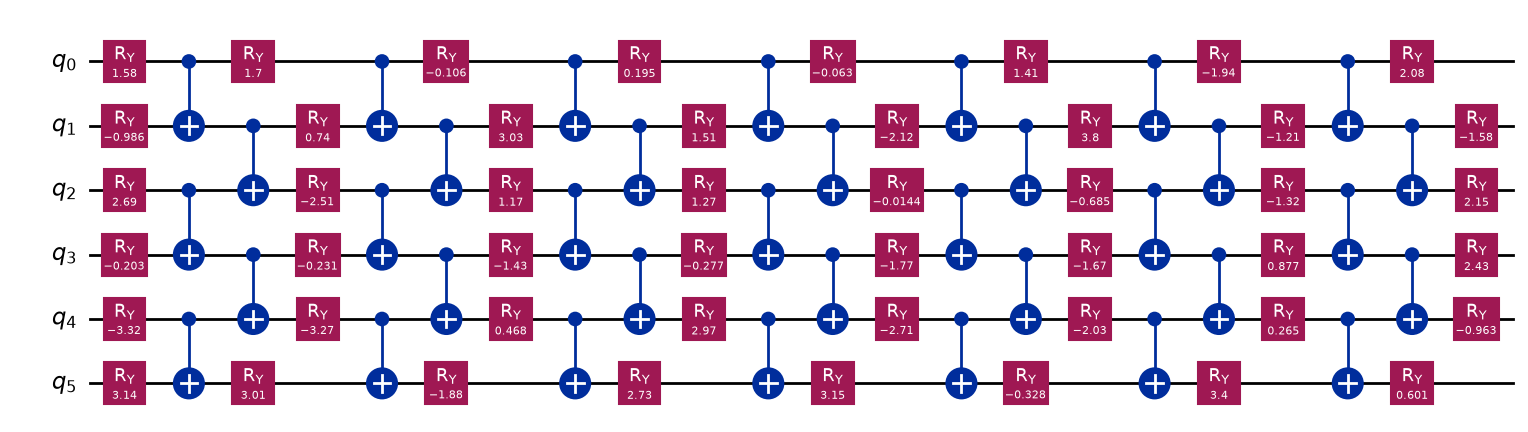


Data =  [[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99145058


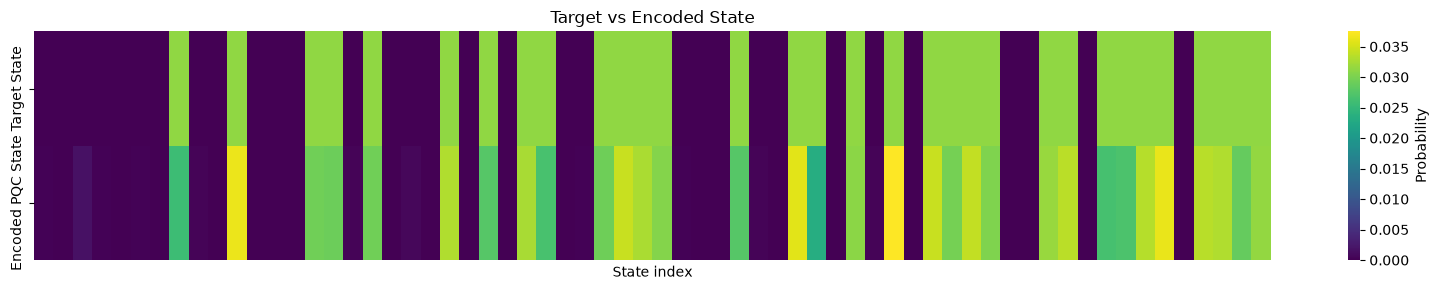

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

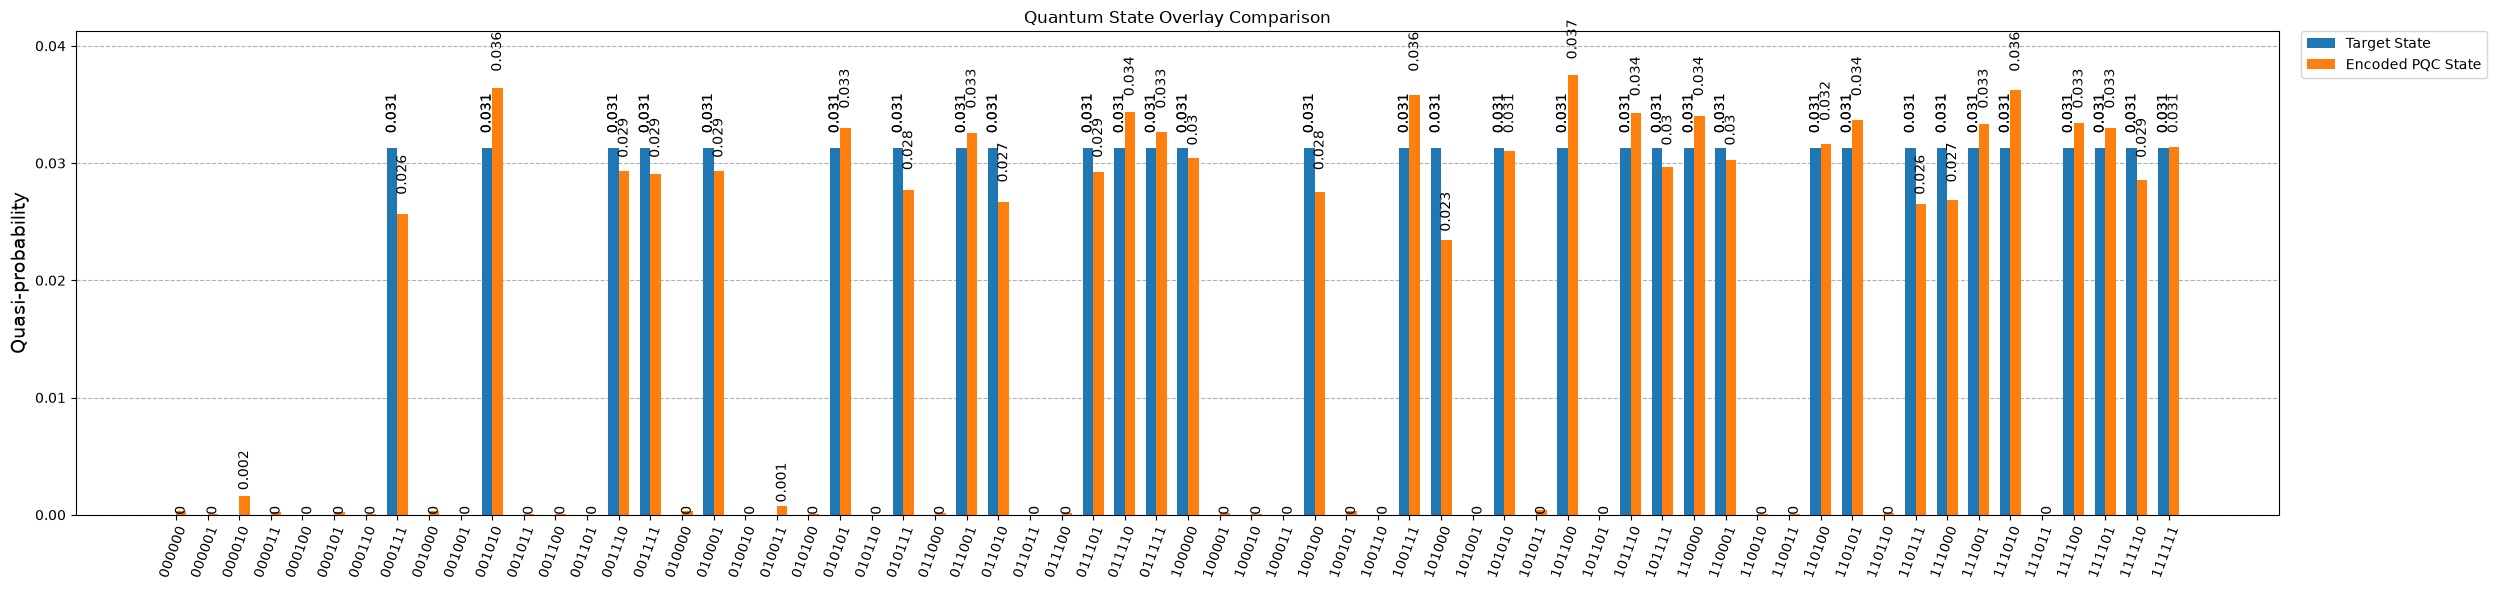


TARGET STATE
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
1                        3                        +0.177                   
2                        2                        +0.177                   
3                        2                        +0.177                   
3                        3                        +0.177                   
4                        1                        +0.177                   
5                        1                        +0.177                   
5                        3                        +0.177                   
6                        1                        +0.177                   
6                        2                        +0.177                   
7                        1                        +0.177                   
7                        2                        +0.177                  

<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (-0.017092800686785623+0j)
|000001> : (0.005693936818959868+0j)
|000010> : (-0.04015262577821167+0j)
|000011> : (-0.014173669550858504+0j)
|000100> : (0.003703348761352177+0j)
|000101> : (-0.01485407230027683+0j)
|000110> : (0.010386610494964666+0j)
|000111> : (-0.16025368566404688+0j)
|001000> : (-0.017139881352661004+0j)
|001001> : (-0.0028616483849725105+0j)
|001010> : (-0.19068911850086548+0j)
|001011> : (0.00785023668233646+0j)
|001100> : (0.005761708017329951+0j)
|001101> : (0.0009079476581136092+0j)
|001110> : (-0.1712744534244363+0j)
|001111> : (-0.1705260862156148+0j)
|010000> : (-0.018965262823922913+0j)
|010001> : (-0.17136140411801368+0j)
|010010> : (0.0017815901092380195+0j)
|010011> : (-0.027007809528732375+0j)
|010100> : (-0.008732007422051094+0j)
|010101> : (-0.1816791469565766+0j)
|010110> : (-0.002726555962726137+0j)
|010111> : (-0.16636213088223212+0j)
|011000> : (-0.011300850313532137+0j)
|011001> : (-0.18037968951475356+0j)


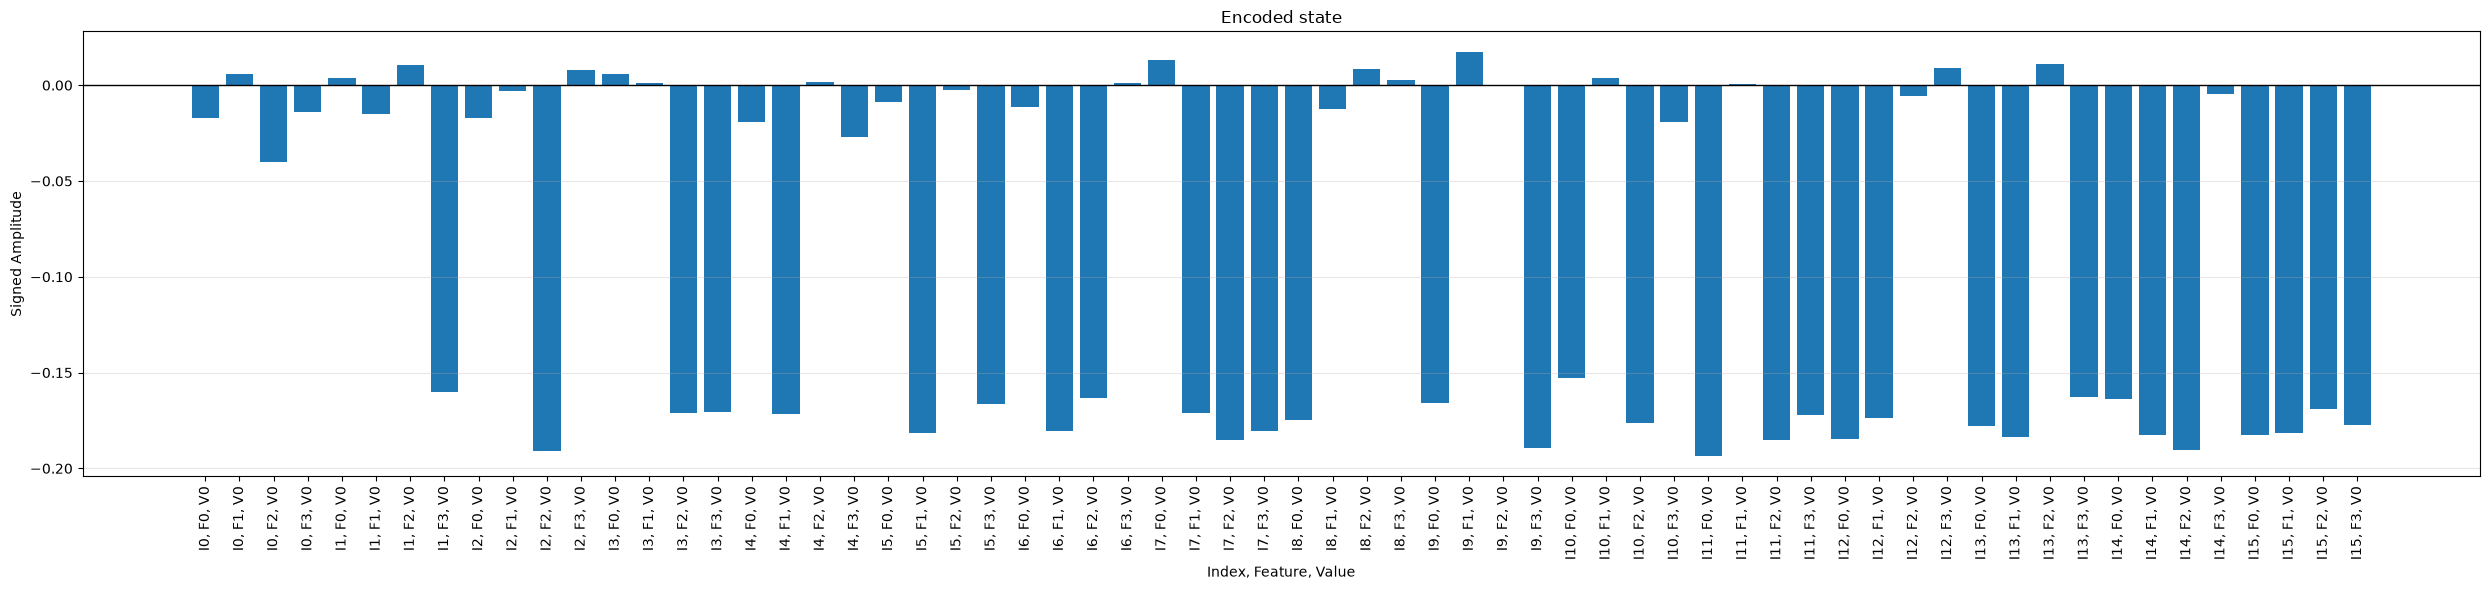


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


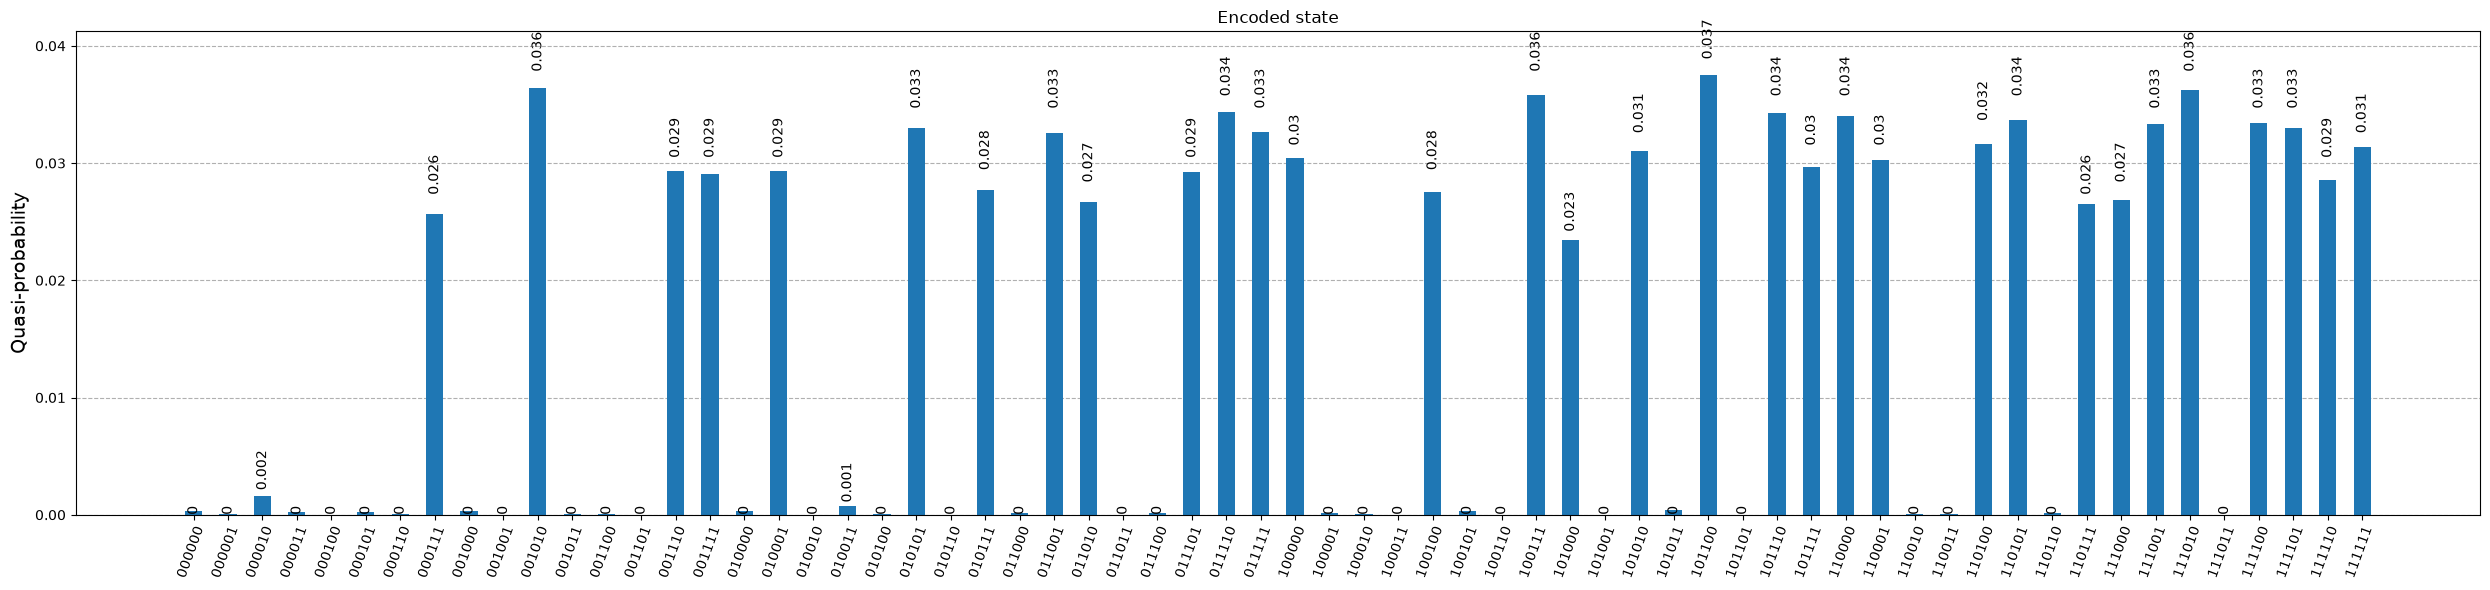

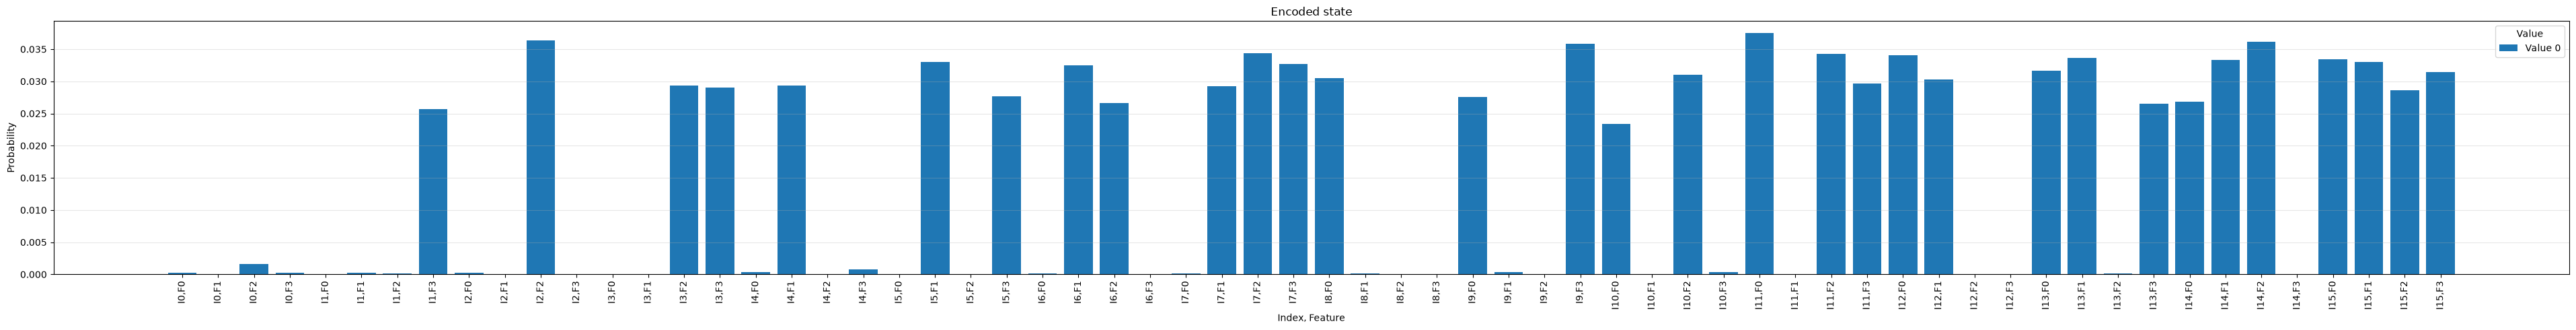


Encoded state
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        -0.017                   
0                        1                        +0.006                   
0                        2                        -0.040                   
0                        3                        -0.014                   
1                        0                        +0.004                   
1                        1                        -0.015                   
1                        2                        +0.010                   
1                        3                        -0.160                   
2                        0                        -0.017                   
2                        1                        -0.003                   
2                        2                        -0.191                 

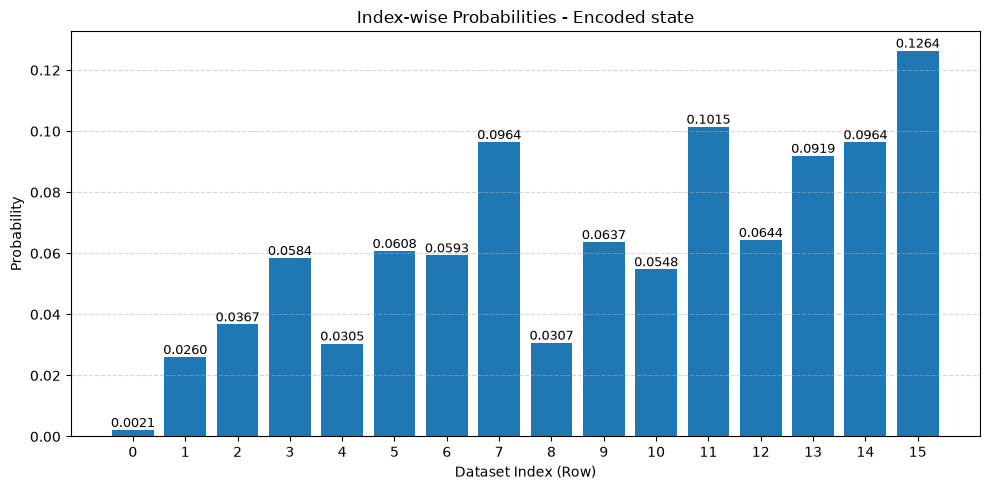

In [35]:
A_parameters, A_best_fidelity = encoder.generate_encoding(dataset, scheme="AMPL", depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, learning_rate=learning_rate_dataset_encoder, loss_function_type="FIDELITY")

In [36]:
# SAVE THE BEST PERFORMING DATASET ENCODER

if A_best_fidelity > A_saved_best_fidelity:
    save_parameters(
        A_parameters,
        depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, 
        learning_rate=learning_rate_dataset_encoder, fidelity=A_best_fidelity,
        scheme="AMPL", loss_function_type="FIDELITY"
    )

    print("New dataset encoder has better fidelity. Saved the new parameters.")

else:
    print(f"New dataset encoder did not improve fidelity {A_saved_best_fidelity}. Keeping the previous best parameters.")
    A_parameters = A_saved_parameters
    A_best_fidelity = A_saved_best_fidelity
    pqc_depth_for_dataset_encoder = A_saved_depth

print(f"Final best dataset encoder fidelity = {A_best_fidelity:.3f}")

New dataset encoder did not improve fidelity 0.9955144044616459. Keeping the previous best parameters.
Final best dataset encoder fidelity = 0.996



> Preparing query target state....

Number of query qubits: 2
Total number of qubits: 2
Padded number of query states: 4

Original query: [0. 0. 1. 1.]

Target: [0.         0.         0.70710678 0.70710678]

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 0.9999999999999999
Nonzero amplitudes: 2

> Starting training....

Number of parameters = 6

> Using adam optimization....
Epoch 1 - Loss 0.9325123351719202 - Fidelity 0.06748766482807977
Epoch 2 - Loss 0.8293475638597876 - Fidelity 0.17065243614021247
Epoch 3 - Loss 0.6942027100279418 - Fidelity 0.30579728997205824
Epoch 4 - Loss 0.5465297090879735 - Fidelity 0.4534702909120265
Epoch 5 - Loss 0.4042554883071451 - Fidelity 0.5957445116928549
Epoch 6 - Loss 0.27131960340152317 - Fidelity 0.7286803965984768
Epoch 7 - Loss 0.15473206490765323 - Fidelity 0.8452679350923468
Epoch 8 - Loss 0.06661888349145195 - Fidelity 0.933381116508548
Epoch 9 - Loss 0.01663471762278157 - Fidelity 0.9833652823772184
Epoch 10 - Loss 0.007173727939892682 - Fidelity 0.9928262720601073
Epoch 11 - Loss 0.030723579212032615 - Fidelity 0.9692764207879674
Epoch 12 - Loss 0.07101244323733635 - Fidelity 0.9289875567626636
Epoch 13 - Loss 0.10999443672044085 - Fidelity 0.8900055632795592
Epoch 14 - Loss

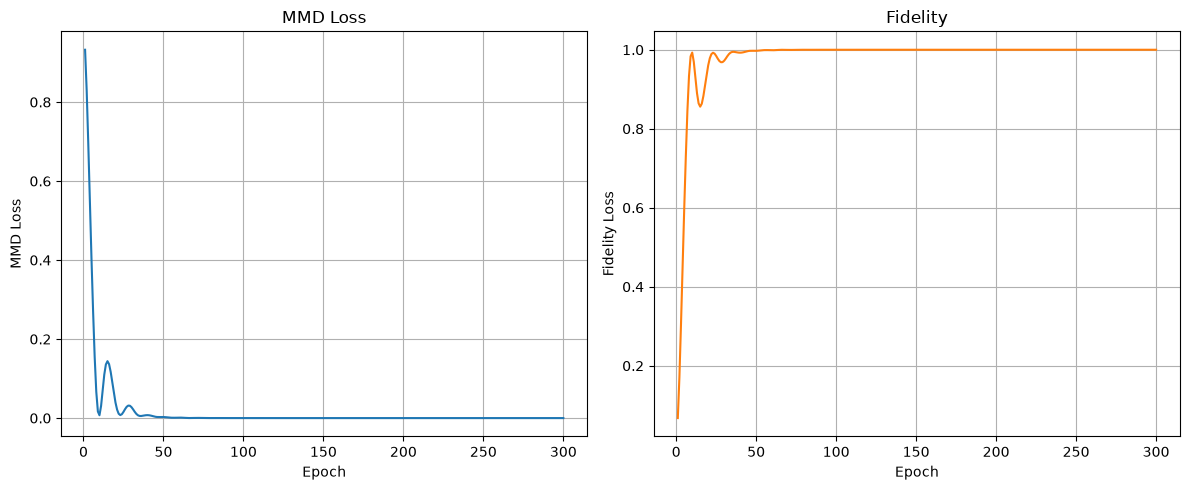


> Training finished.
Number of qubits: 2
Circuit depth (layers): 3
Number of parameters: 6
Best fidelity achieved: 0.99999918


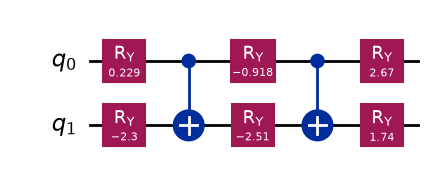


Data =  [0 0 1 1]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99999918


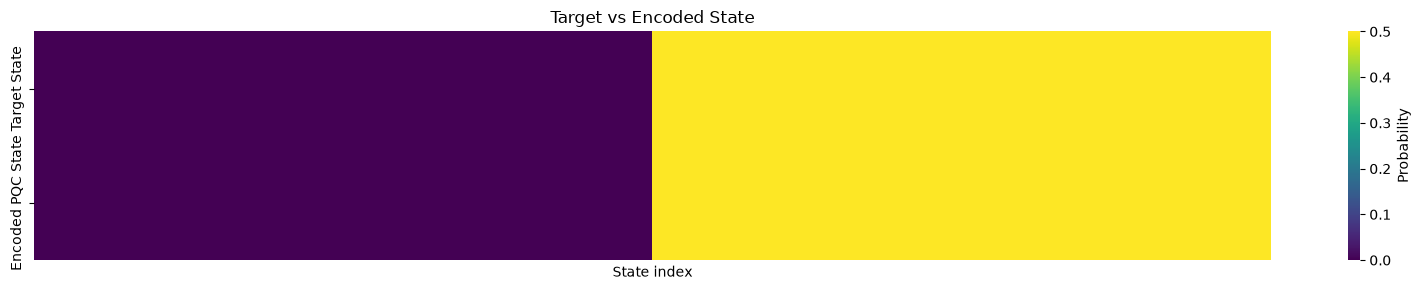

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

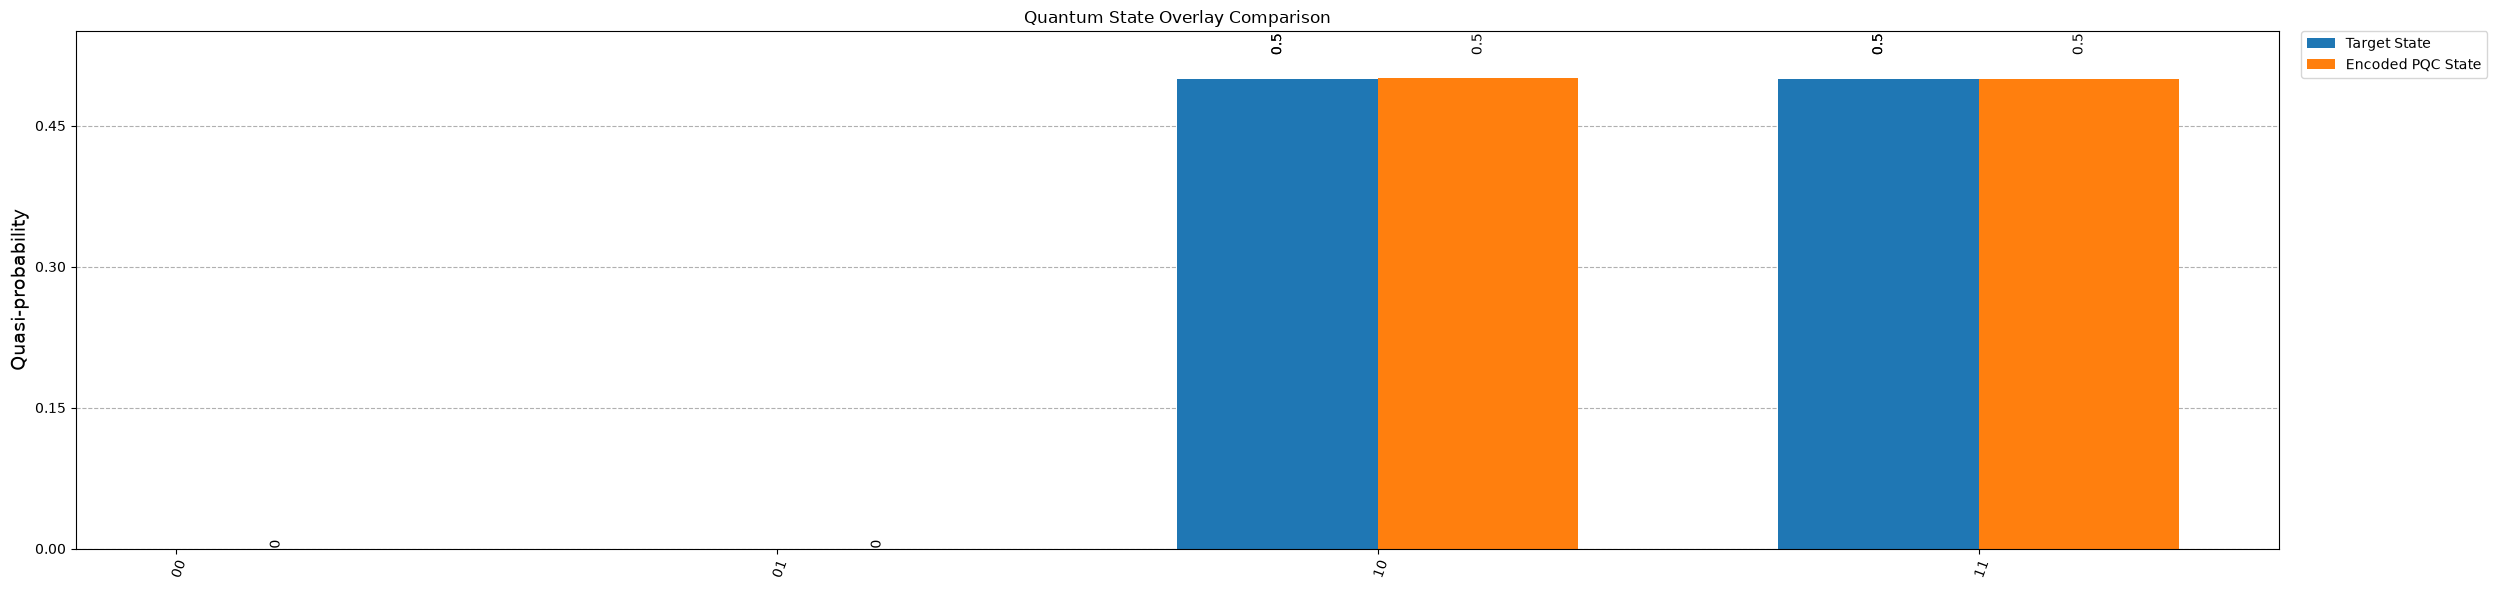


TARGET STATE
Feature                  Value-0-Amplitude        
--------------------------------------------------
2                        +0.707                   
3                        +0.707                   

ENCODED STATE
Feature                  Value-0-Amplitude        
--------------------------------------------------
0                        +0.001                   
1                        -0.000                   
2                        -0.707                   
3                        -0.707                   

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|00> : (0.0007834848978816203+0j)
|01> : (-0.00033307268879923527+0j)
|10> : (-0.7073232026119876+0j)
|11> : (-0.7068897808433222+0j)


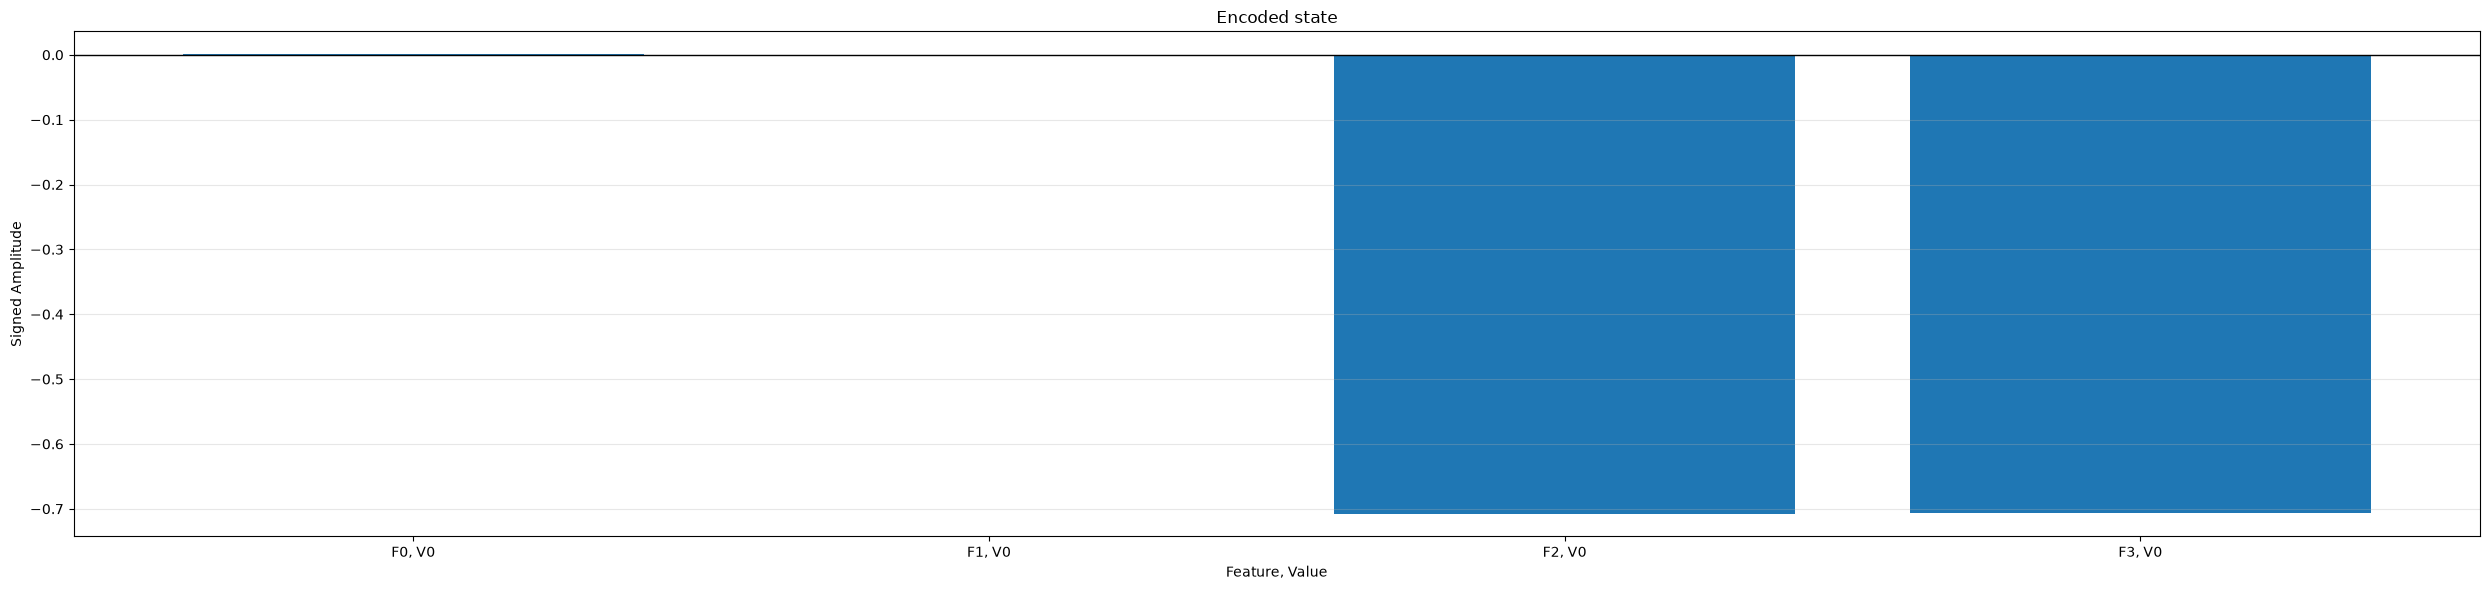


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


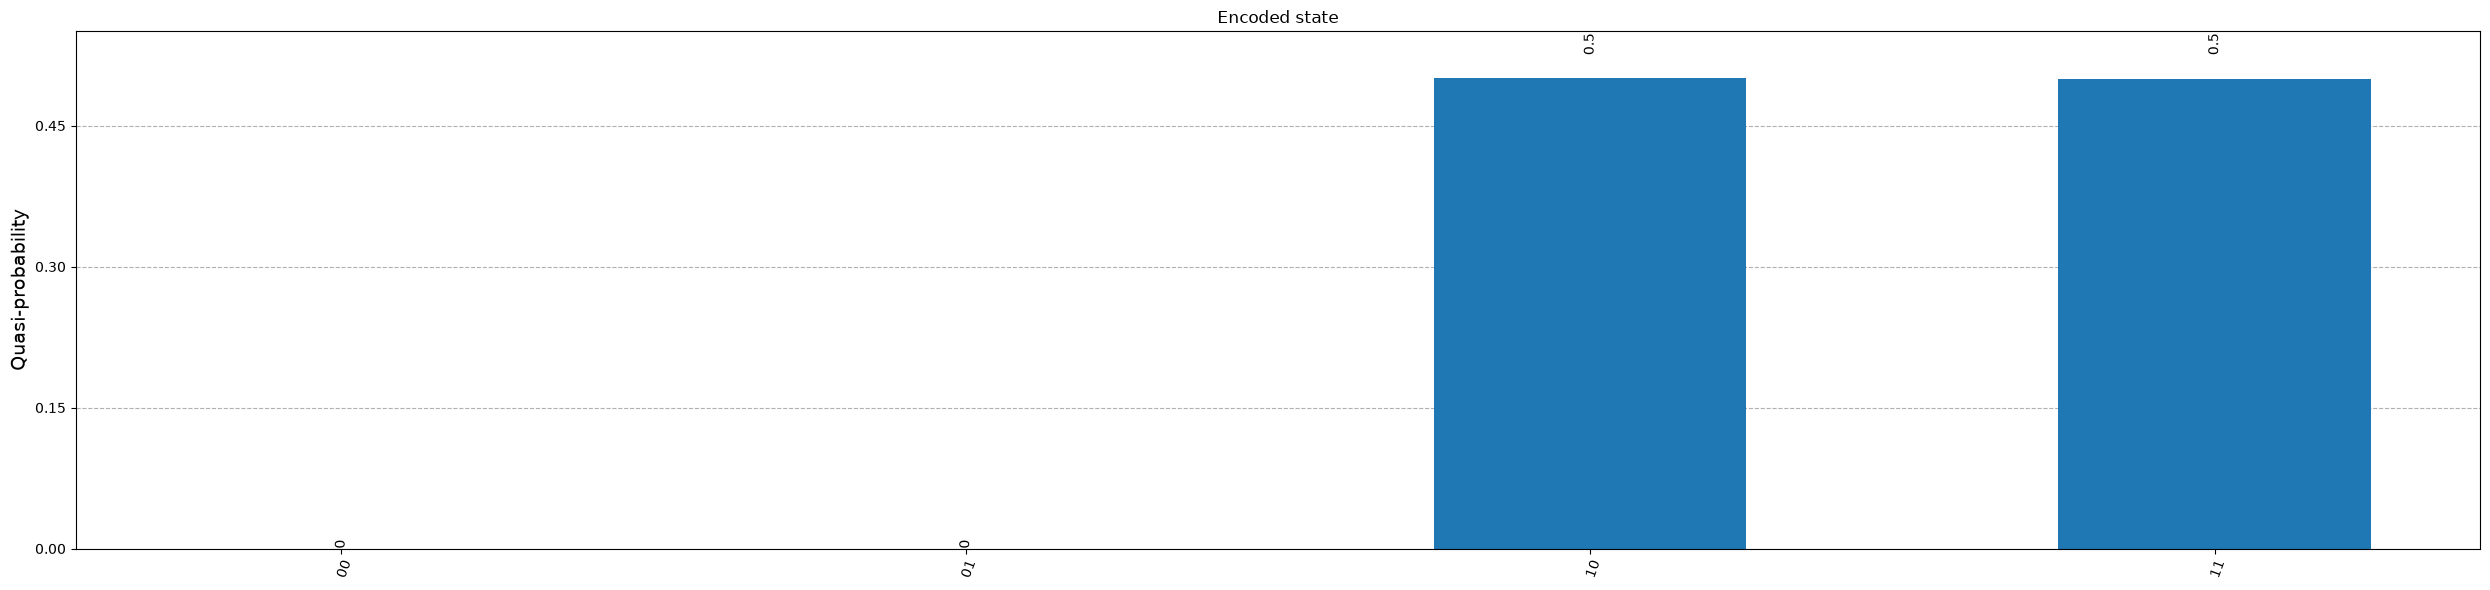

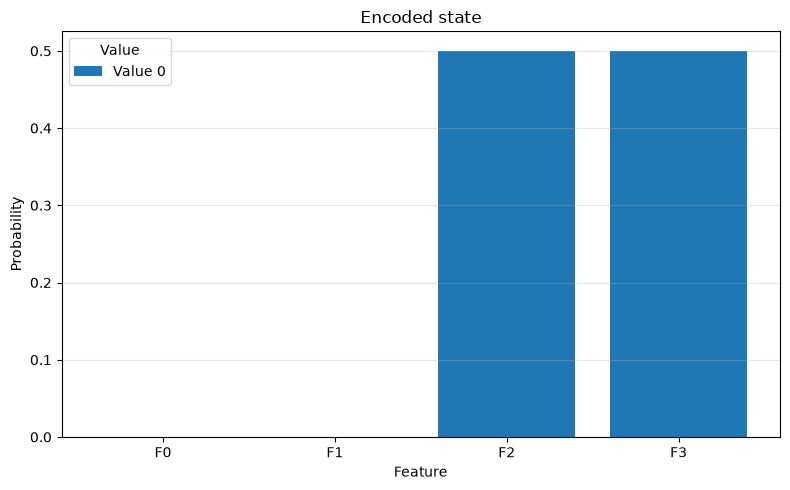


Encoded state
Feature                  Value-0-Amplitude        
--------------------------------------------------
0                        +0.001                   
1                        -0.000                   
2                        -0.707                   
3                        -0.707                   


In [37]:
B_parameters_ampl_fidelity, _ = encoder.generate_encoding(query, scheme="AMPL", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.1, loss_function_type="FIDELITY")

## <u>**U operation**</u>

U = (B† ⊗ I_I) A

In [38]:
n_index_q = math.ceil(math.log2(len(dataset)))
n_feature_q = math.ceil(math.log2(len(dataset[0])))

n_value_q = 0
print("Index qubits = ", n_index_q)
print("Feature qubits = ", n_feature_q)
print("Value qubits = ", n_value_q)

Index qubits =  4
Feature qubits =  2
Value qubits =  0


In [39]:
A = encoder.pqc(A_parameters, depth=pqc_depth_for_dataset_encoder, n_qubits=(n_index_q + n_feature_q + n_value_q))

In [40]:
B = encoder.pqc(B_parameters_ampl_fidelity, depth=pqc_depth_for_query_encoder, n_qubits=(n_value_q + n_feature_q))


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (1+0j)


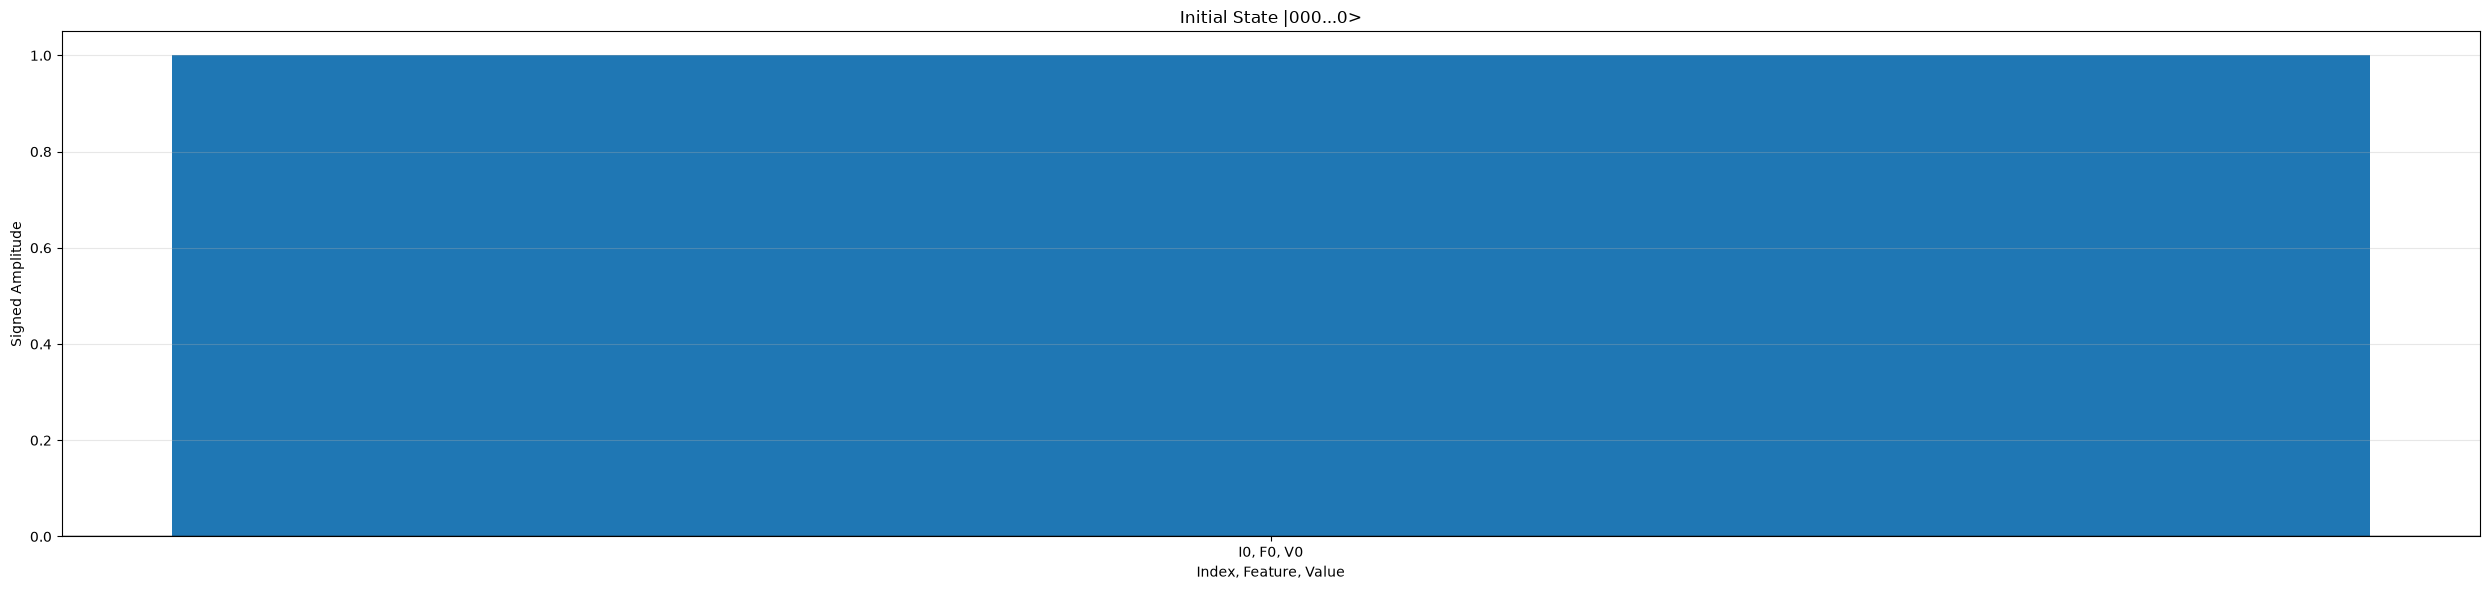


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


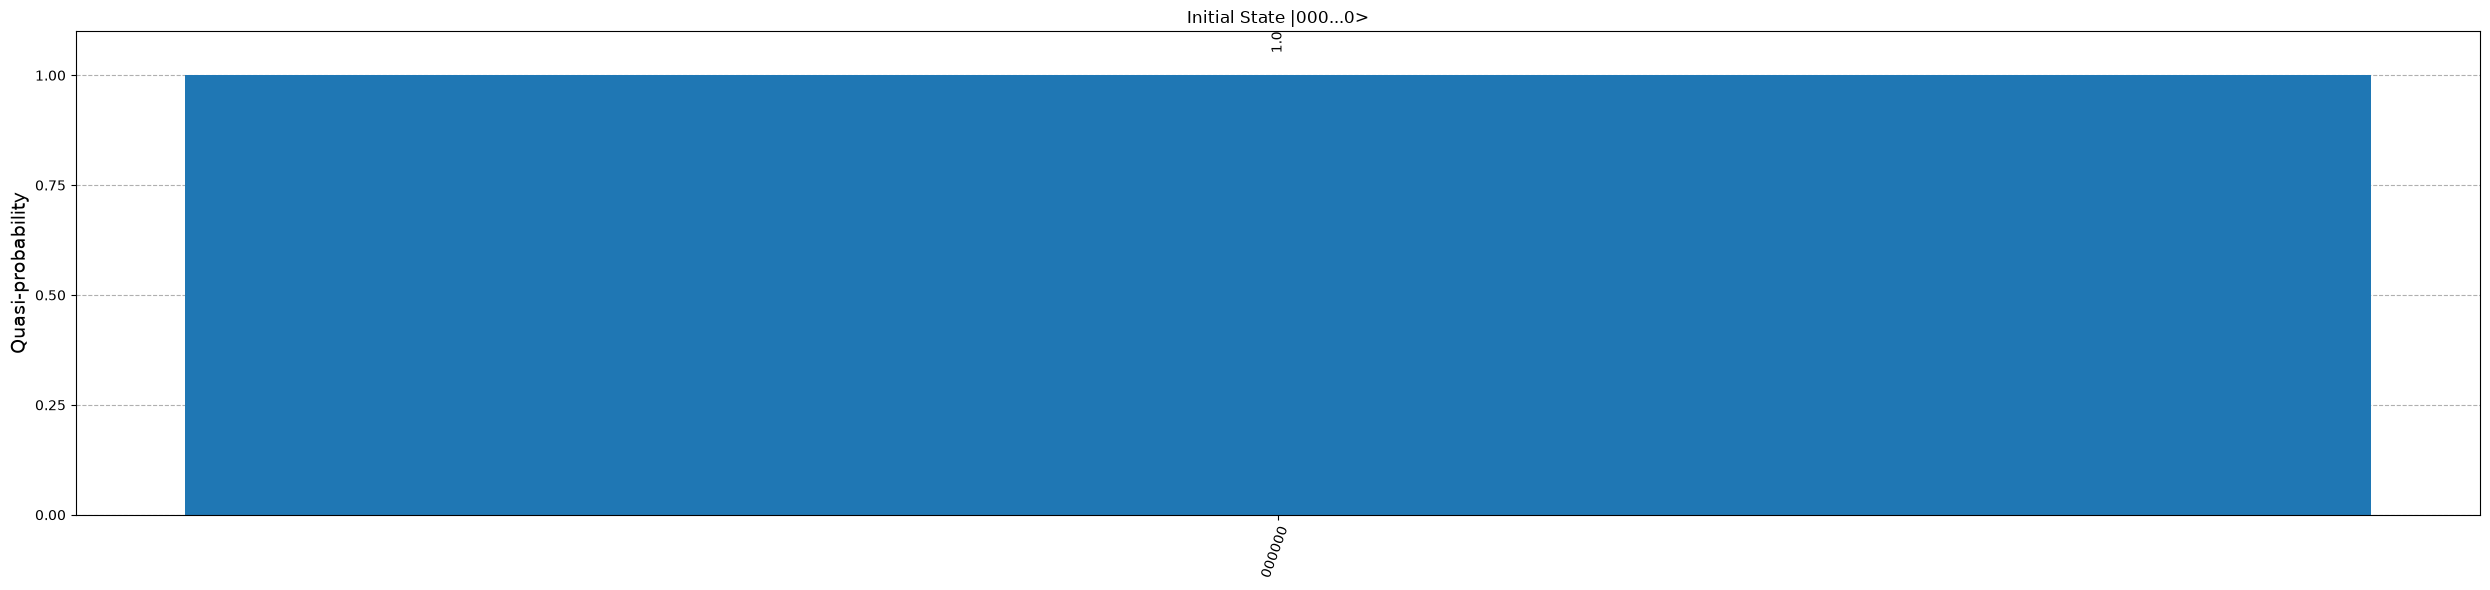

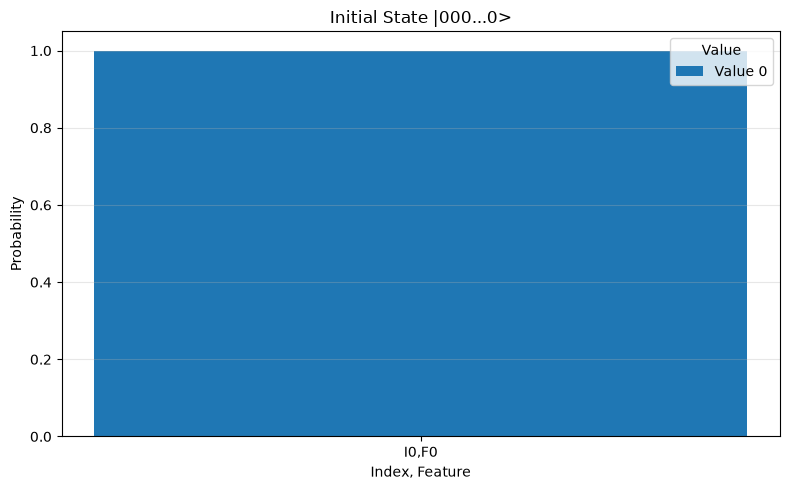


Initial State |000...0>
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        +1.000                   


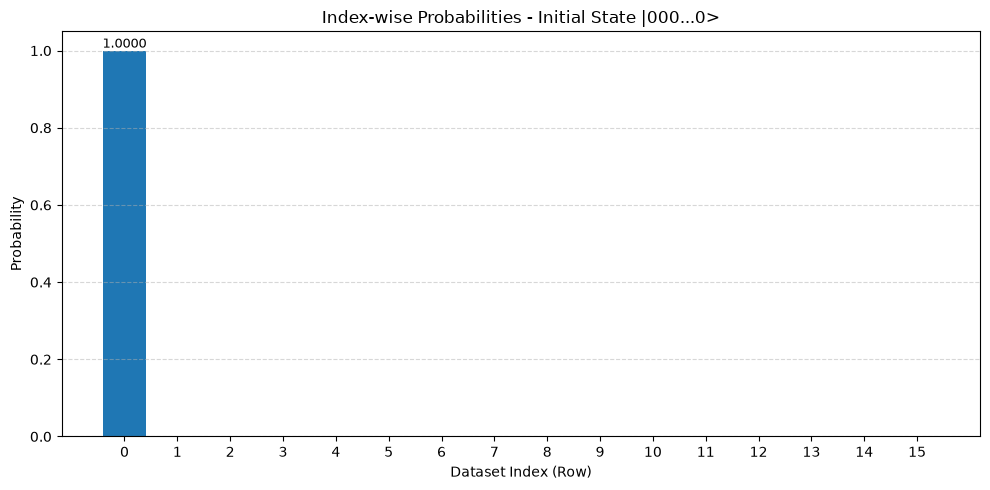

In [41]:
value_reg = QuantumRegister(n_value_q, "Value")
feature_reg = QuantumRegister(n_feature_q, "Feature")
index_reg = QuantumRegister(n_index_q, "Index")
qc = QuantumCircuit(value_reg, feature_reg, index_reg)

initial_state = Statevector.from_instruction(qc)
state_analysis(initial_state, "Initial State |000...0>", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (-0.009935218749129133+0j)
|000001> : (-0.014602043263032894+0j)
|000010> : (-0.0030855733829966447+0j)
|000011> : (-0.011699321515345078+0j)
|000100> : (0.009020430544140453+0j)
|000101> : (0.009378392759744732+0j)
|000110> : (0.0031977876049272343+0j)
|000111> : (-0.17431175174407526+0j)
|001000> : (-0.013891346906608584+0j)
|001001> : (-0.015707889864975462+0j)
|001010> : (-0.1618188910486607+0j)
|001011> : (0.0014918102577553328+0j)
|001100> : (0.0008772554569523484+0j)
|001101> : (0.01033407994612771+0j)
|001110> : (-0.17905287680552126+0j)
|001111> : (-0.17187685776508602+0j)
|010000> : (-0.009355414968091445+0j)
|010001> : (-0.17257559214614412+0j)
|010010> : (-0.024451228846009487+0j)
|010011> : (-0.008404440798321934+0j)
|010100> : (-0.00945166140185373+0j)
|010101> : (-0.1911482558237619+0j)
|010110> : (-0.0012477495162359288+0j)
|010111> : (-0.17157139076034122+0j)
|011000> : (0.005803482094154024+0j)
|011001> : (-0.18848265255347754+

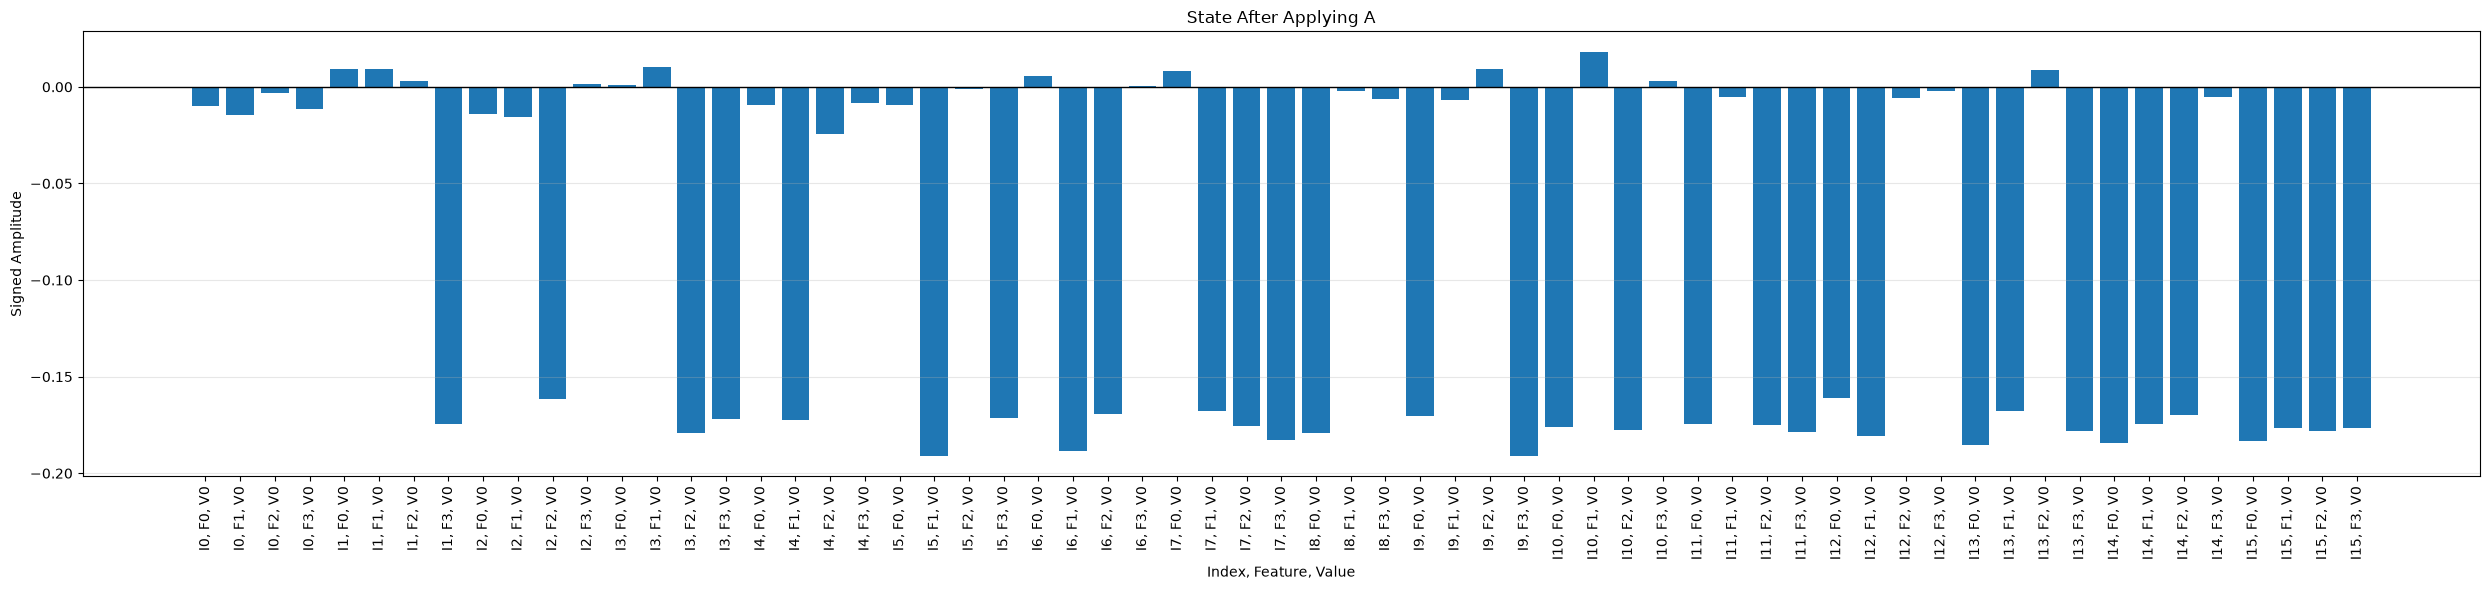


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


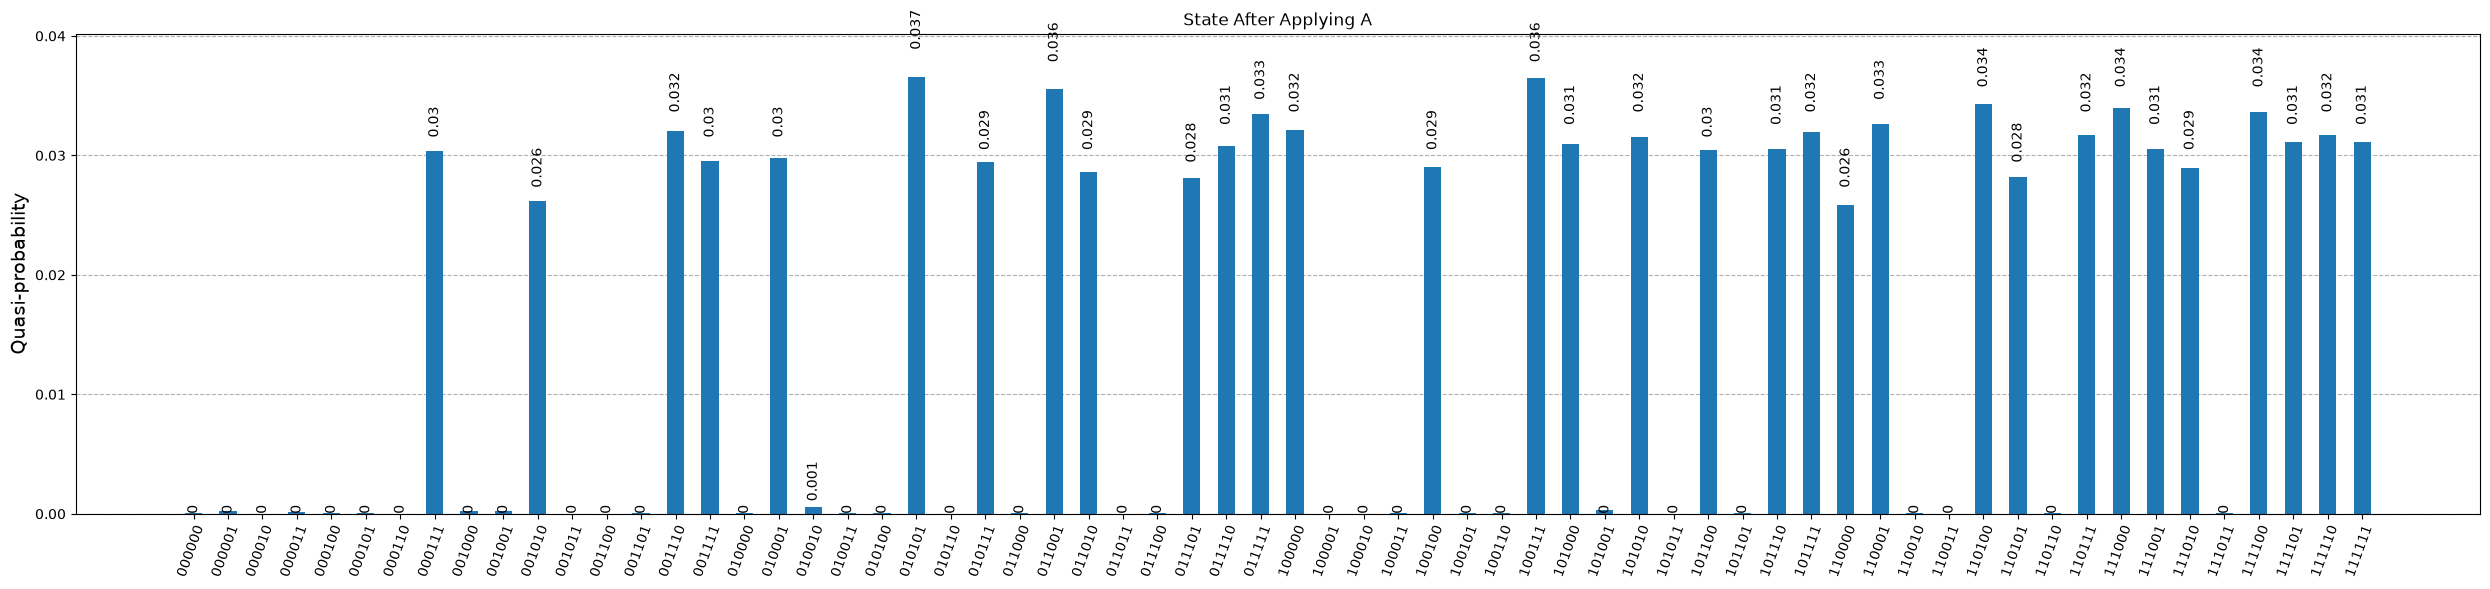

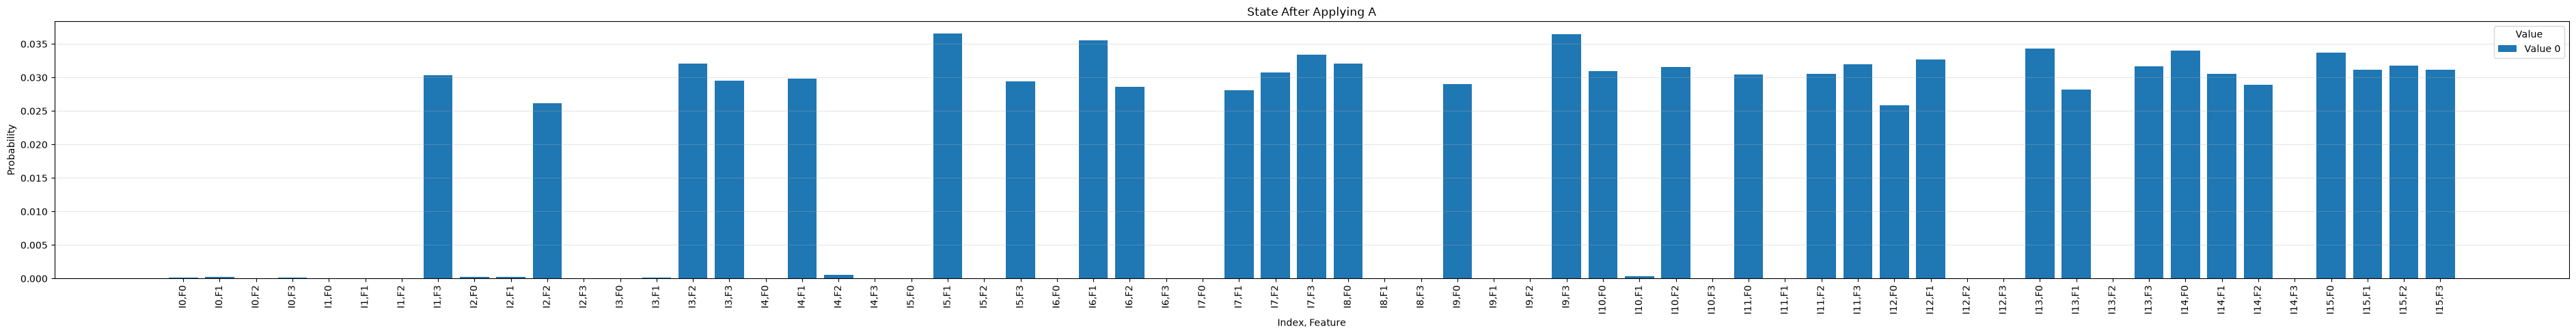


State After Applying A
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        -0.010                   
0                        1                        -0.015                   
0                        2                        -0.003                   
0                        3                        -0.012                   
1                        0                        +0.009                   
1                        1                        +0.009                   
1                        2                        +0.003                   
1                        3                        -0.174                   
2                        0                        -0.014                   
2                        1                        -0.016                   
2                        2                        -0.162        

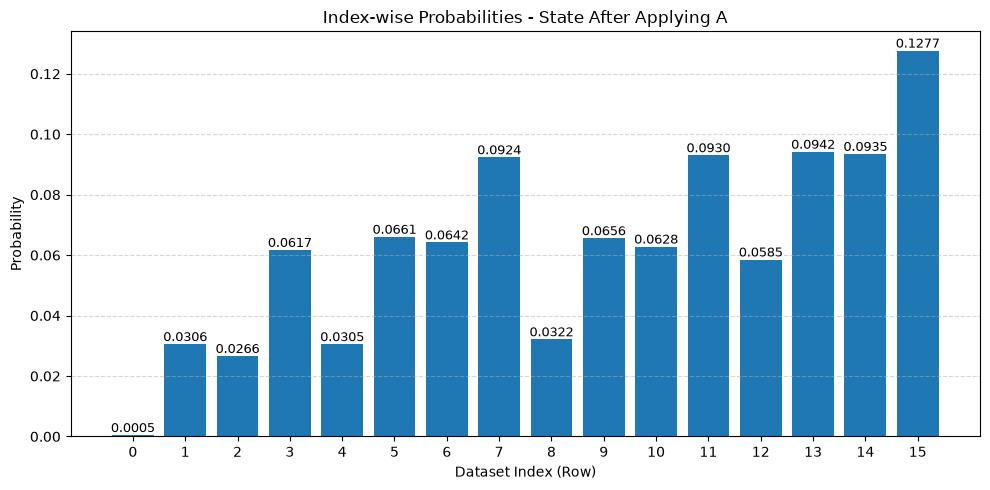

In [42]:
qc.compose(A, inplace=True)
qc.barrier()

state_after_A = Statevector.from_instruction(qc)
state_analysis(state_after_A, "State After Applying A", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (0.010449707917117827+0j)
|000001> : (0.003350348456267754+0j)
|000010> : (-0.01394517065378812+0j)
|000011> : (-0.011976398088534004+0j)
|000100> : (0.12096127030340552+0j)
|000101> : (-0.10787591101033812+0j)
|000110> : (-0.008782615803337272+0j)
|000111> : (-0.06494736045089974+0j)
|001000> : (0.11339805904209461+0j)
|001001> : (0.1037170931977719+0j)
|001010> : (0.0018972773034240471+0j)
|001011> : (0.05483914153118778+0j)
|001100> : (0.24814349389317966+0j)
|001101> : (0.0017503363905883077+0j)
|001110> : (0.010830777503314709+0j)
|001111> : (0.0036860185405779085+0j)
|010000> : (0.02328608519935082+0j)
|010001> : (0.045737623430327376+0j)
|010010> : (-0.1669658929791518+0j)
|010011> : (-0.0051550588491762715+0j)
|010100> : (0.12222088602700144+0j)
|010101> : (-0.056972451409760795+0j)
|010110> : (-0.20295451738503556+0j)
|010111> : (-0.08179821077602537+0j)
|011000> : (0.11935738988999113+0j)
|011001> : (0.1276843736079769+0j)
|011010> : (

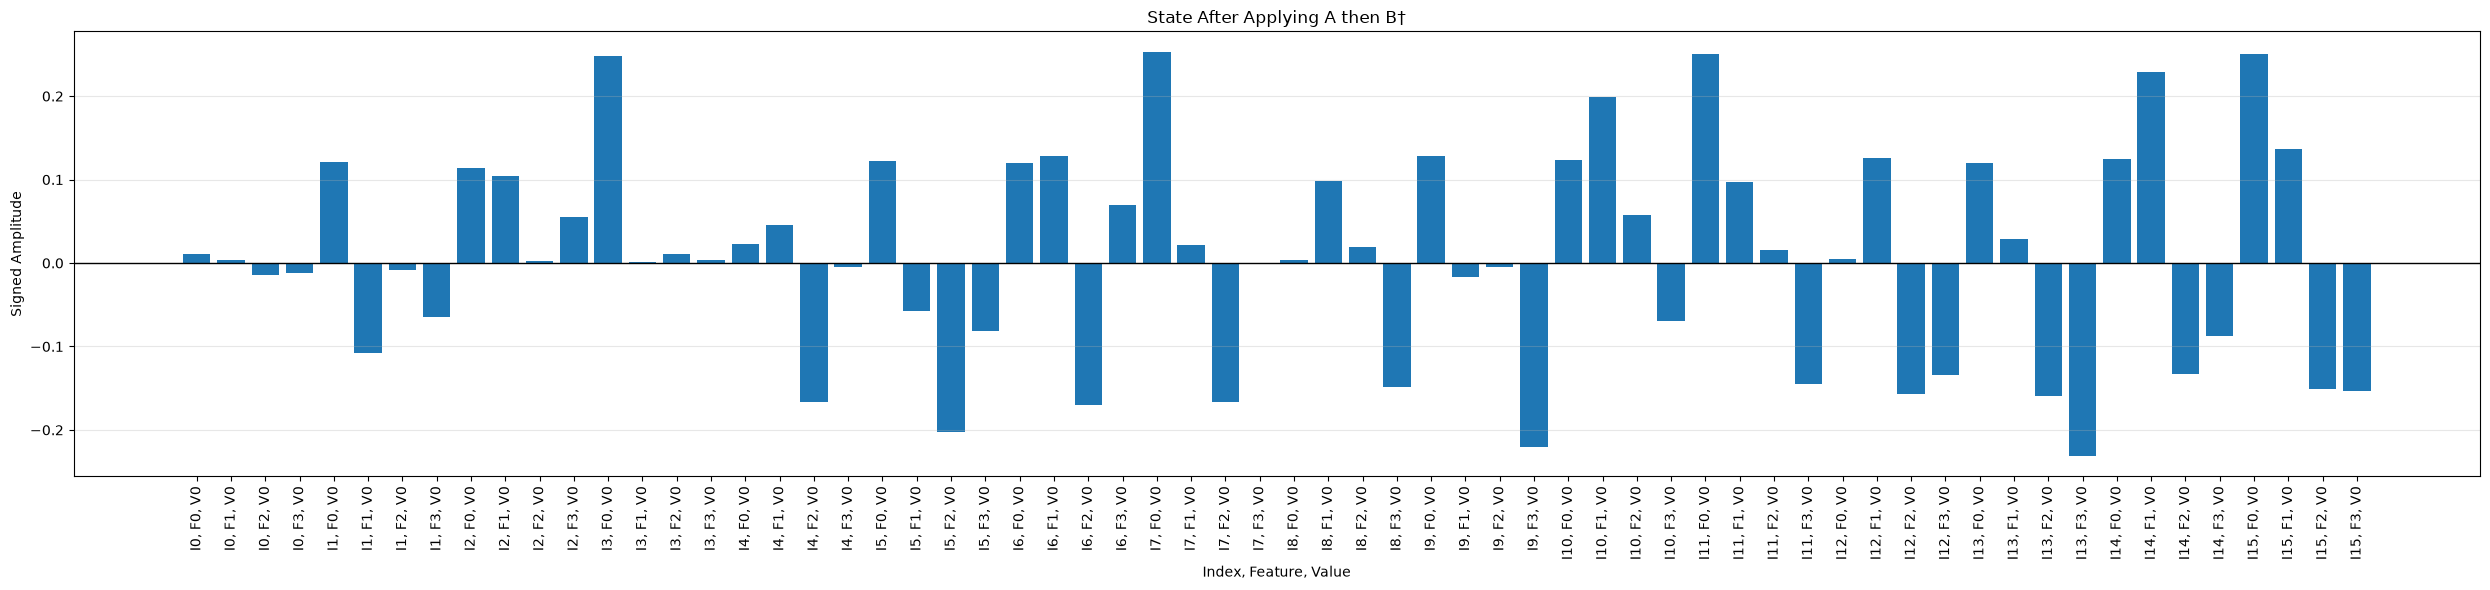


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


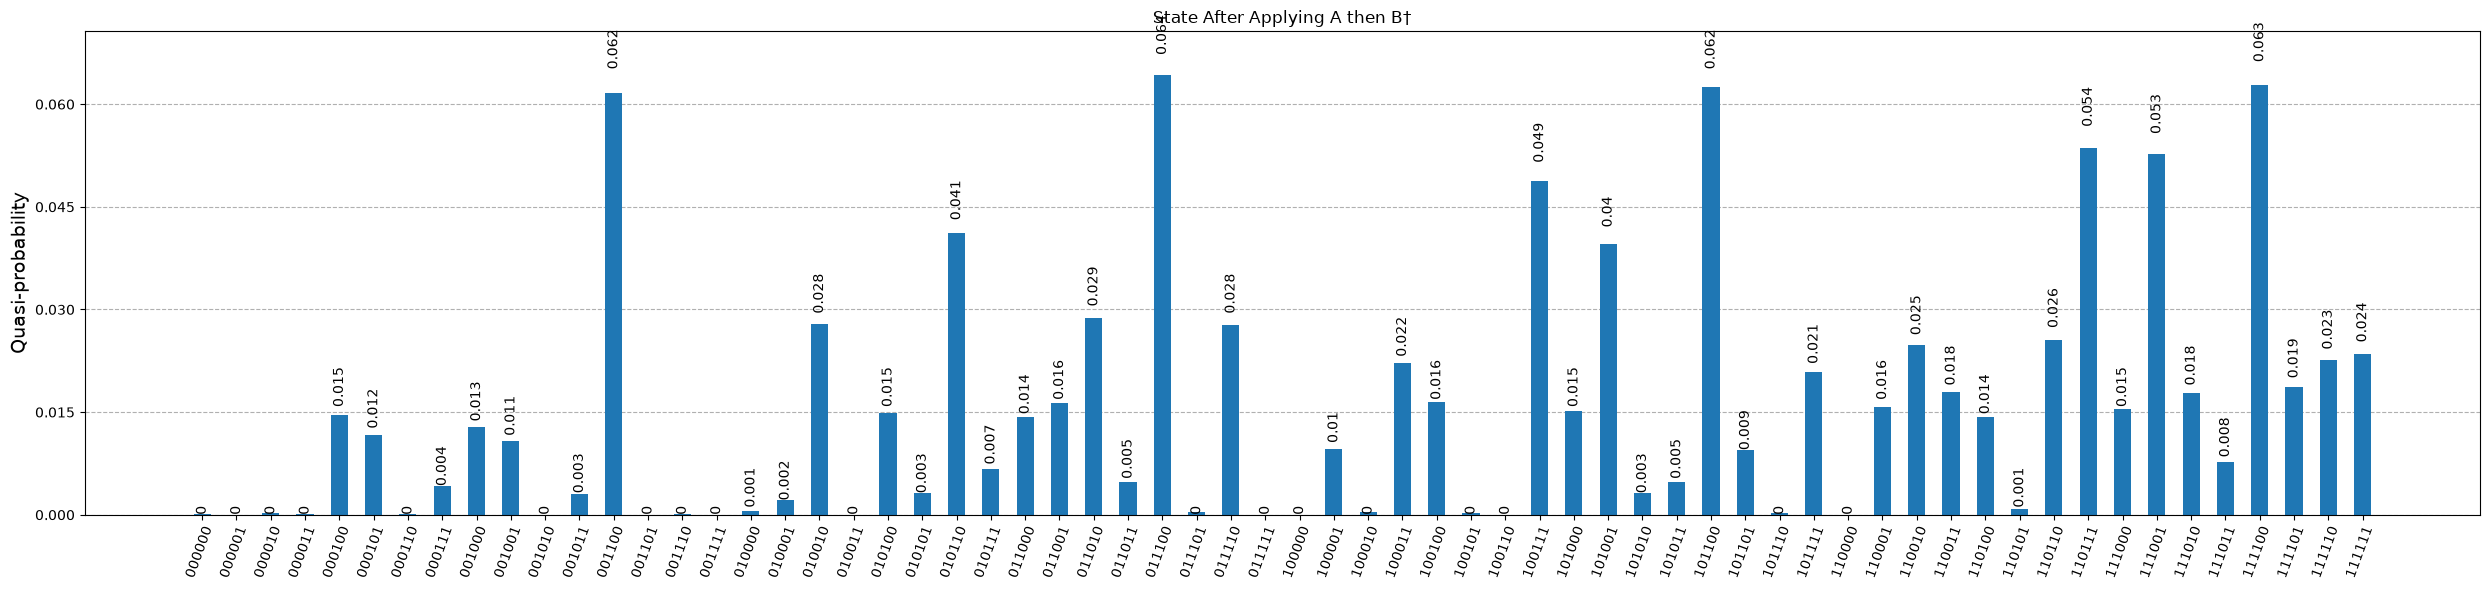

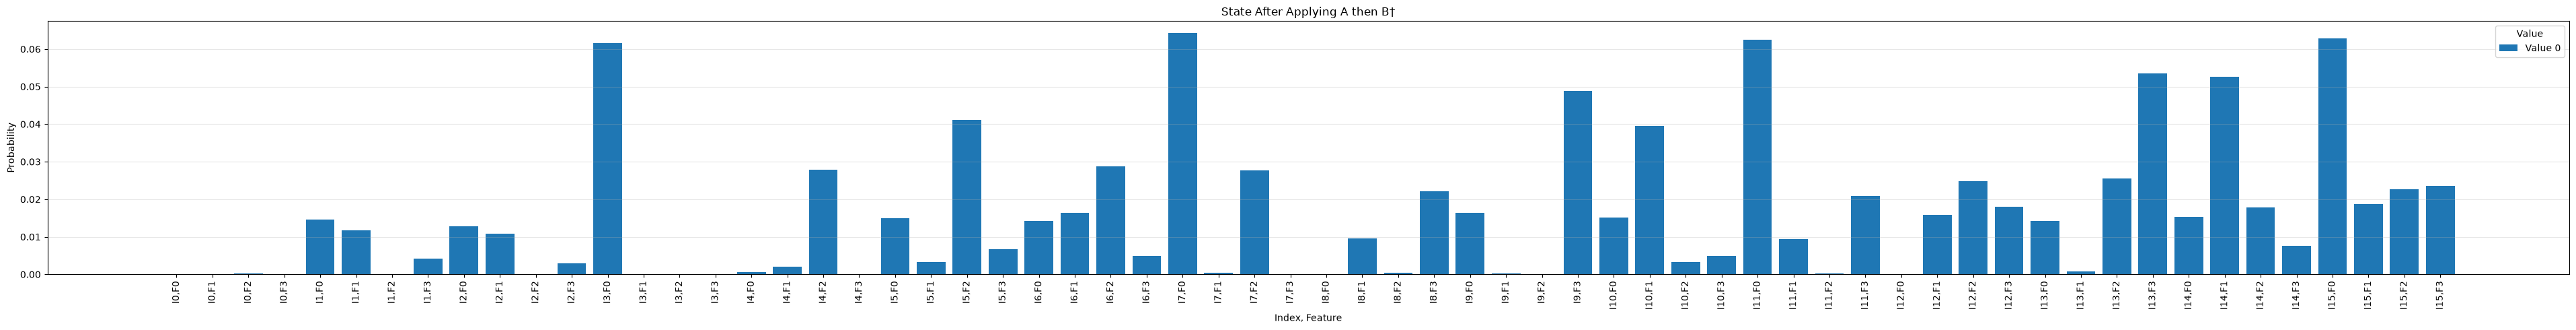


State After Applying A then B†
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        +0.010                   
0                        1                        +0.003                   
0                        2                        -0.014                   
0                        3                        -0.012                   
1                        0                        +0.121                   
1                        1                        -0.108                   
1                        2                        -0.009                   
1                        3                        -0.065                   
2                        0                        +0.113                   
2                        1                        +0.104                   
2                        2                        +0.002

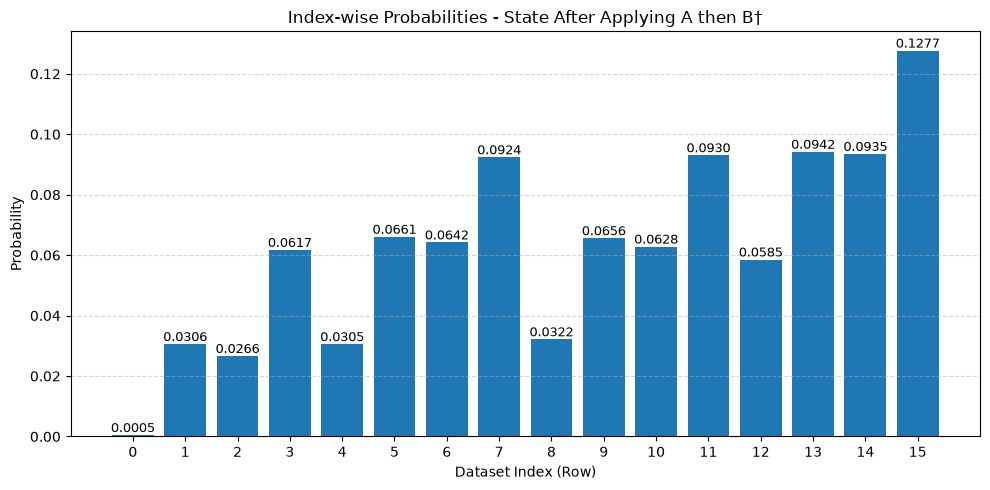

In [43]:
qc.compose(B.inverse(), qubits=range(n_feature_q + n_value_q), inplace=True)
qc.barrier()

state_after_B_inverse = Statevector.from_instruction(qc)
state_analysis(state_after_B_inverse, "State After Applying A then B†", n_value_q, n_feature_q, n_index_q)

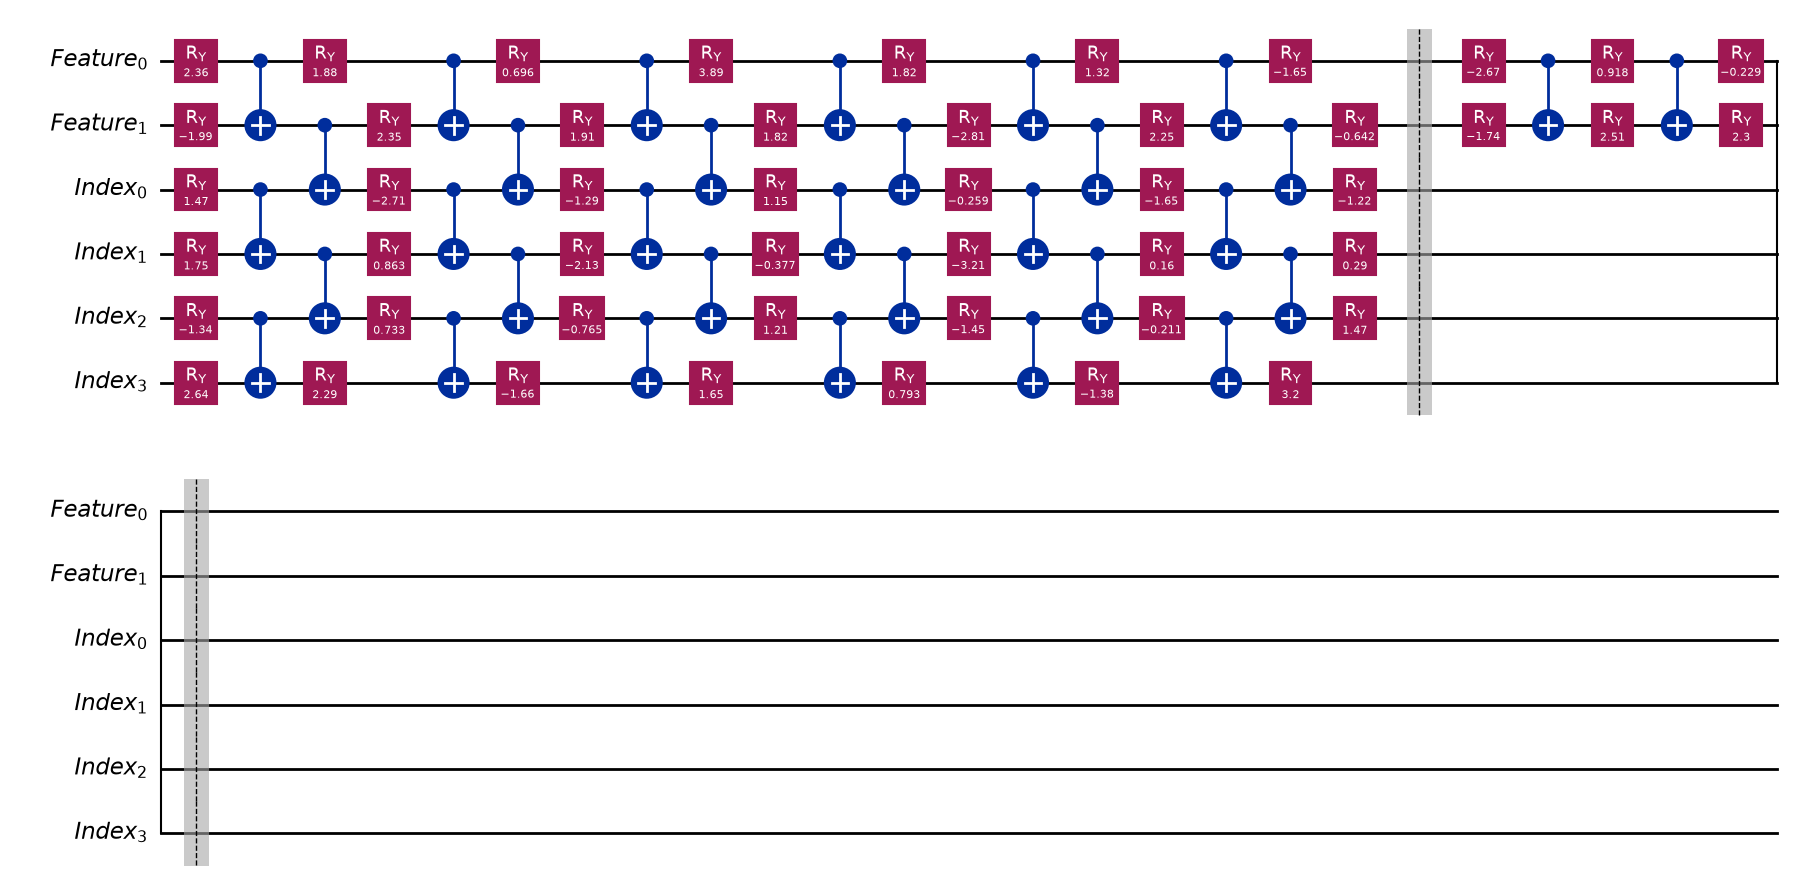

In [44]:
display(qc.draw("mpl"))

# <u>**Part 2: Use Grover Search for Image Matching**</u>

In [45]:
try:
    A_saved = load_parameters(scheme="AMPL", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved dataset encoder. Fidelity = {A_saved_best_fidelity:.3f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset enocder. Train again.")

Loaded saved dataset encoder. Fidelity = 0.996


In [46]:
A_saved_parameters

array([ 2.35660313, -1.99468558,  1.47433522,  1.75454519, -1.34028376,
        2.64053718,  1.88282037,  2.34993932, -2.70840074,  0.86268442,
        0.73328267,  2.29044514,  0.69556727,  1.905772  , -1.28594063,
       -2.12529527, -0.76459547, -1.66101142,  3.8921131 ,  1.81659085,
        1.15199355, -0.37659951,  1.20937116,  1.65180934,  1.81719768,
       -2.80763608, -0.25882748, -3.21391979, -1.44981978,  0.79348183,
        1.32315662,  2.25015077, -1.65025471,  0.16029115, -0.21098904,
       -1.37961045, -1.64803888, -0.6423265 , -1.21578534,  0.29019667,
        1.47489185,  3.19988422])

In [47]:
GS = GroverSearch()

## <u>**GS with AMPL scheme and FIDELITY cost function**</u>

Number of data elements =  16
Number of features =  4
Index qubits =  4
Data qubits =  2
Value qubits =  0
Total no of qubits =  6
Range of value qubits =  []
Range of feature qubits =  [0, 1]
Range of index qubits =  [2, 3, 4, 5]

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (0.010449707917117827+0j)
|000001> : (0.003350348456267754+0j)
|000010> : (-0.01394517065378812+0j)
|000011> : (-0.011976398088534004+0j)
|000100> : (0.12096127030340552+0j)
|000101> : (-0.10787591101033812+0j)
|000110> : (-0.008782615803337272+0j)
|000111> : (-0.06494736045089974+0j)
|001000> : (0.11339805904209461+0j)
|001001> : (0.1037170931977719+0j)
|001010> : (0.0018972773034240471+0j)
|001011> : (0.05483914153118778+0j)
|001100> : (0.24814349389317966+0j)
|001101> : (0.0017503363905883077+0j)
|001110> : (0.010830777503314709+0j)
|001111> : (0.0036860185405779085+0j)
|010000> : (0.02328608519935082+0j)
|010001> : (0.045737623430327376+0j)
|010010> : (-0.1669658929791518+0j)
|010011> : (-0.0051550588491762715+0j)
|010100> : (0.12222088602700144+0j)
|010101> : (-0.056972451409760795+0j)
|010110> : (-0.20295451738503556+0j)
|010111> : (-0.08179821077602537+0j)
|011000> : (0.11935738988999113+0j)
|011001> : (0.1276843736079769+0j)
|011010> : (

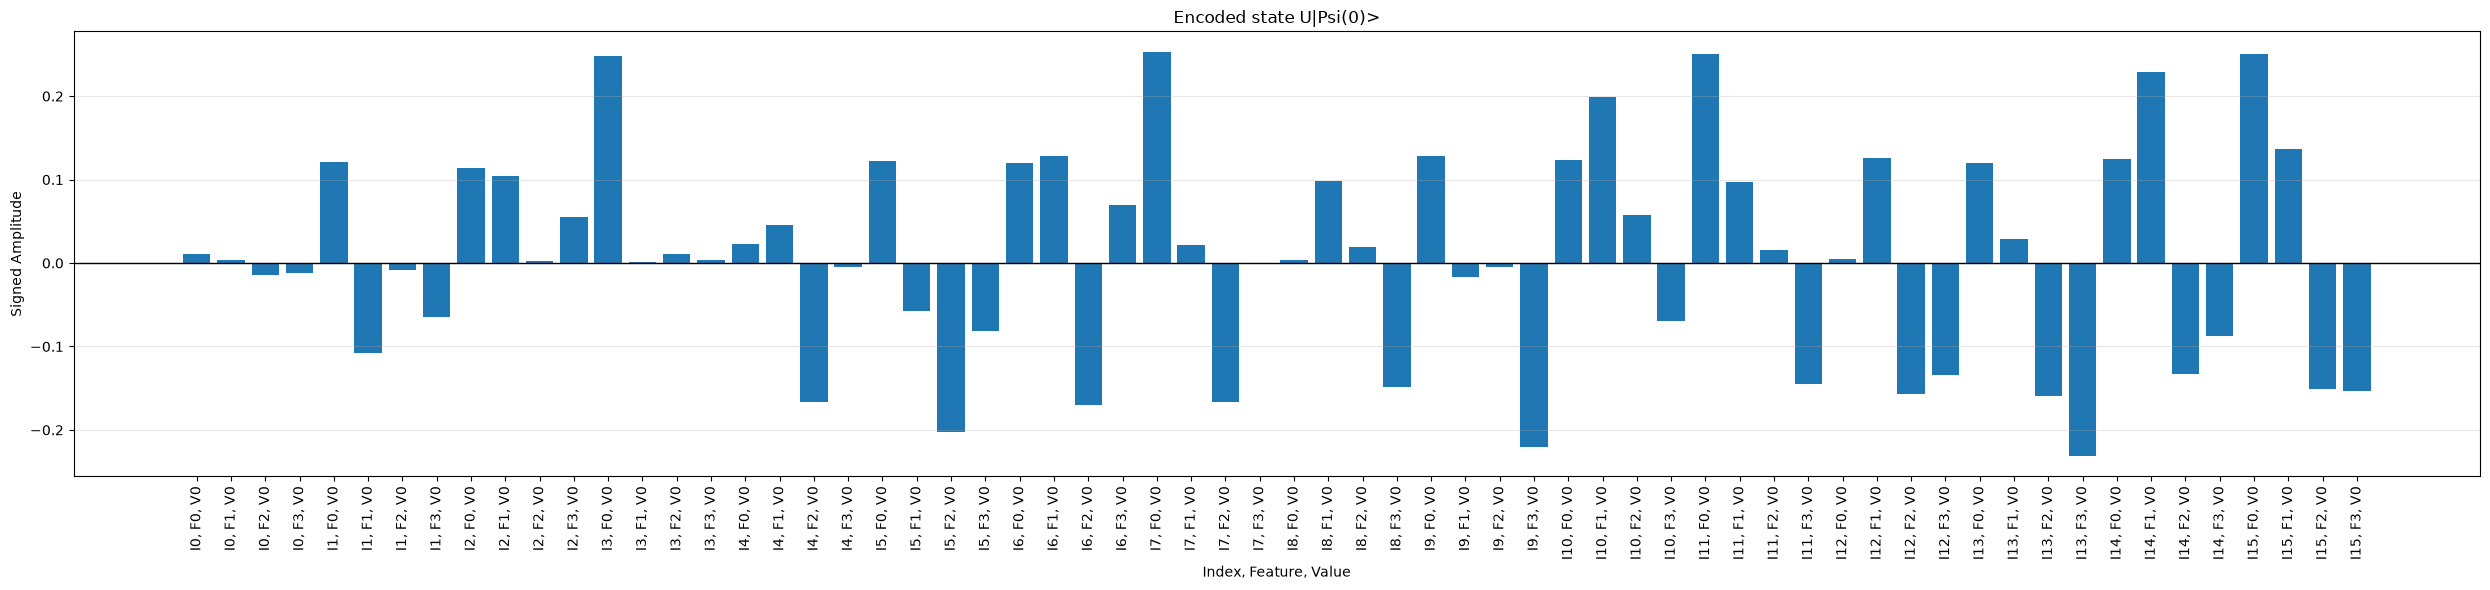


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


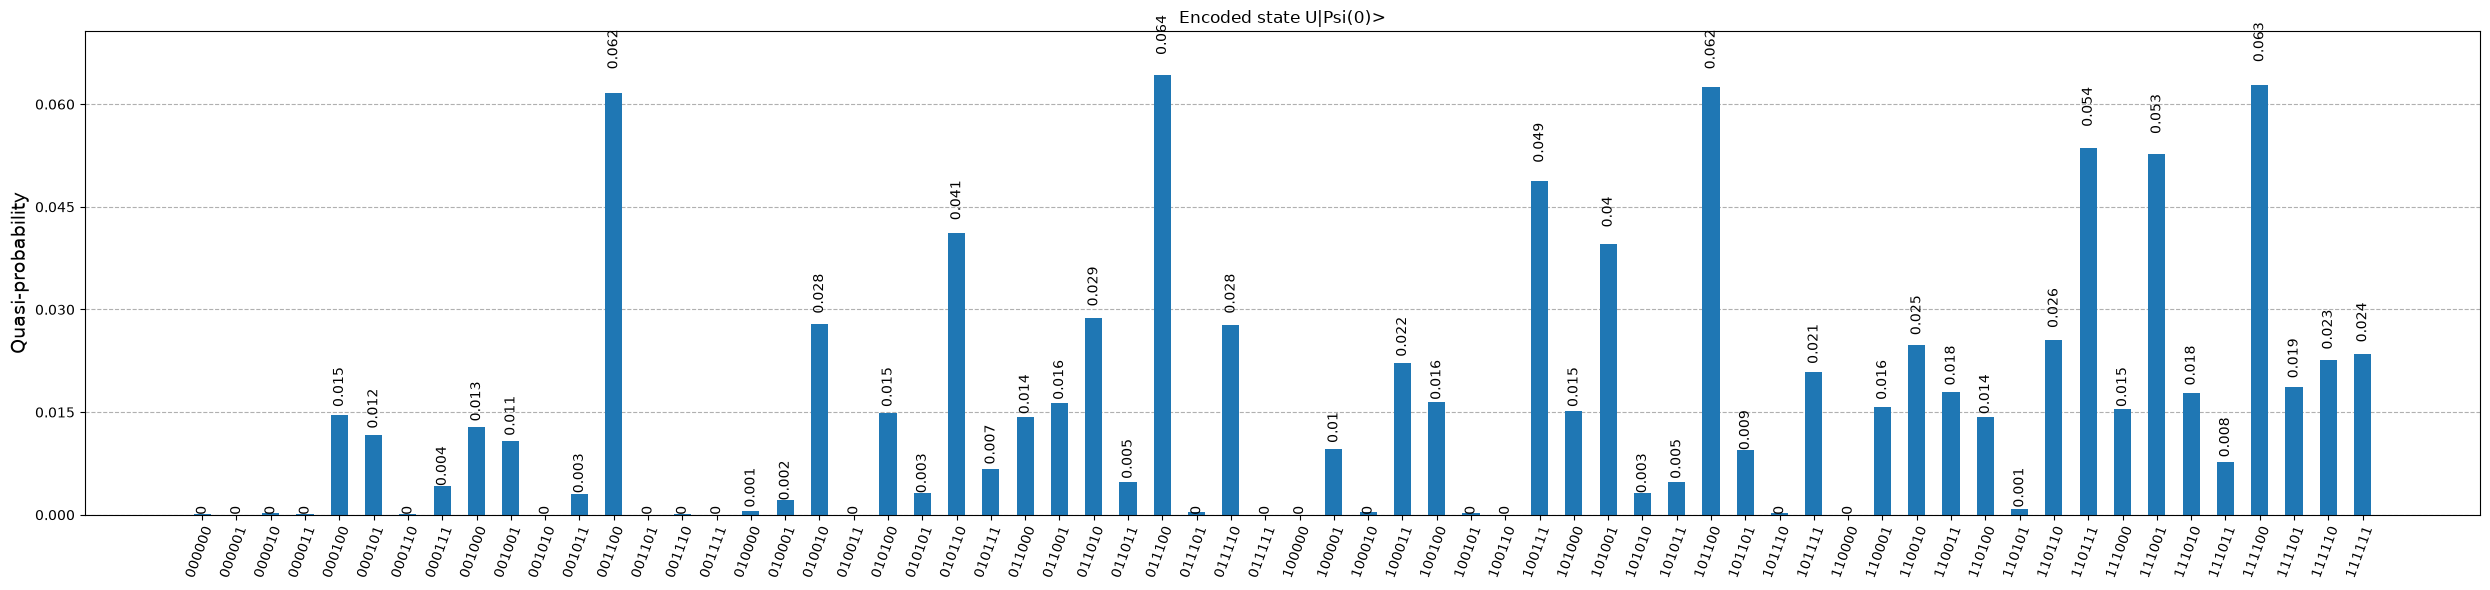

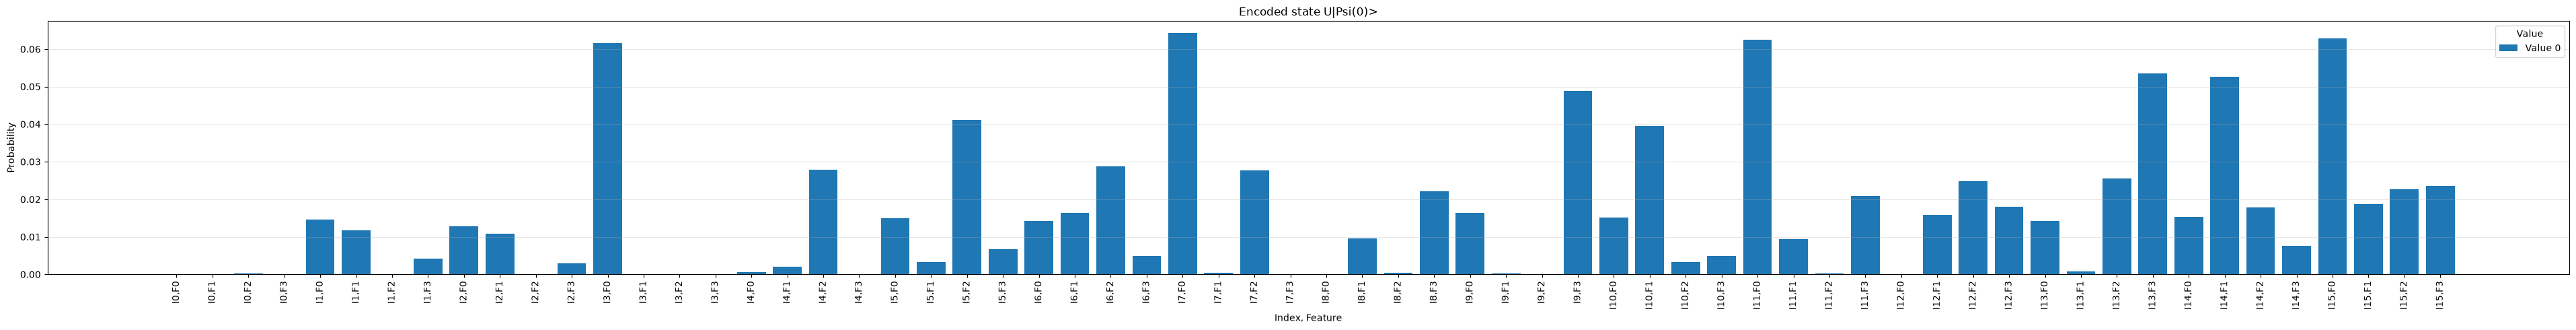


Encoded state U|Psi(0)>
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        +0.010                   
0                        1                        +0.003                   
0                        2                        -0.014                   
0                        3                        -0.012                   
1                        0                        +0.121                   
1                        1                        -0.108                   
1                        2                        -0.009                   
1                        3                        -0.065                   
2                        0                        +0.113                   
2                        1                        +0.104                   
2                        2                        +0.002       

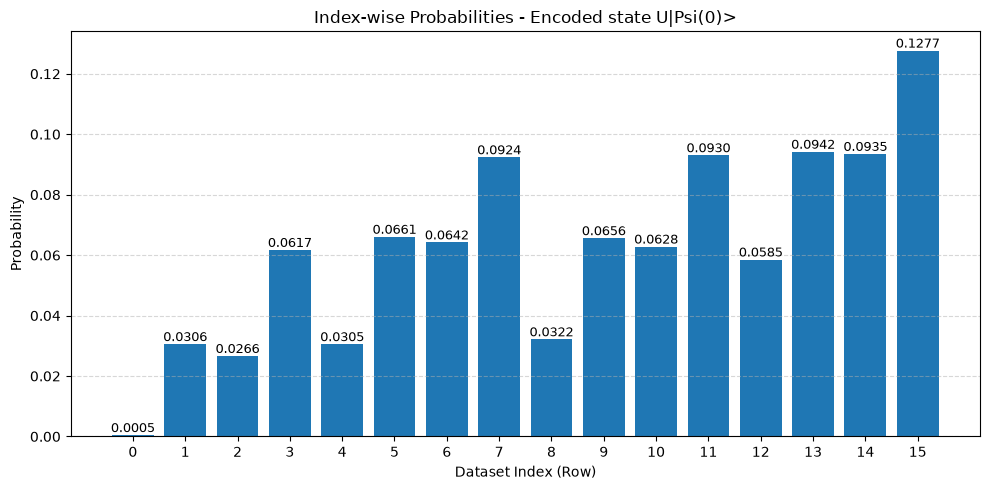




GROVER ITERATION 1


> Oracle: 

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (-0.010449707917117827+0j)
|000001> : (0.0033503484562677536+0j)
|000010> : (-0.013945170653788119+0j)
|000011> : (-0.011976398088534002+0j)
|000100> : (-0.1209612703034055+0j)
|000101> : (-0.1078759110103381+0j)
|000110> : (-0.00878261580333728+0j)
|000111> : (-0.06494736045089973+0j)
|001000> : (-0.1133980590420946+0j)
|001001> : (0.10371709319777189+0j)
|001010> : (0.0018972773034240512+0j)
|001011> : (0.054839141531187775+0j)
|001100> : (-0.2481434938931796+0j)
|001101> : (0.0017503363905883073+0j)
|001110> : (0.01083077750331472+0j)
|001111> : (0.003686018540577908+0j)
|010000> : (-0.023286085199350826+0j)
|010001> : (0.04573762343032737+0j)
|010010> : (-0.16696589297915176+0j)
|010011> : (-0.005155058849176273+0j)
|010100> : (-0.12222088602700143+0j)
|010101> : (-0.05697245140976078+0j)
|010110> : (-0.2029545173850355+0j)
|010111> : (-0.08179821077602535+0j)
|011000> : (-0.11935738988999112+0j)
|011001> : (0.12768437360797688+0j)
|011010> 

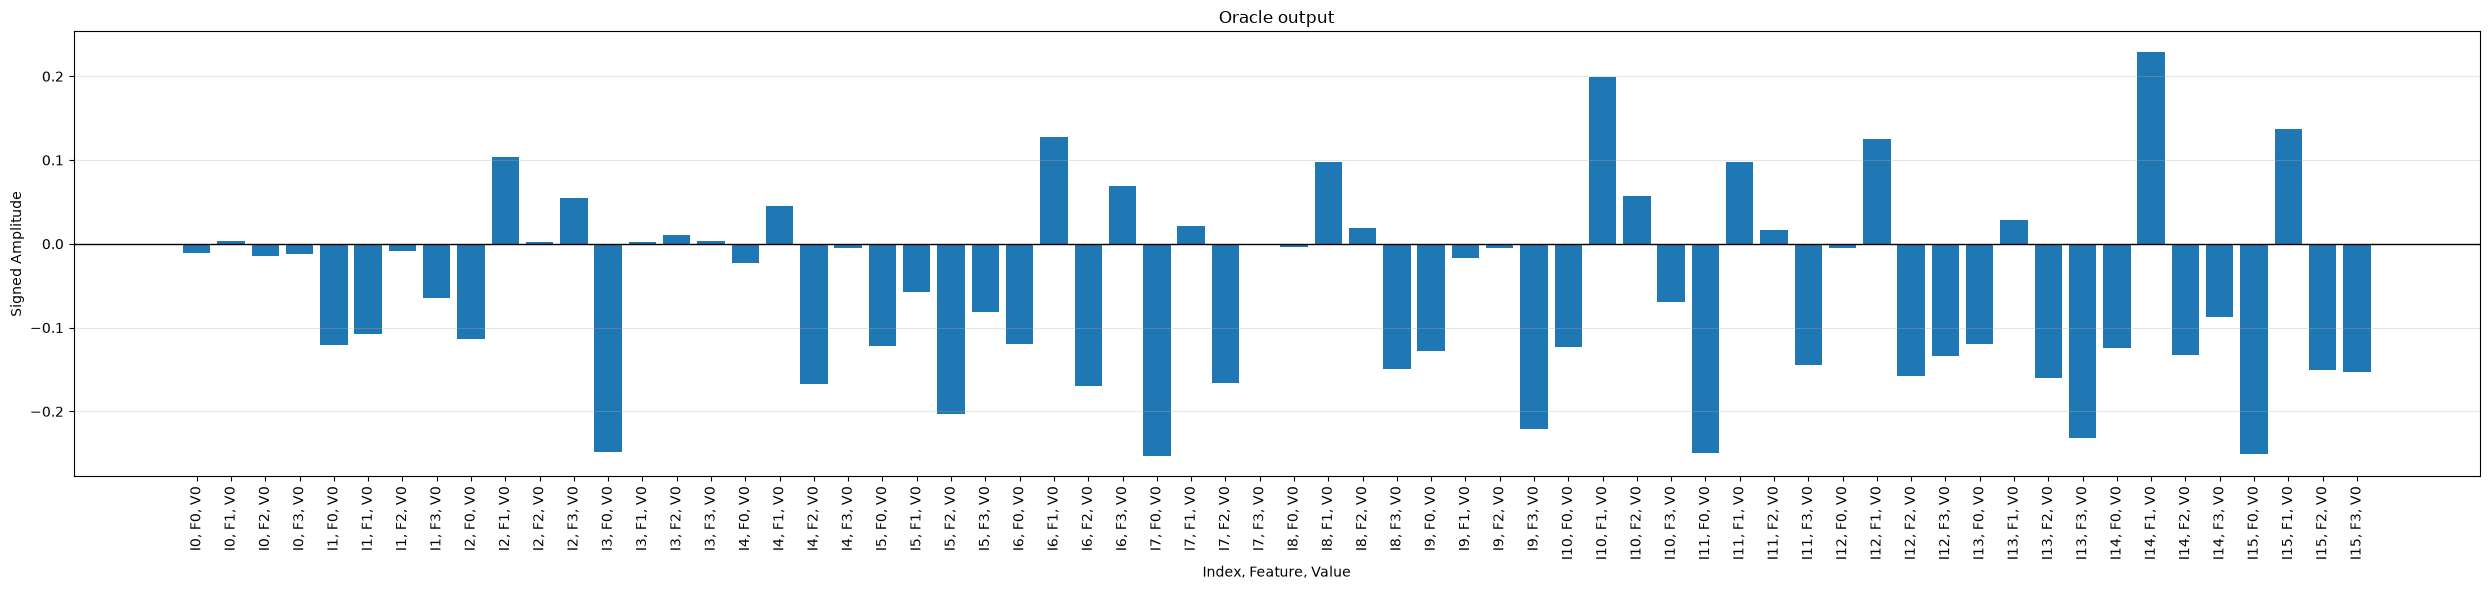


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


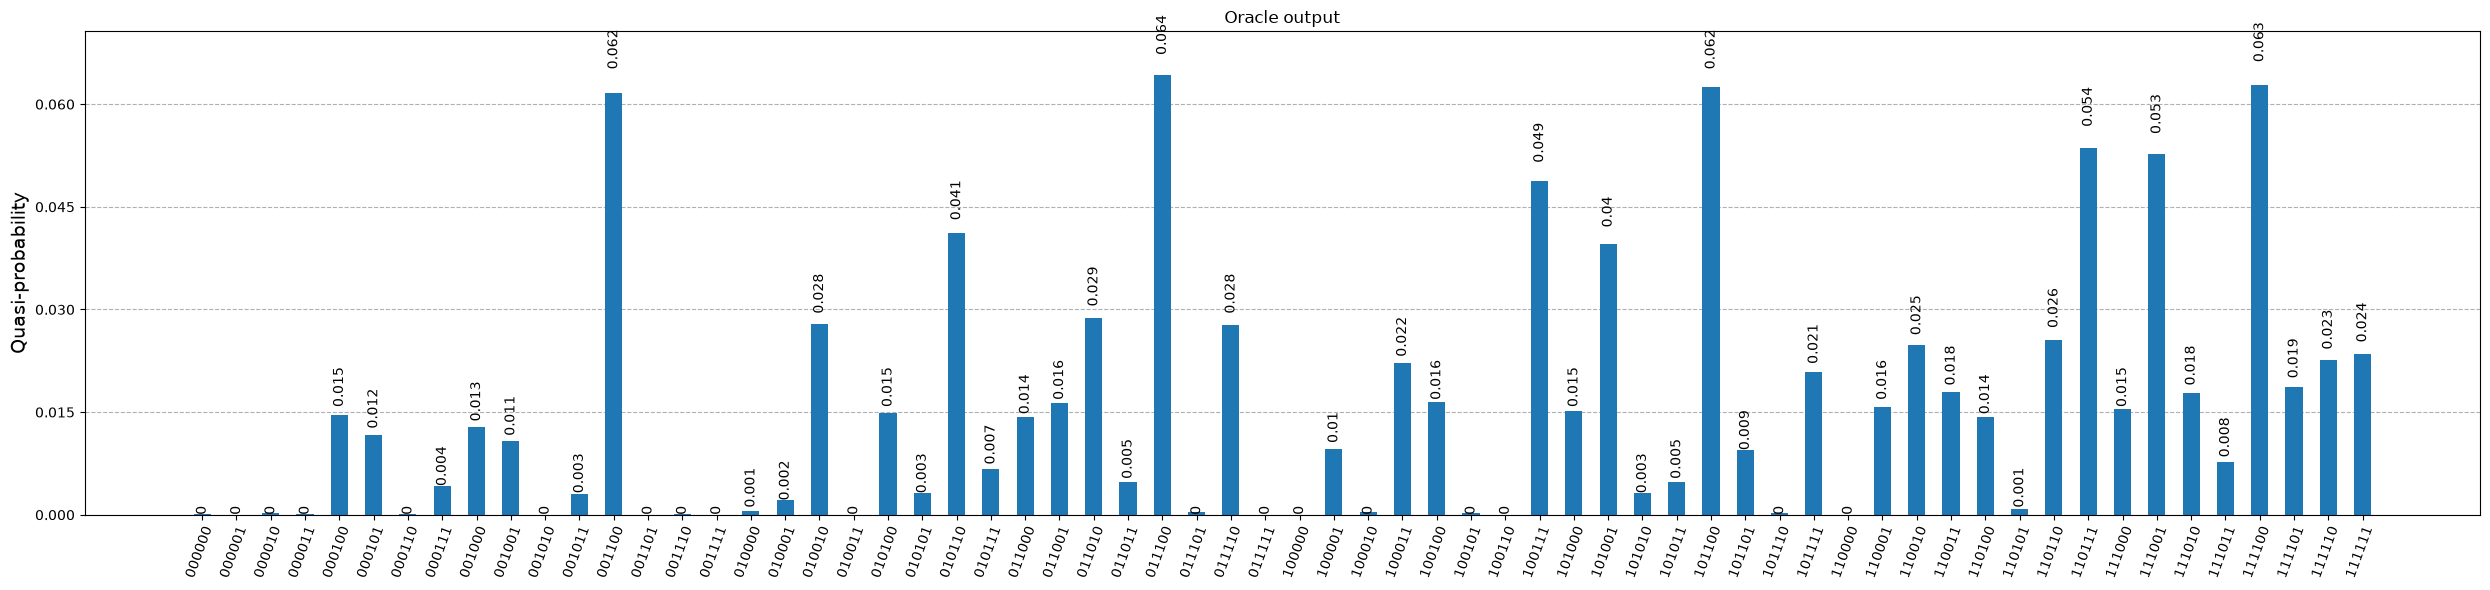

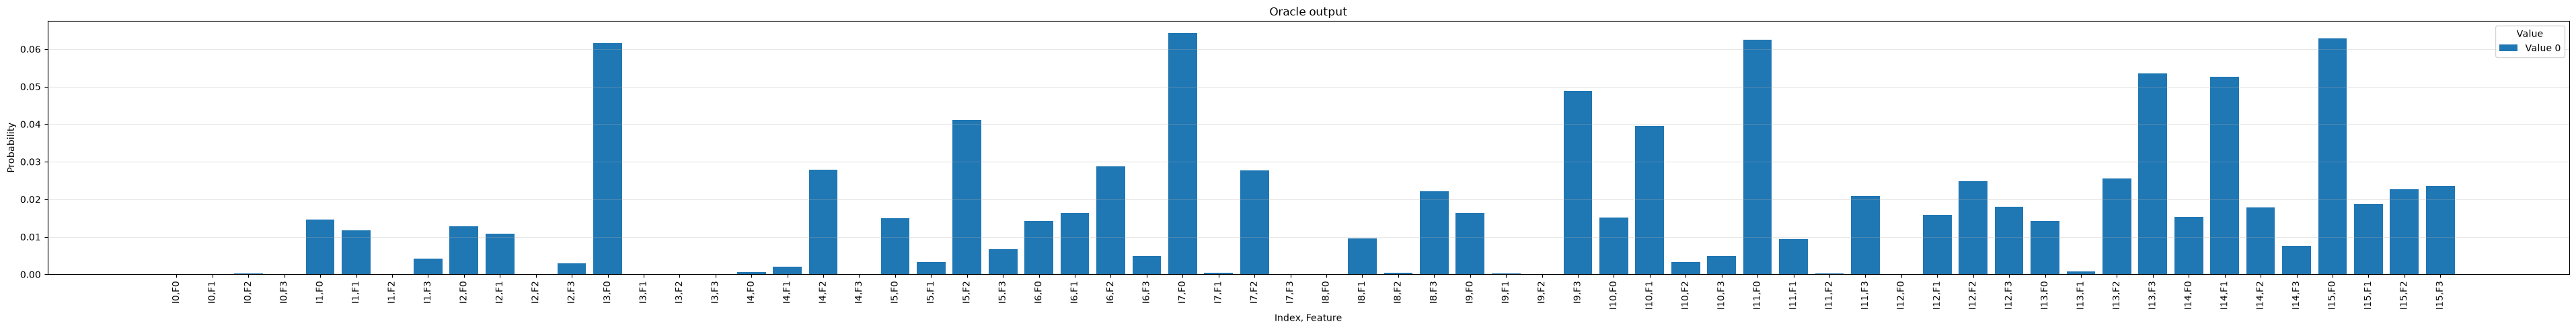


Oracle output
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        -0.010                   
0                        1                        +0.003                   
0                        2                        -0.014                   
0                        3                        -0.012                   
1                        0                        -0.121                   
1                        1                        -0.108                   
1                        2                        -0.009                   
1                        3                        -0.065                   
2                        0                        -0.113                   
2                        1                        +0.104                   
2                        2                        +0.002                 

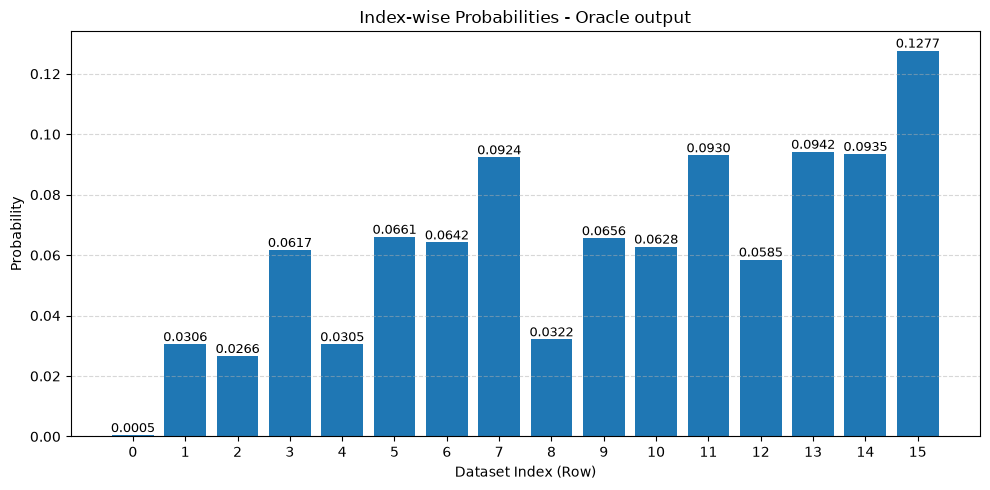



> Diffuser: 
Applying inverse of U...

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (-0.015891214699408716+2.4173998047094952e-17j)
|000001> : (0.0016057117647529202+1.3016787317252573e-17j)
|000010> : (-0.006683461398882816+1.601613337638789e-17j)
|000011> : (-0.0057398934950020335+1.5222129940541927e-18j)
|000100> : (-0.1839497842380645-1.7230941742781912e-17j)
|000101> : (-0.05170137426113582+2.4940562415694816e-17j)
|000110> : (-0.004209218743901064+2.2636187589756518e-18j)
|000111> : (-0.03112713263318891-1.4279681940546046e-17j)
|001000> : (-0.17244815998944846-9.253765757915306e-18j)
|001001> : (0.049708189738311495+1.3178147926684305e-17j)
|001010> : (0.0009093025775893208+1.1489162643125576e-17j)
|001011> : (0.026282595937397346+9.29055898016159e-18j)
|001100> : (-0.37735997685239897-3.7726224886660564e-17j)
|001101> : (0.0008388786334700498+8.396839658063847e-18j)
|001110> : (0.005190835247586713+1.042001585450326e-17j)
|001111> : (0.0017665873902253742-2.1864926920807753e-17j)
|010000> : (-0.035411916040775517-3.4977

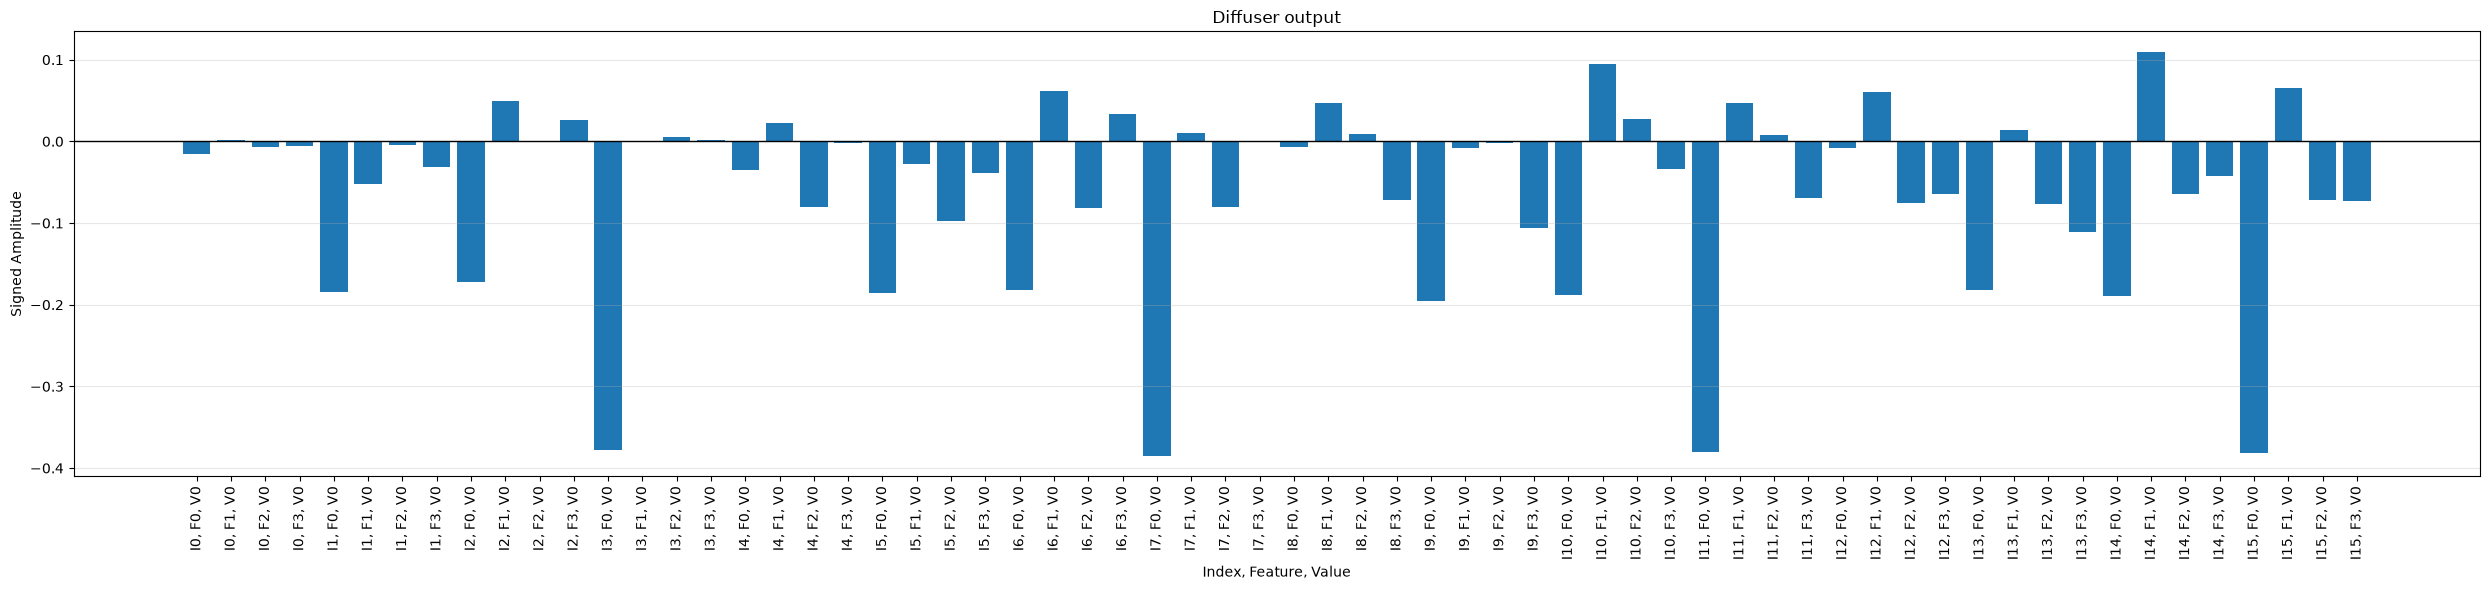


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


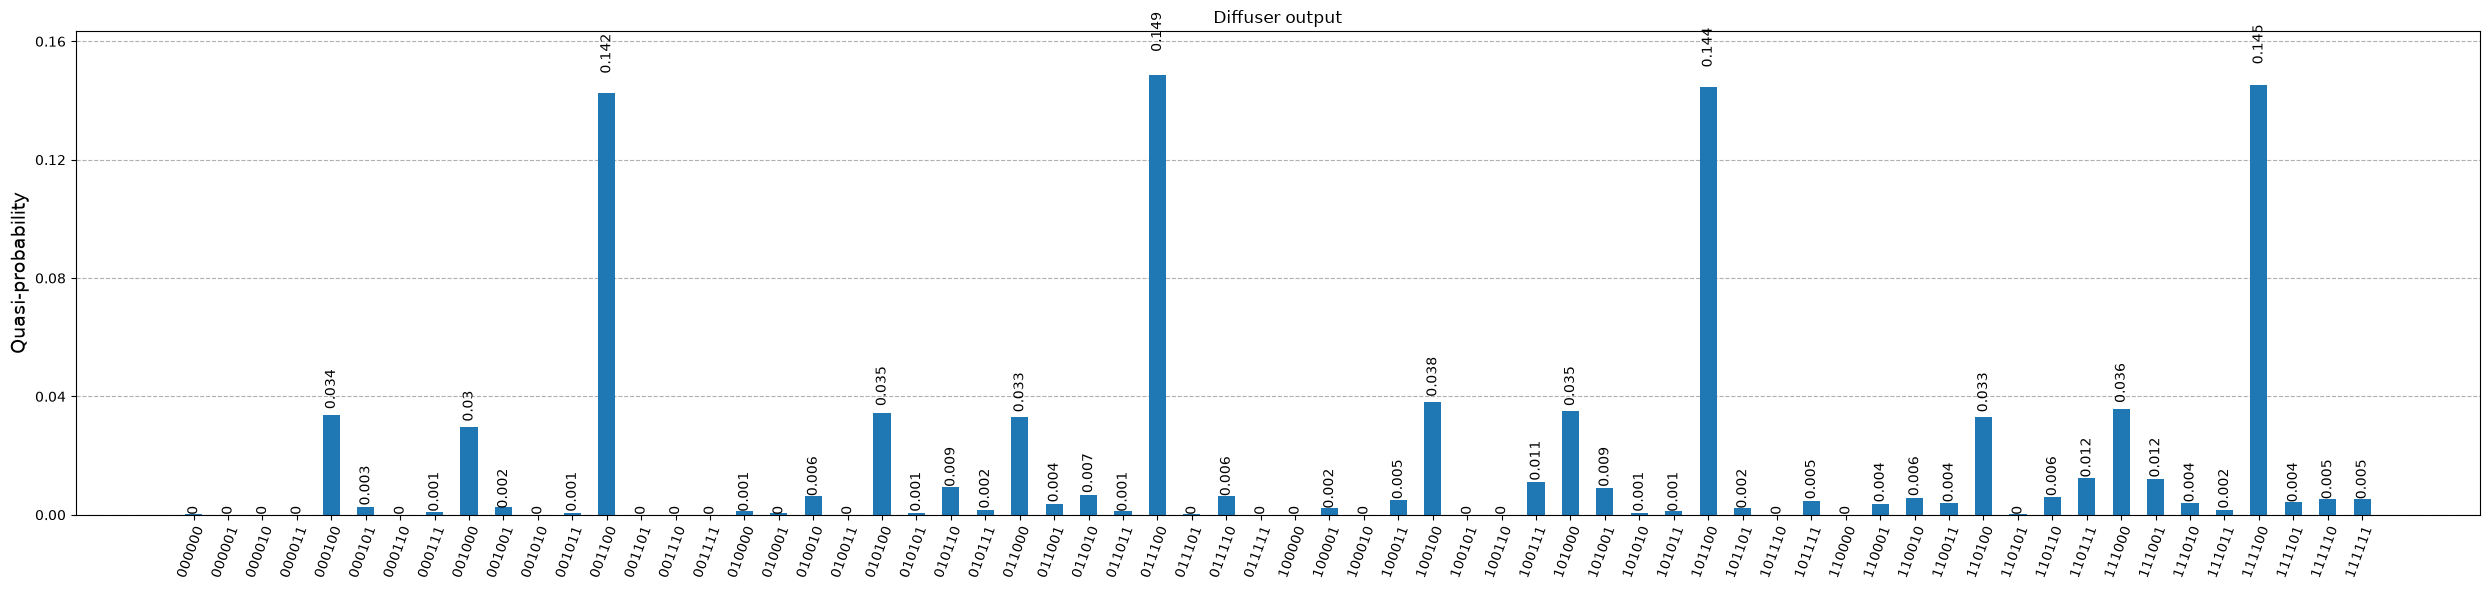

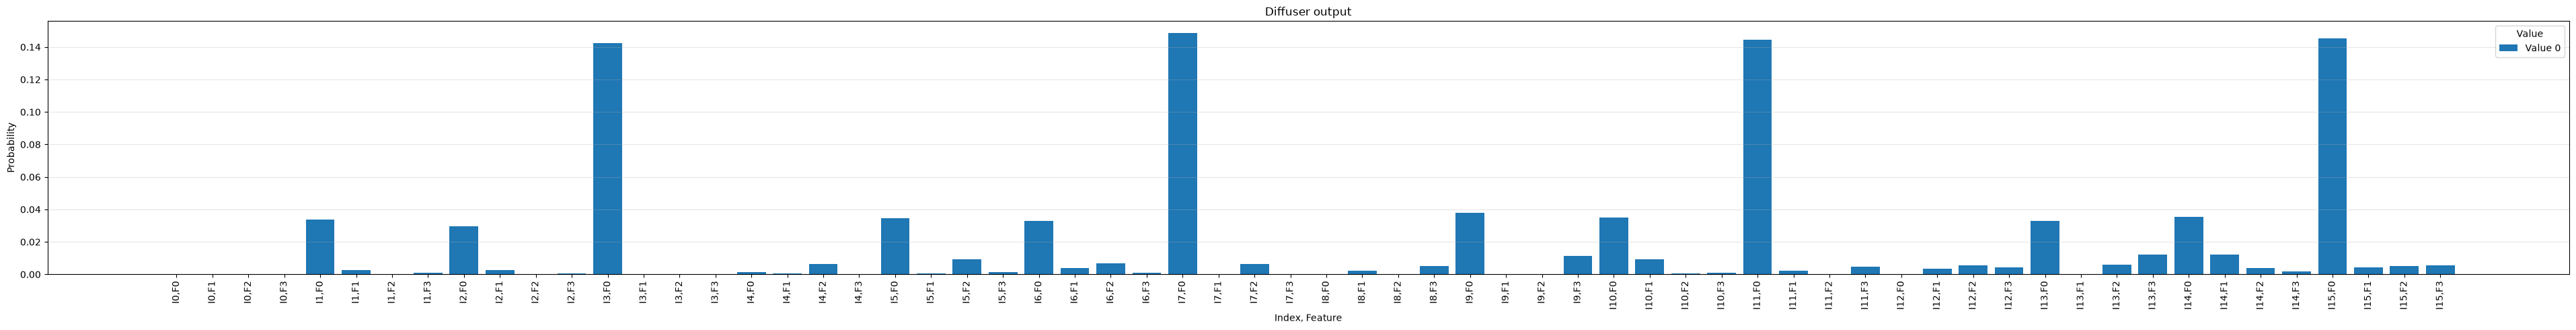


Diffuser output
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        -0.016                   
0                        1                        +0.002                   
0                        2                        -0.007                   
0                        3                        -0.006                   
1                        0                        -0.184                   
1                        1                        -0.052                   
1                        2                        -0.004                   
1                        3                        -0.031                   
2                        0                        -0.172                   
2                        1                        +0.050                   
2                        2                        +0.001               

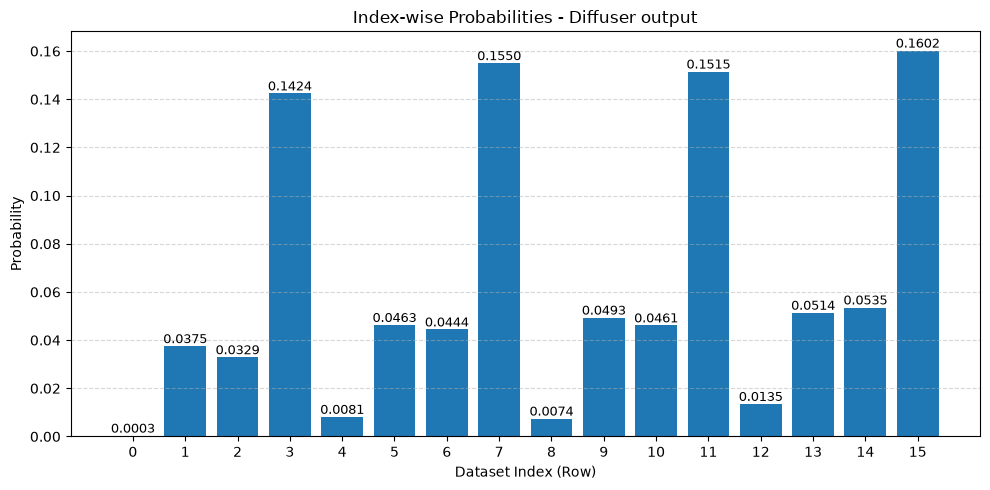




GROVER ITERATION 2


> Oracle: 

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (0.015891214699408712-2.417399804709495e-17j)
|000001> : (0.00160571176475292+1.3016787317252571e-17j)
|000010> : (-0.006683461398882815+1.601613337638789e-17j)
|000011> : (-0.005739893495002033+1.5222129940541929e-18j)
|000100> : (0.1839497842380645+1.723094174278191e-17j)
|000101> : (-0.051701374261135816+2.4940562415694813e-17j)
|000110> : (-0.004209218743901054+2.263618758975651e-18j)
|000111> : (-0.031127132633188906-1.4279681940546043e-17j)
|001000> : (0.17244815998944843+9.253765757915304e-18j)
|001001> : (0.04970818973831149+1.3178147926684303e-17j)
|001010> : (0.0009093025775893153+1.1489162643125574e-17j)
|001011> : (0.02628259593739734+9.29055898016159e-18j)
|001100> : (0.3773599768523989+3.772622488666056e-17j)
|001101> : (0.0008388786334700497+8.396839658063845e-18j)
|001110> : (0.005190835247586692+1.0420015854503256e-17j)
|001111> : (0.0017665873902253737-2.186492692080775e-17j)
|010000> : (0.03541191604077551+3.497704796642096e-1

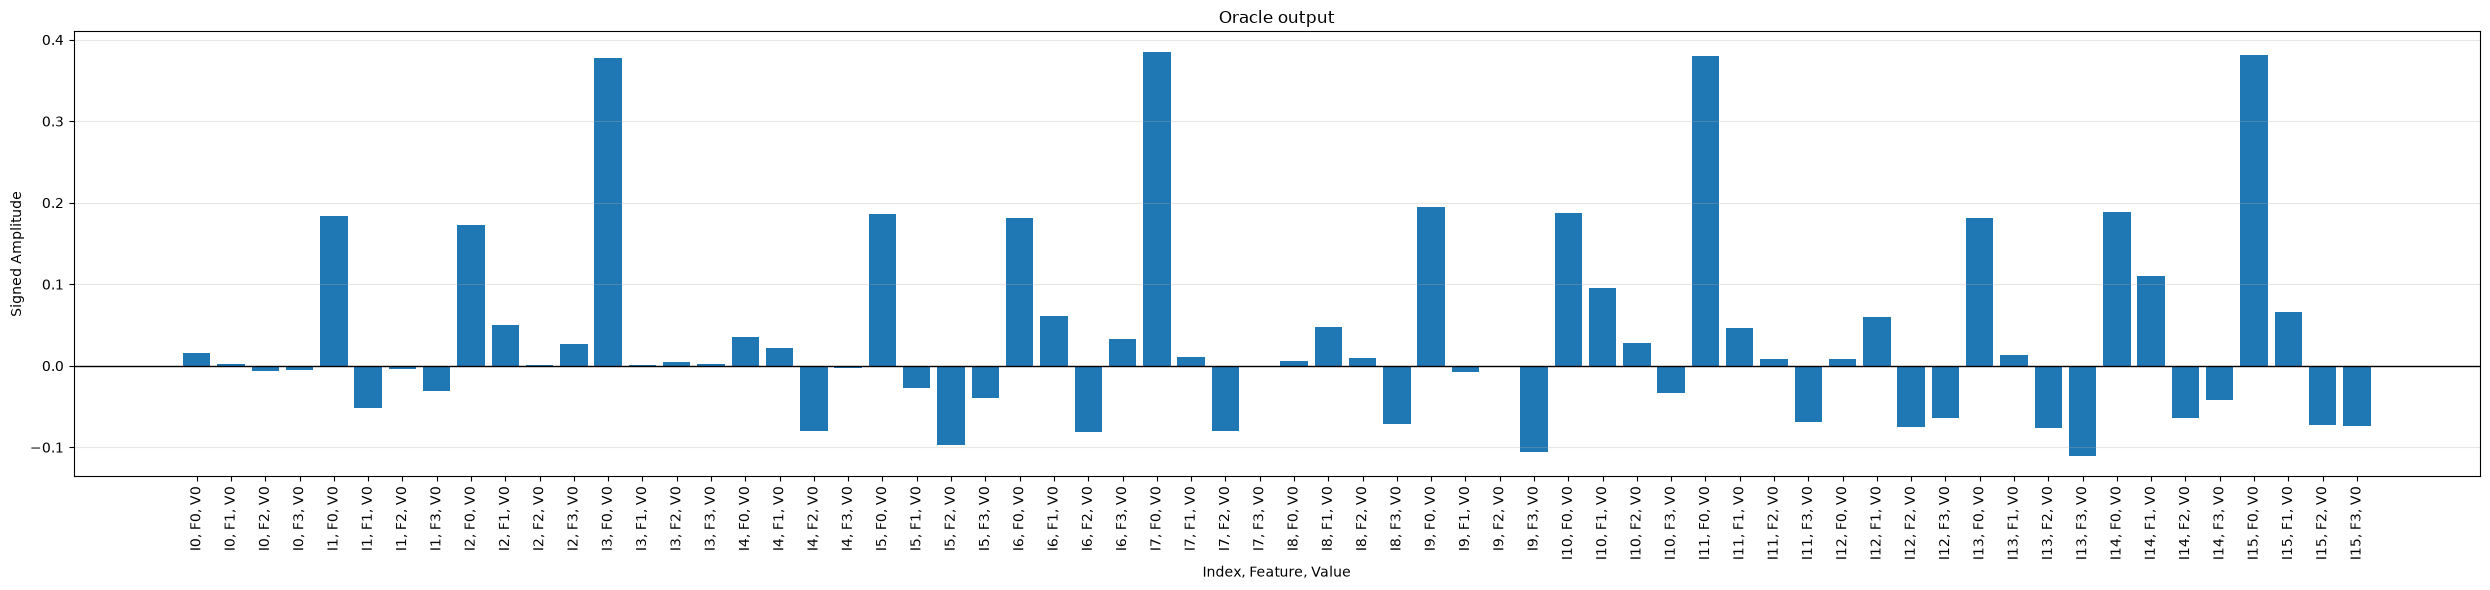


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


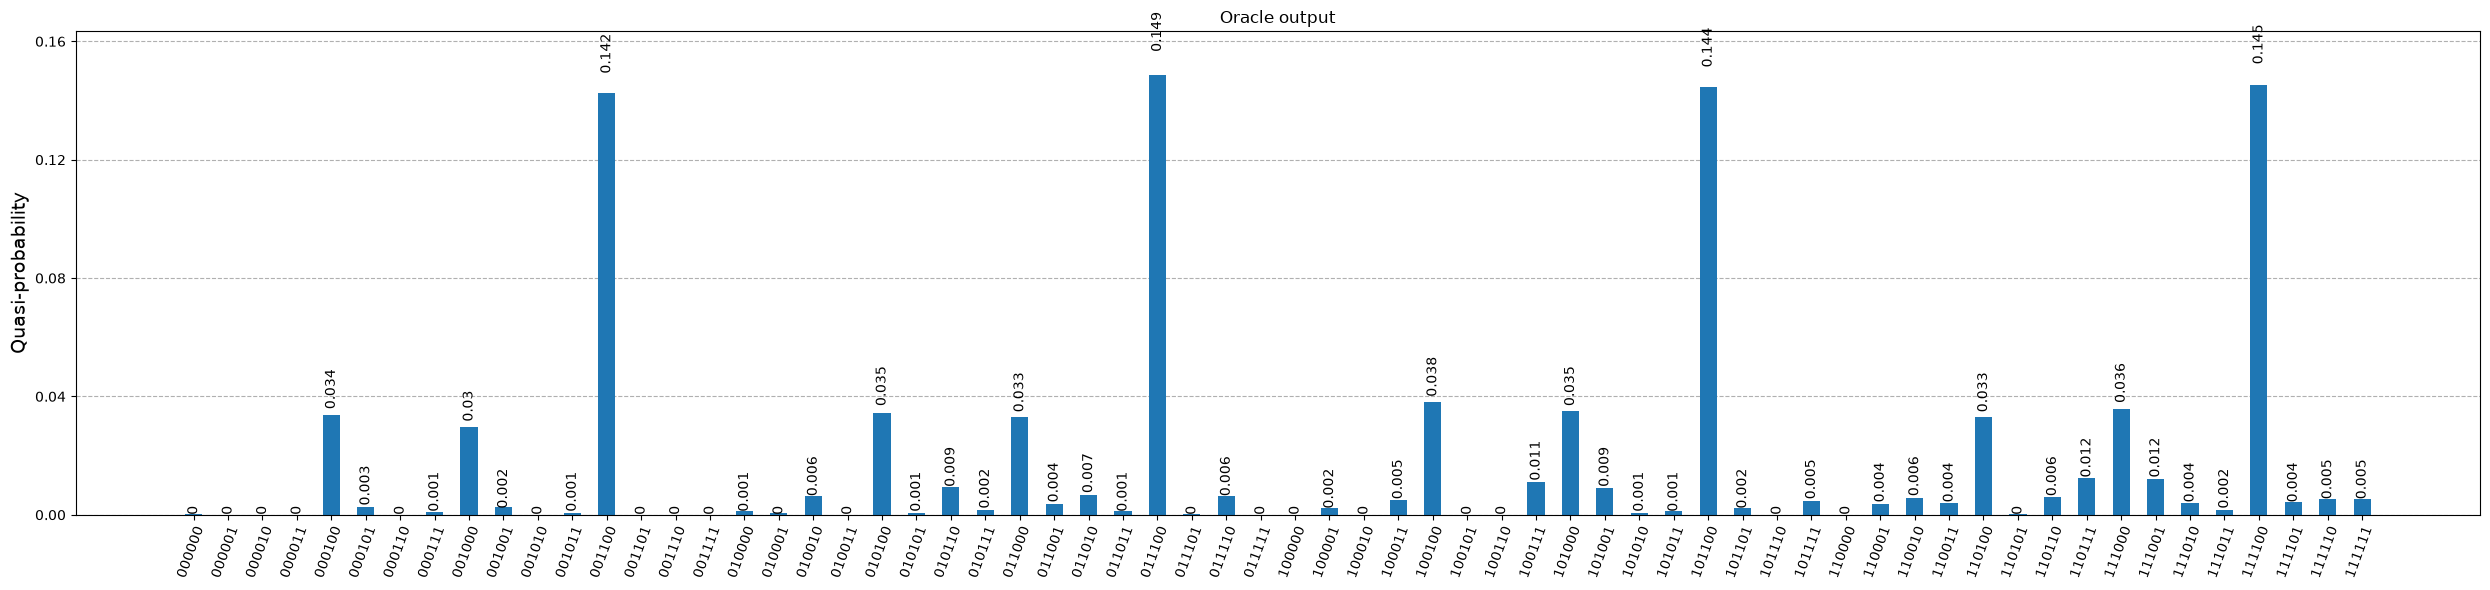

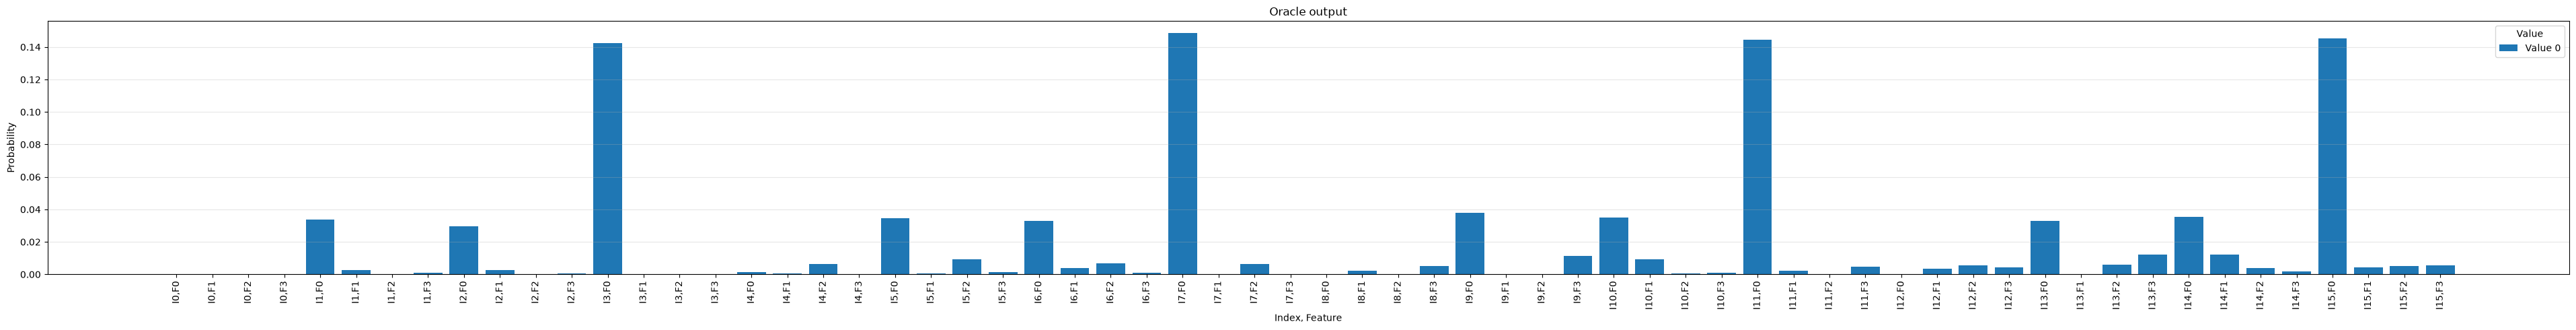


Oracle output
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        +0.016                   
0                        1                        +0.002                   
0                        2                        -0.007                   
0                        3                        -0.006                   
1                        0                        +0.184                   
1                        1                        -0.052                   
1                        2                        -0.004                   
1                        3                        -0.031                   
2                        0                        +0.172                   
2                        1                        +0.050                   
2                        2                        +0.001                 

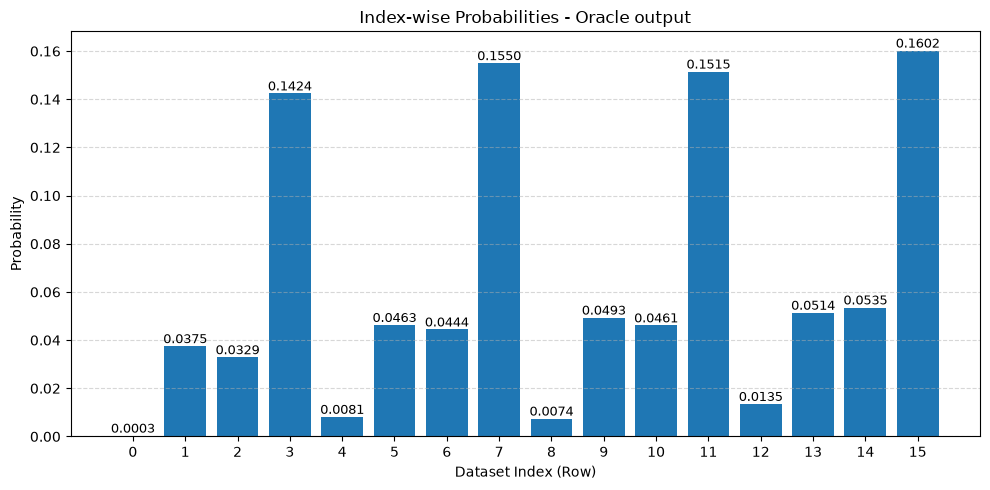



> Diffuser: 
Applying inverse of U...

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (-0.0021746294889425496-2.760795966198255e-17j)
|000001> : (-0.004186495411532498+2.218969139279883e-17j)
|000010> : (0.017425468937687785-1.1012751647807207e-17j)
|000011> : (0.014965349514775572-3.309163174461406e-17j)
|000100> : (-0.02517256439204828+9.121096098320154e-18j)
|000101> : (0.13479851793171085+1.0279890417849689e-17j)
|000110> : (0.010974494516574639-2.0164506285518564e-17j)
|000111> : (0.08115628271745369+1.556430581439682e-17j)
|001000> : (-0.023598627362382166-9.654866939790413e-18j)
|001001> : (-0.12960178334813724+1.9756775865920195e-17j)
|001010> : (-0.002370781078108462+1.1000631623104595e-17j)
|001011> : (-0.0685253541204671+4.4698678631853686e-18j)
|001100> : (-0.05163973611409791+7.268377605429181e-18j)
|001101> : (-0.0021871681001204893+6.389445718108918e-18j)
|001110> : (-0.013533816232198688-1.8700056736142223e-17j)
|001111> : (-0.0046059387279802876-3.3440715121713936e-17j)
|010000> : (-0.004845935212561054+5.7752980

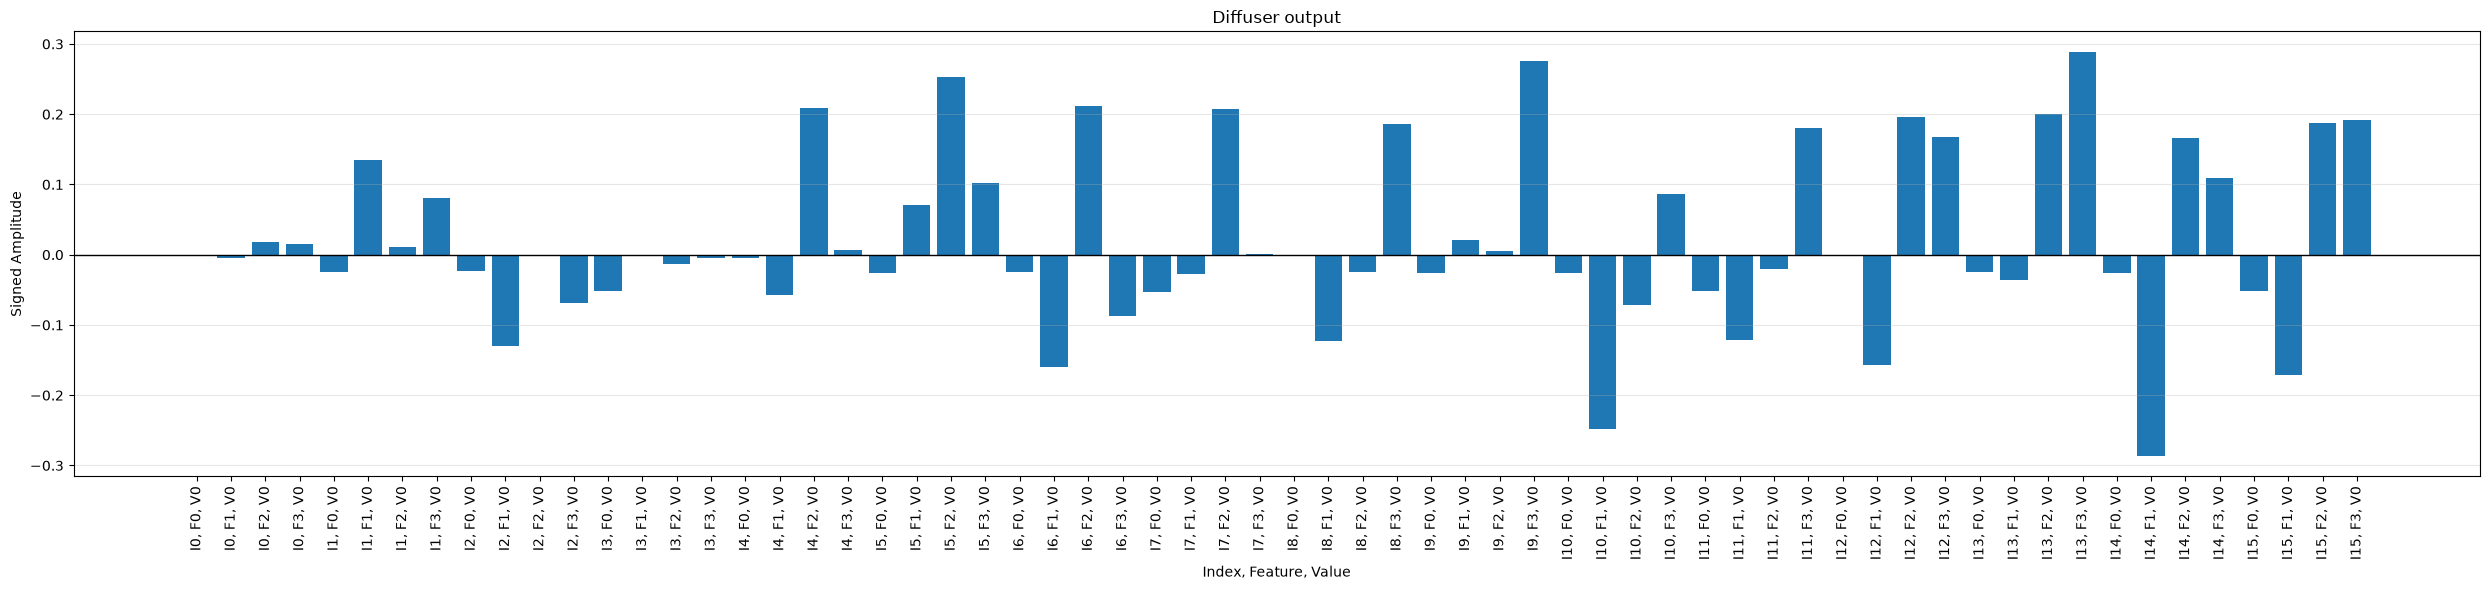


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


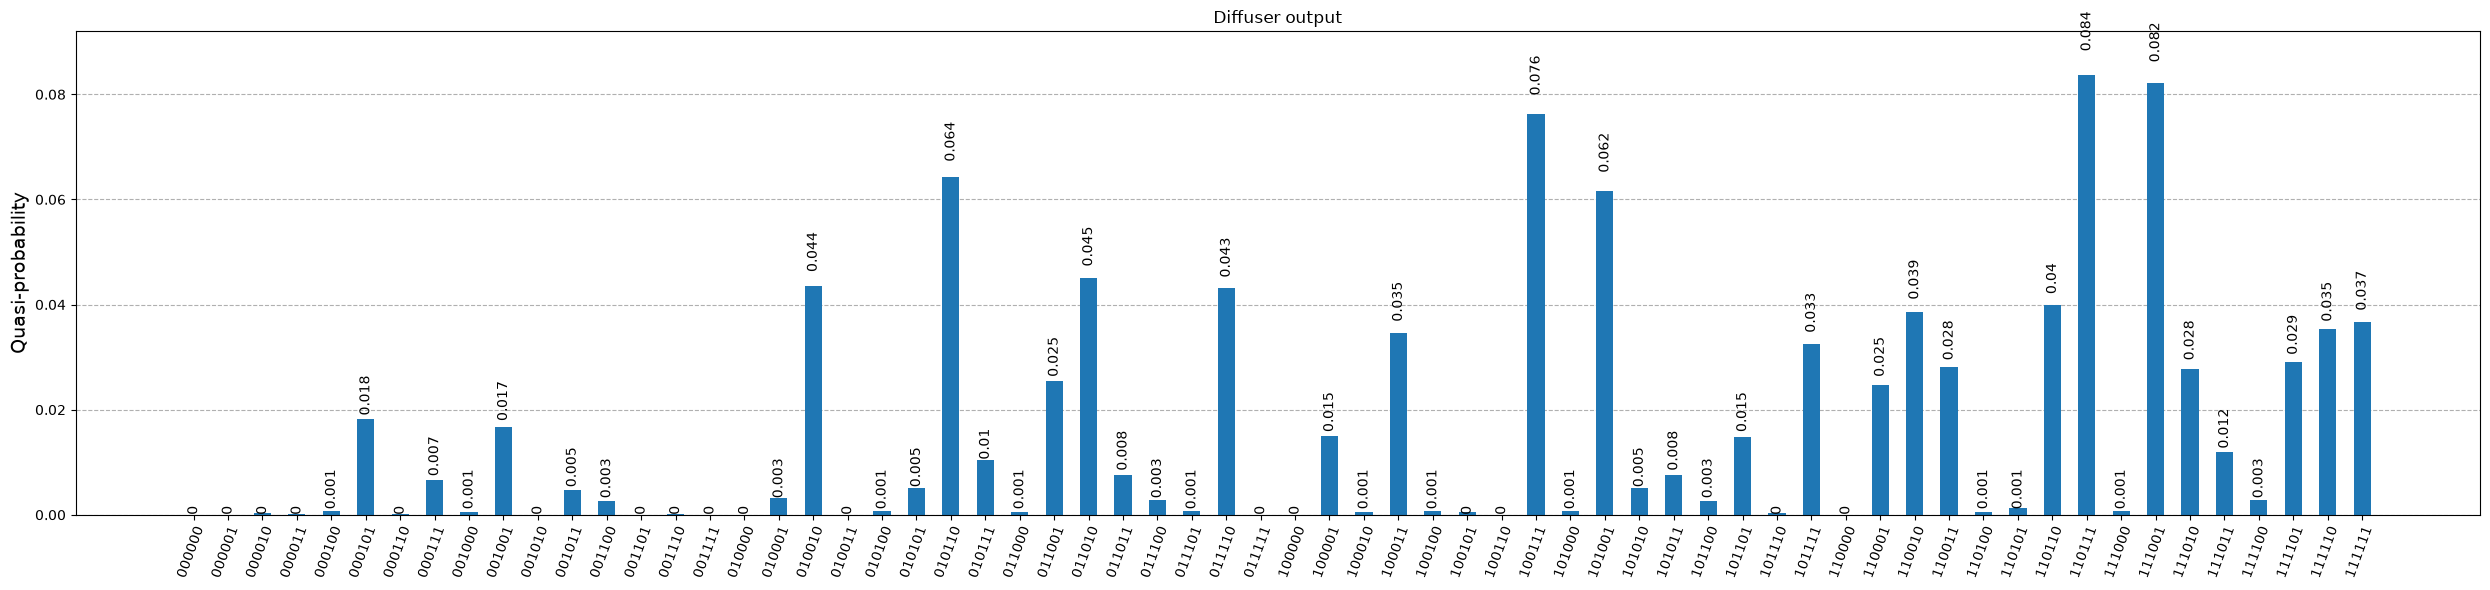

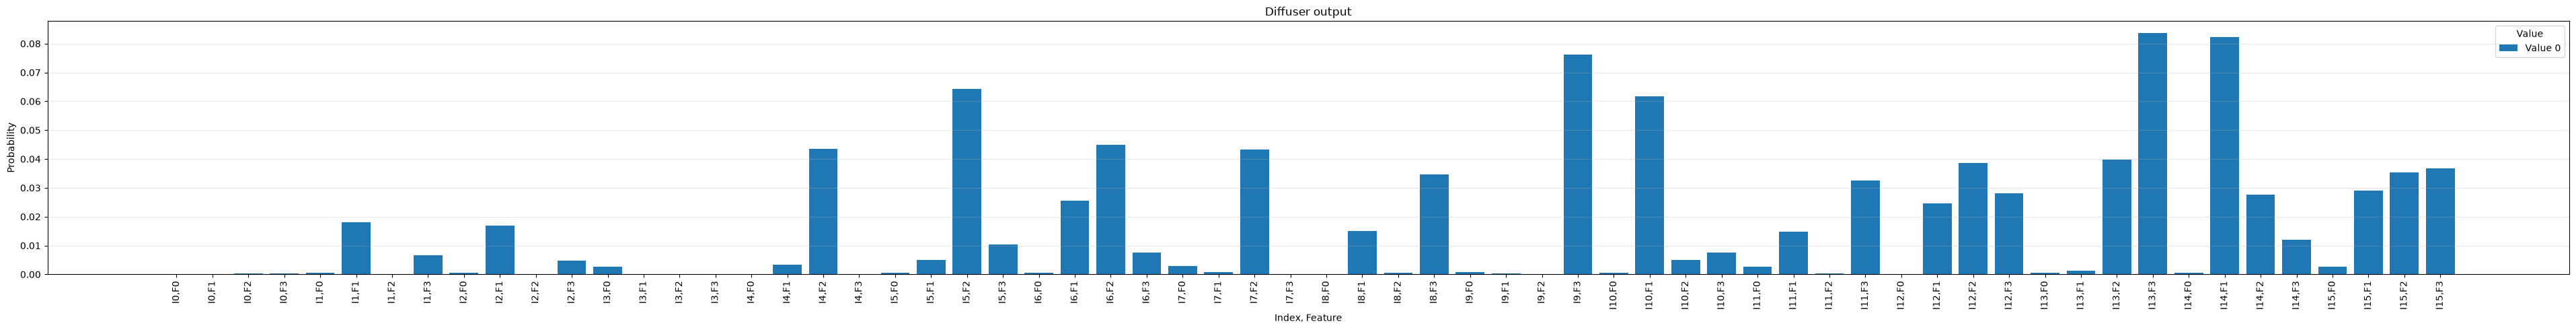


Diffuser output
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        -0.002                   
0                        1                        -0.004                   
0                        2                        +0.017                   
0                        3                        +0.015                   
1                        0                        -0.025                   
1                        1                        +0.135                   
1                        2                        +0.011                   
1                        3                        +0.081                   
2                        0                        -0.024                   
2                        1                        -0.130                   
2                        2                        -0.002               

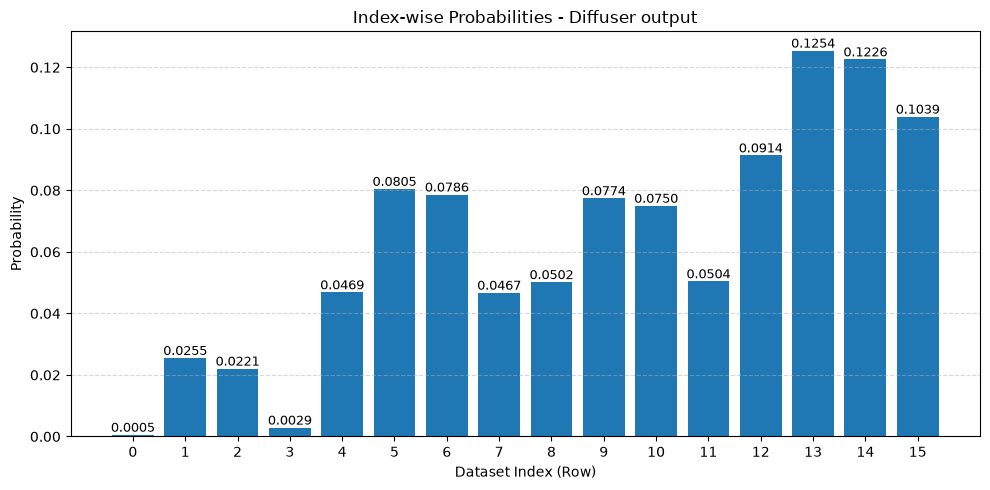




GROVER ITERATION 3


> Oracle: 

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (0.002174629488942548+2.7607959661982548e-17j)
|000001> : (-0.004186495411532498+2.2189691392798828e-17j)
|000010> : (0.01742546893768778-1.1012751647807206e-17j)
|000011> : (0.014965349514775569-3.3091631744614057e-17j)
|000100> : (0.025172564392048274-9.12109609832015e-18j)
|000101> : (0.13479851793171083+1.0279890417849686e-17j)
|000110> : (0.010974494516574635-2.016450628551856e-17j)
|000111> : (0.08115628271745366+1.5564305814396818e-17j)
|001000> : (0.023598627362382163+9.654866939790412e-18j)
|001001> : (-0.1296017833481372+1.9756775865920192e-17j)
|001010> : (-0.002370781078108463+1.1000631623104594e-17j)
|001011> : (-0.06852535412046709+4.4698678631853686e-18j)
|001100> : (0.0516397361140979-7.268377605429181e-18j)
|001101> : (-0.002187168100120489+6.389445718108917e-18j)
|001110> : (-0.013533816232198686-1.870005673614222e-17j)
|001111> : (-0.004605938727980287-3.344071512171393e-17j)
|010000> : (0.00484593521256105-5.775298050484237e-

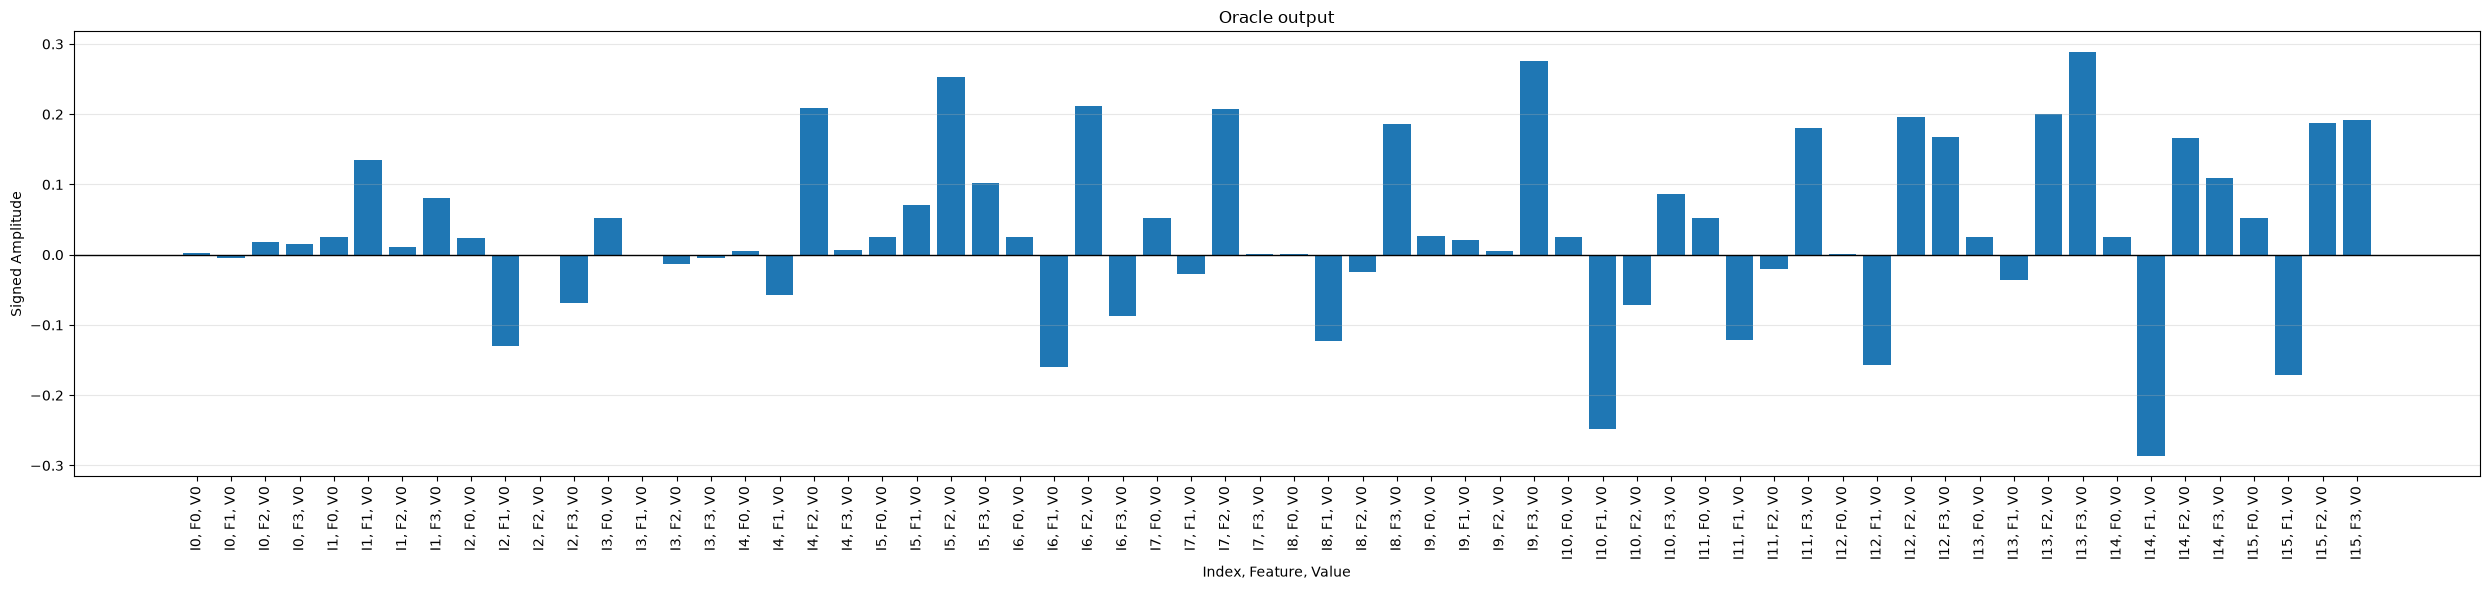


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


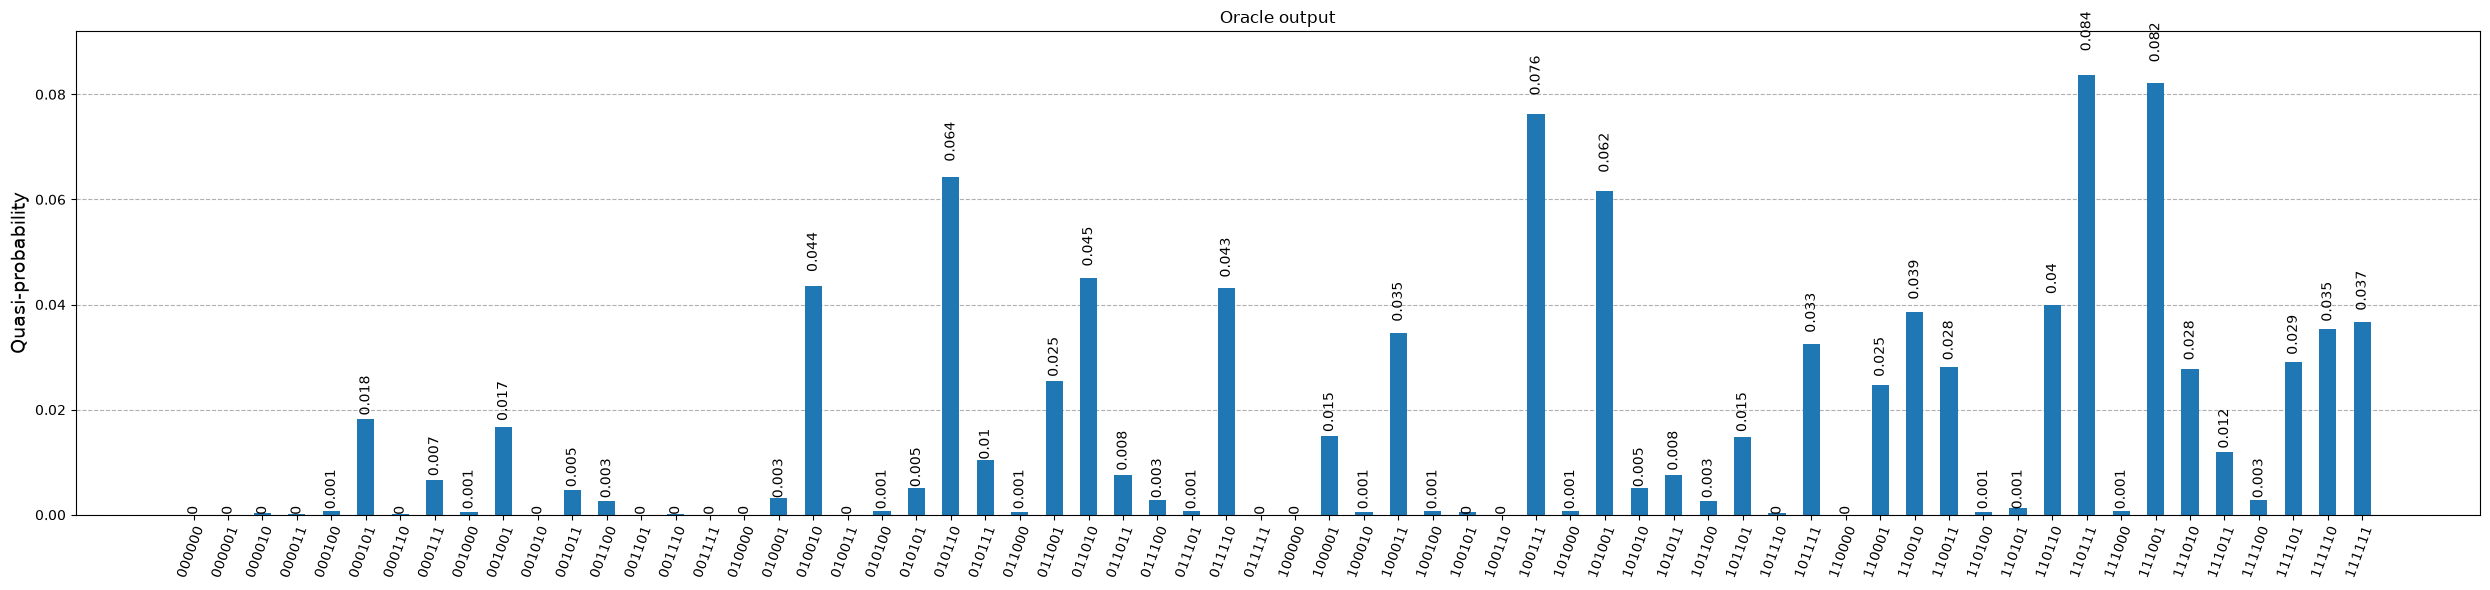

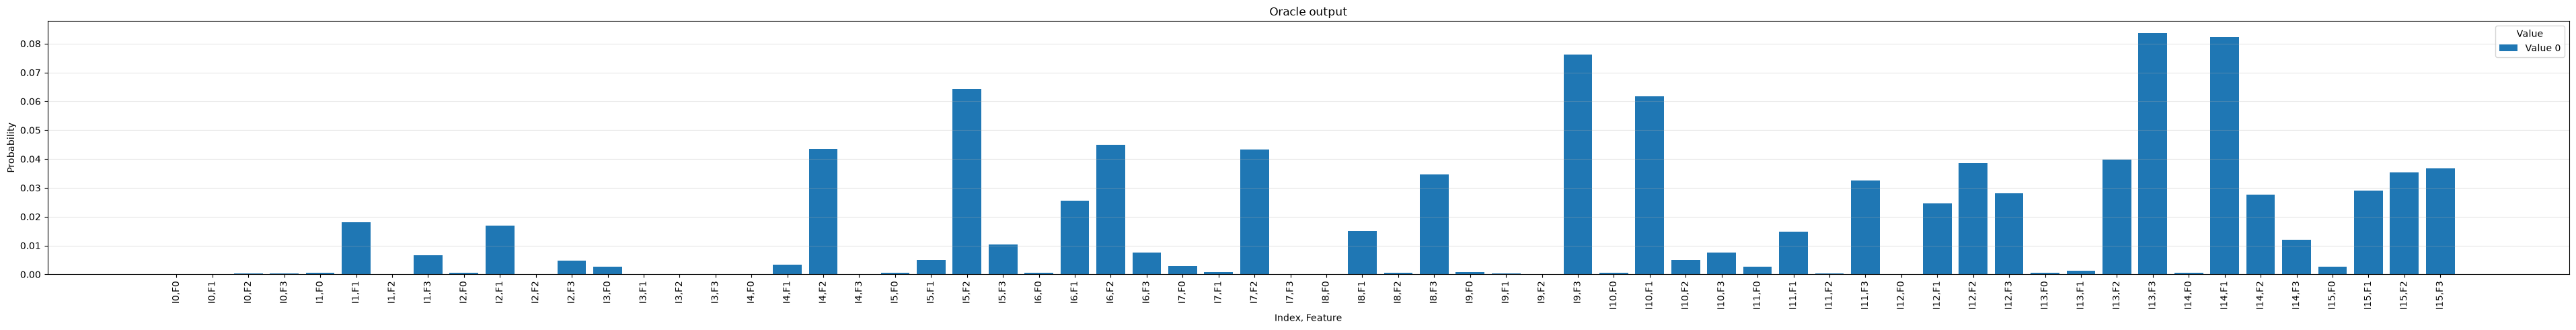


Oracle output
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        +0.002                   
0                        1                        -0.004                   
0                        2                        +0.017                   
0                        3                        +0.015                   
1                        0                        +0.025                   
1                        1                        +0.135                   
1                        2                        +0.011                   
1                        3                        +0.081                   
2                        0                        +0.024                   
2                        1                        -0.130                   
2                        2                        -0.002                 

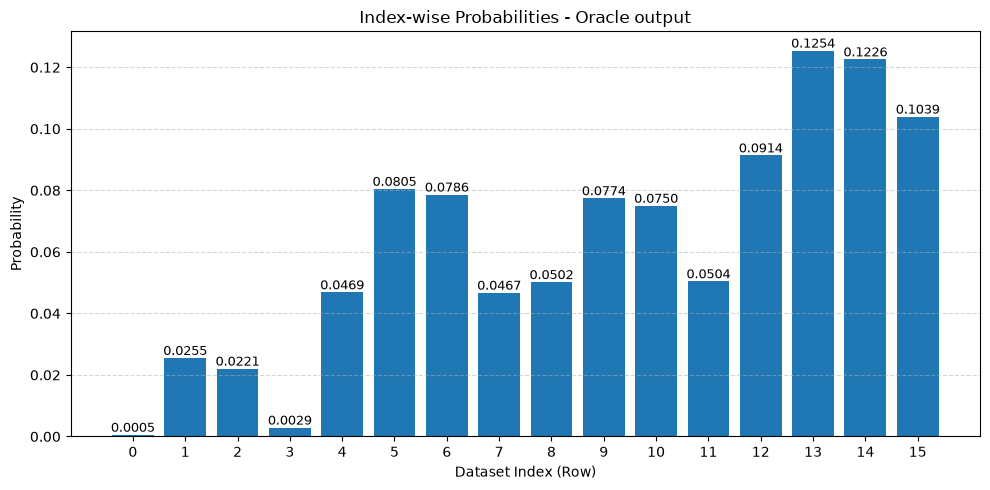



> Diffuser: 
Applying inverse of U...

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (0.017023615835105976+2.3798691177674318e-17j)
|000001> : (0.0005743341615614396+3.0704177114186655e-17j)
|000010> : (-0.0023905536990606316-8.17497021133805e-18j)
|000011> : (-0.002053056463973111-5.994396354654087e-17j)
|000100> : (0.19705796687373228+7.108860991143312e-17j)
|000101> : (-0.01849264985762373+2.5449206182361125e-17j)
|000110> : (-0.0015055616899457107-6.564363028943301e-17j)
|000111> : (-0.011133614397752628-1.9661369346319306e-17j)
|001000> : (0.1847367418200264+2.9506249899695924e-17j)
|001001> : (0.0177797236731853-2.2715763496796755e-17j)
|001010> : (0.0003252411453718937+9.222998857752232e-18j)
|001011> : (0.009400810925543429-1.2782064357682386e-17j)
|001100> : (0.4042504867622718-4.0677968264819794e-17j)
|001101> : (0.0003000517696772891+1.2034953319055799e-17j)
|001110> : (0.0018566682235057073+1.7134219722295424e-17j)
|001111> : (0.0006318764736374237-6.116608275020391e-17j)
|010000> : (0.03793535397175296-2.30430746706

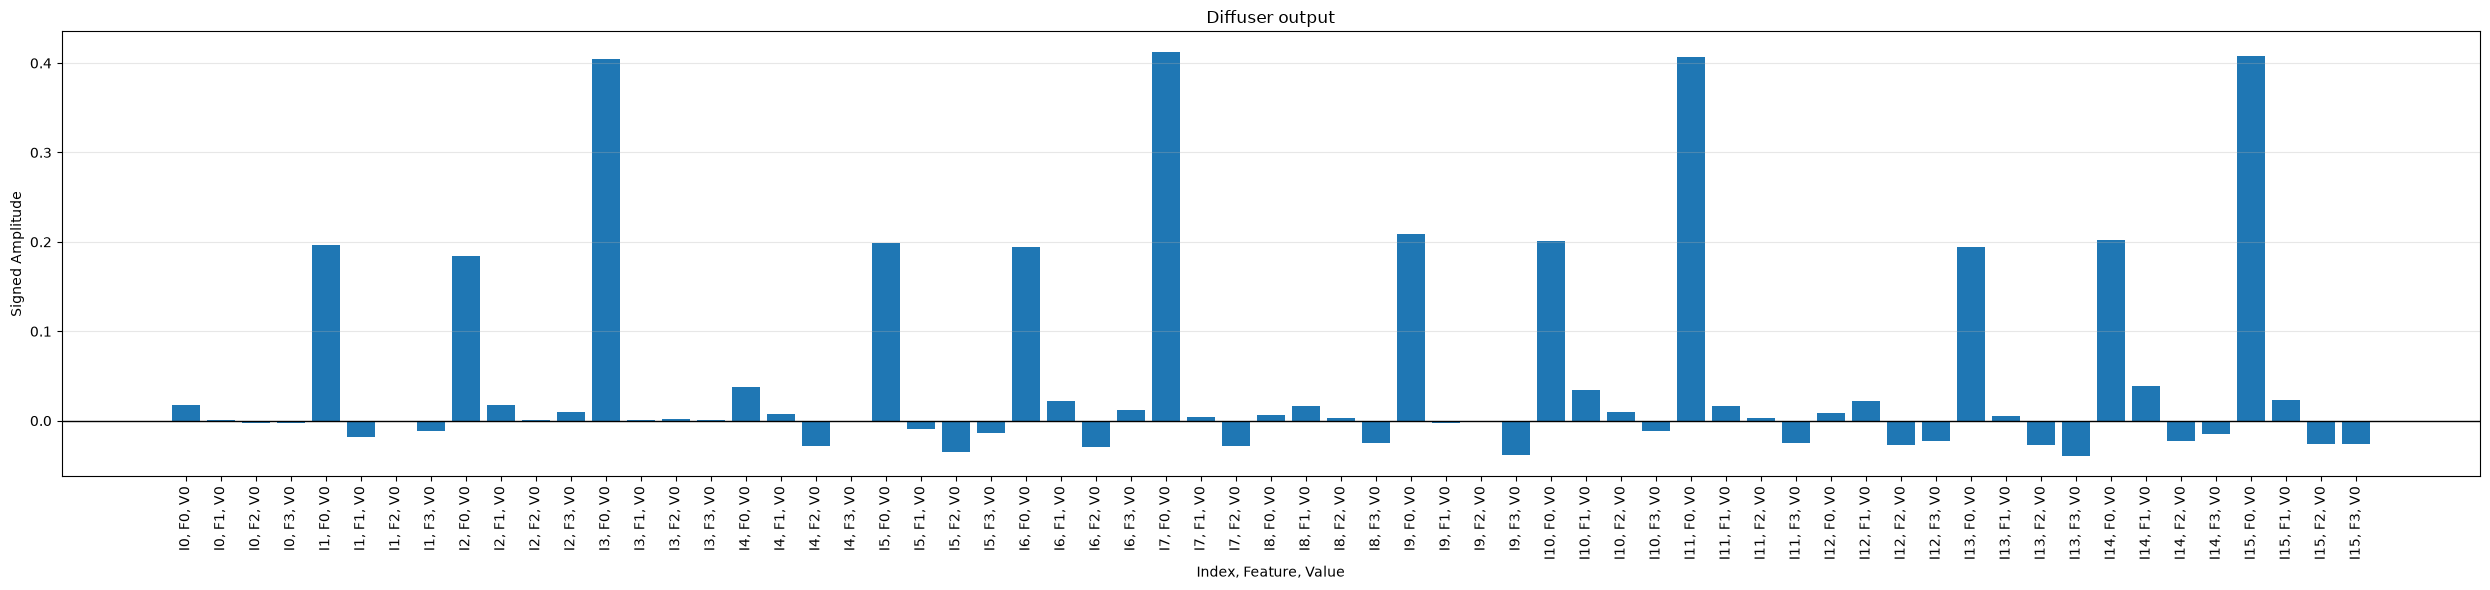


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


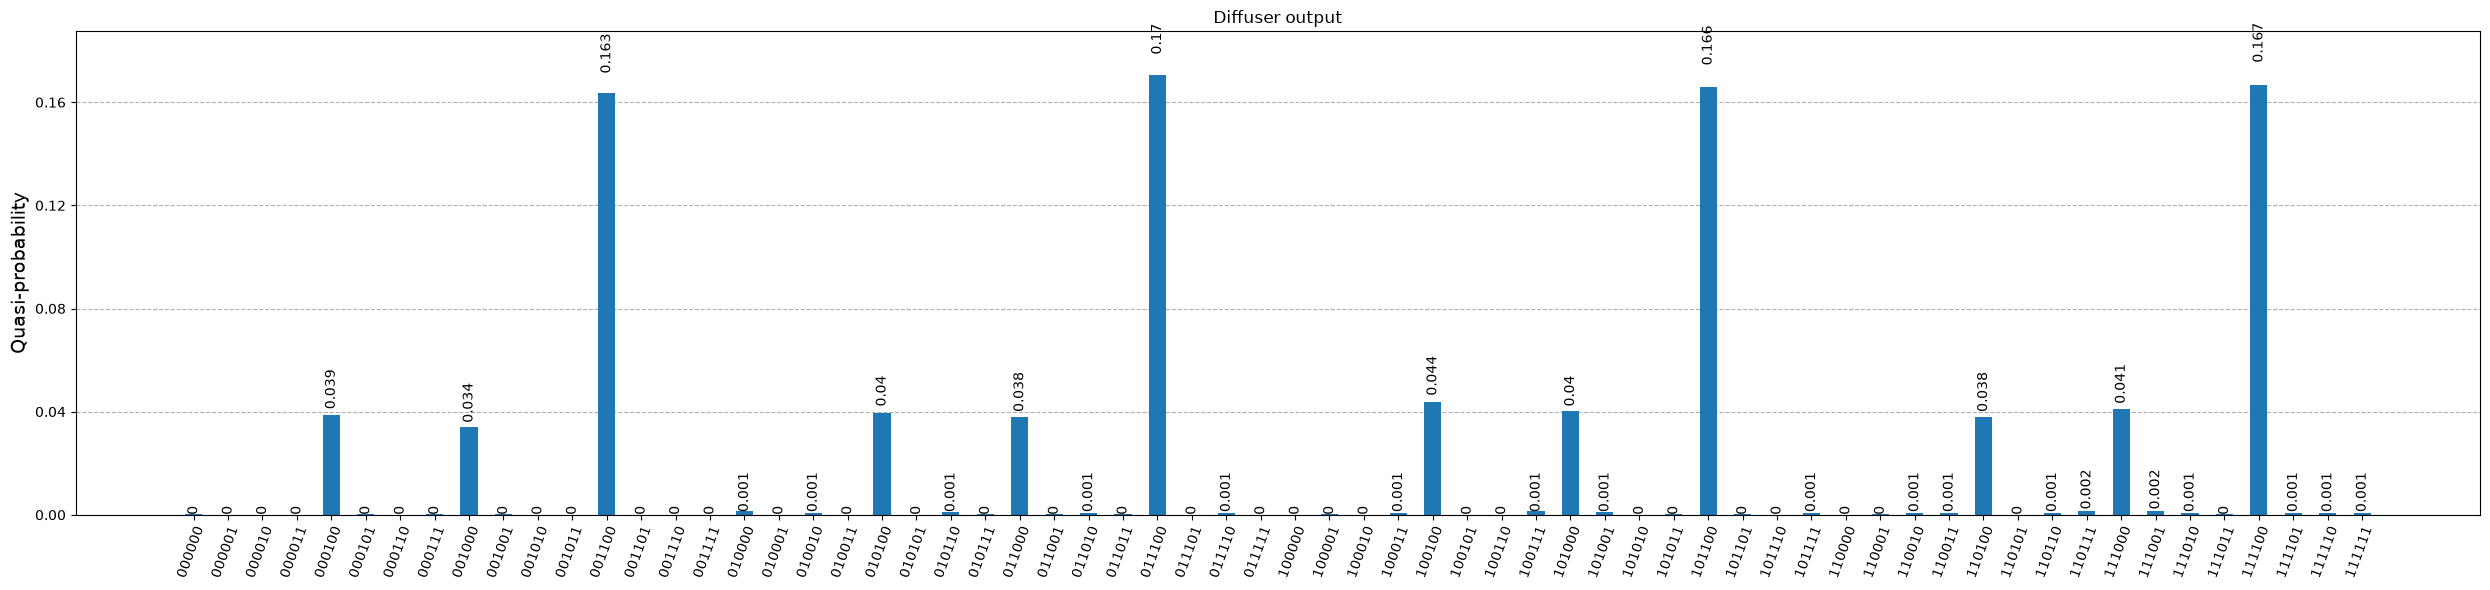

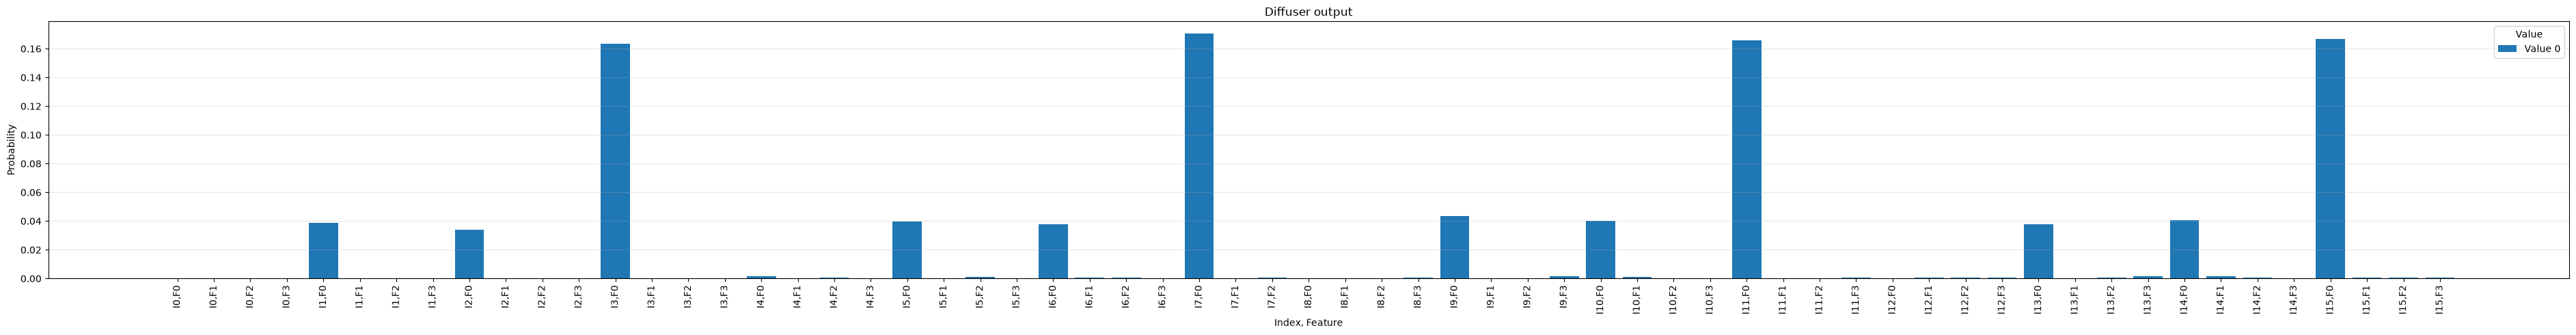


Diffuser output
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        +0.017                   
0                        1                        +0.001                   
0                        2                        -0.002                   
0                        3                        -0.002                   
1                        0                        +0.197                   
1                        1                        -0.018                   
1                        2                        -0.002                   
1                        3                        -0.011                   
2                        0                        +0.185                   
2                        1                        +0.018                   
2                        2                        +0.000               

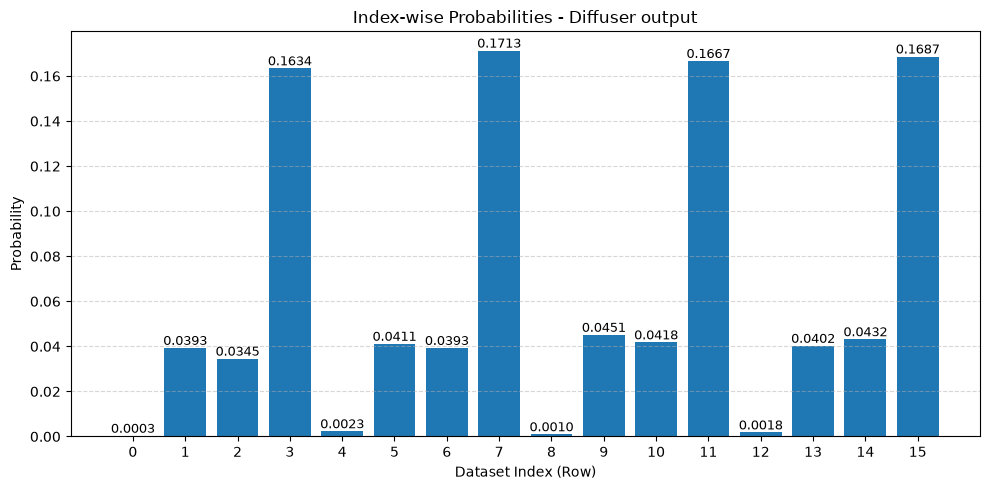




GROVER ITERATION 4


> Oracle: 

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (-0.017023615835105973-2.3798691177674312e-17j)
|000001> : (0.0005743341615614395+3.070417711418665e-17j)
|000010> : (-0.002390553699060632-8.174970211338047e-18j)
|000011> : (-0.0020530564639731105-5.994396354654086e-17j)
|000100> : (-0.19705796687373225-7.108860991143312e-17j)
|000101> : (-0.018492649857623725+2.544920618236112e-17j)
|000110> : (-0.0015055616899457135-6.5643630289433e-17j)
|000111> : (-0.011133614397752626-1.9661369346319303e-17j)
|001000> : (-0.18473674182002636-2.950624989969592e-17j)
|001001> : (0.017779723673185296-2.2715763496796752e-17j)
|001010> : (0.00032524114537187777+9.22299885775223e-18j)
|001011> : (0.009400810925543426-1.2782064357682383e-17j)
|001100> : (-0.40425048676227177+4.067796826481979e-17j)
|001101> : (0.000300051769677289+1.2034953319055792e-17j)
|001110> : (0.001856668223505723+1.713421972229542e-17j)
|001111> : (0.0006318764736374236-6.11660827502039e-17j)
|010000> : (-0.037935353971752954+2.304307467

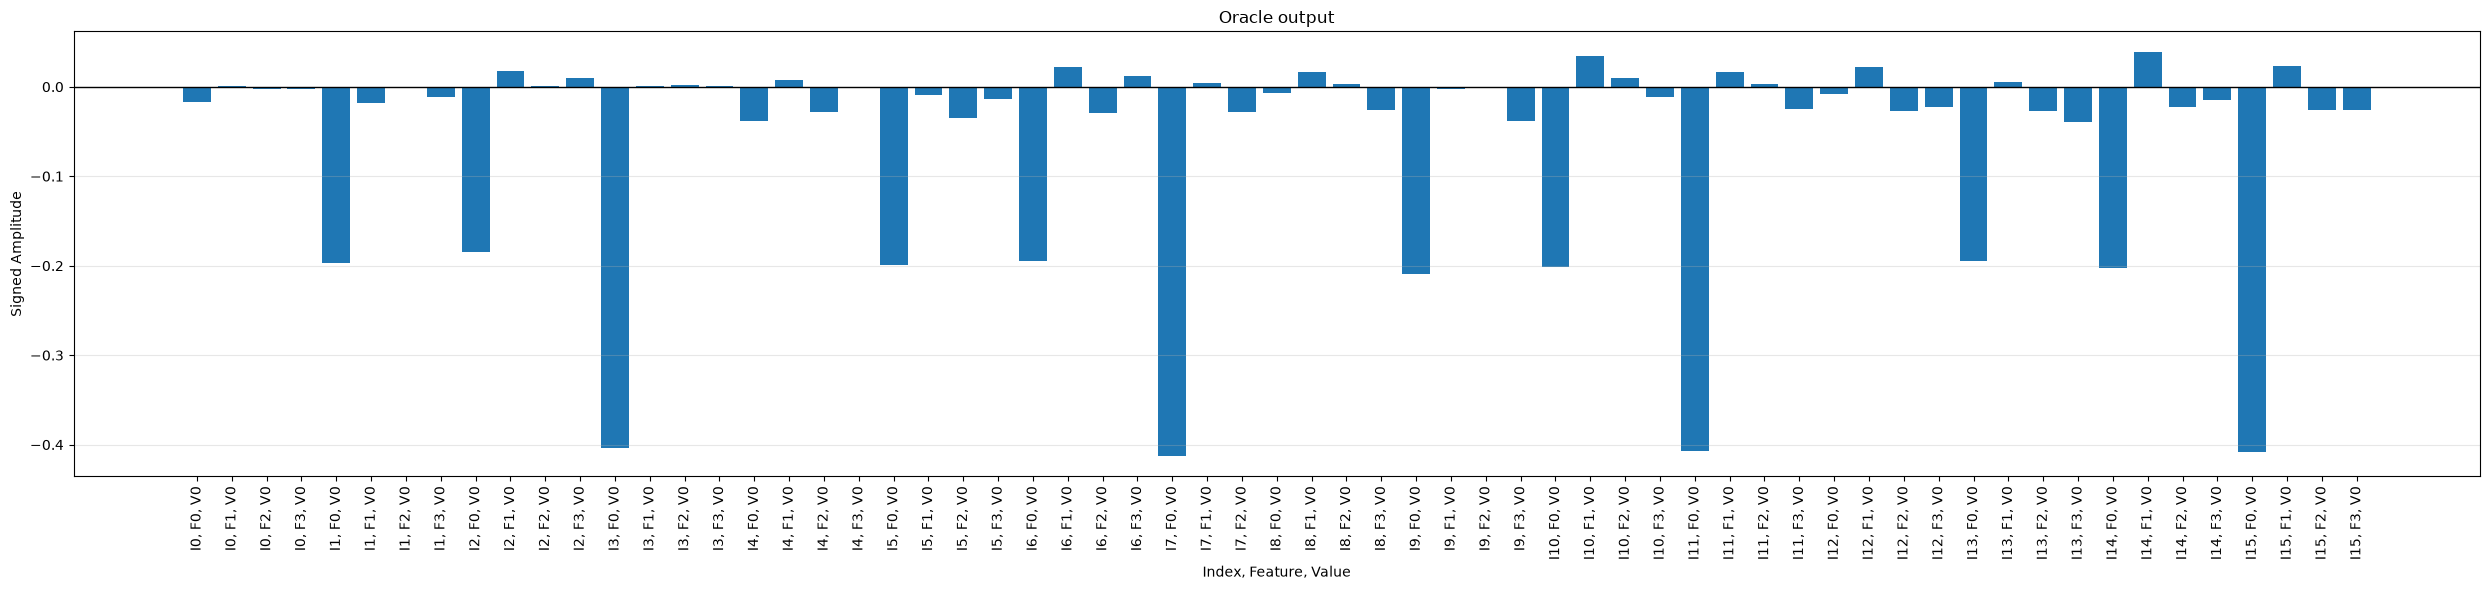


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


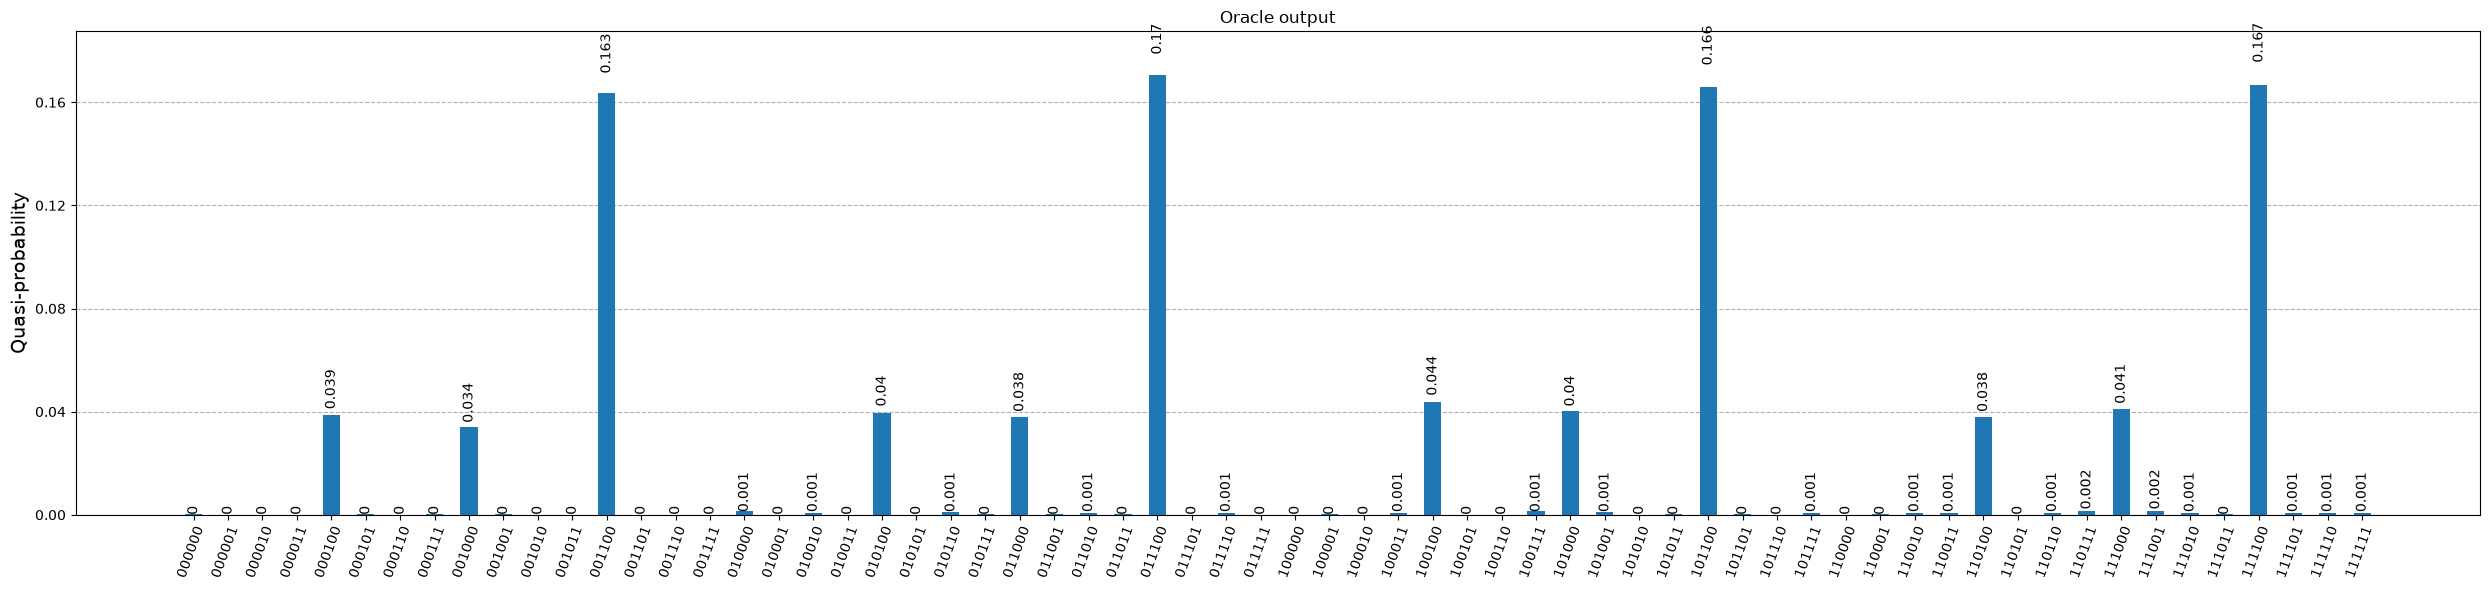

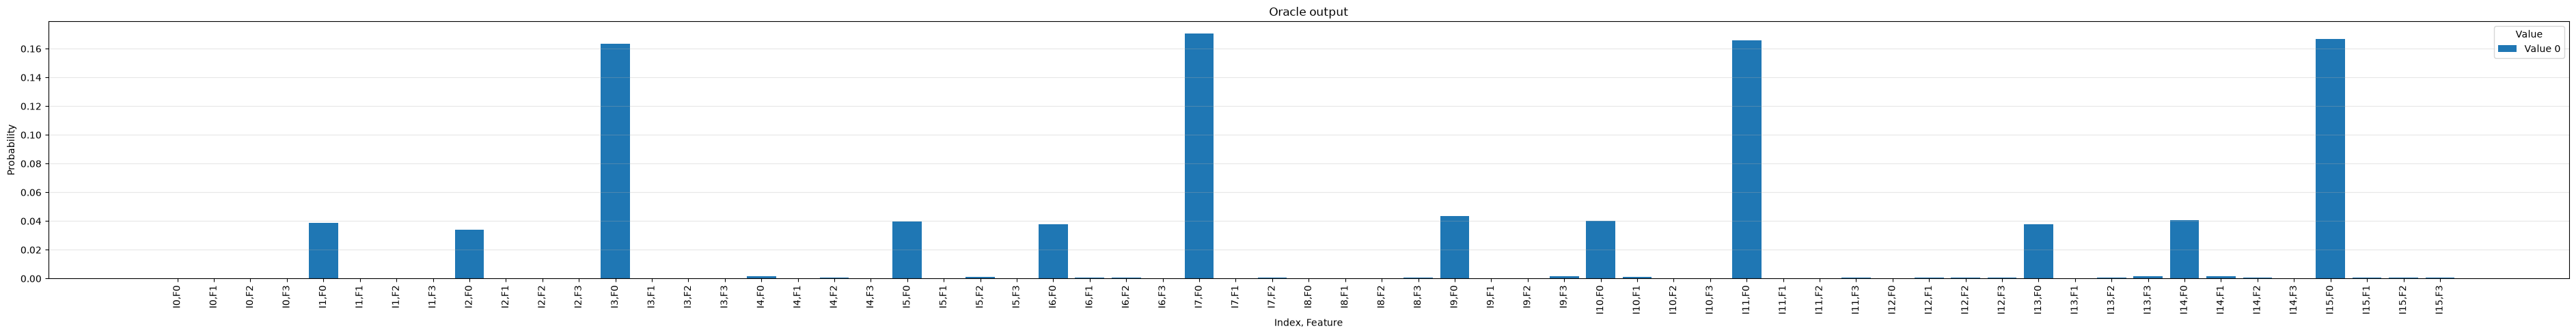


Oracle output
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        -0.017                   
0                        1                        +0.001                   
0                        2                        -0.002                   
0                        3                        -0.002                   
1                        0                        -0.197                   
1                        1                        -0.018                   
1                        2                        -0.002                   
1                        3                        -0.011                   
2                        0                        -0.185                   
2                        1                        +0.018                   
2                        2                        +0.000                 

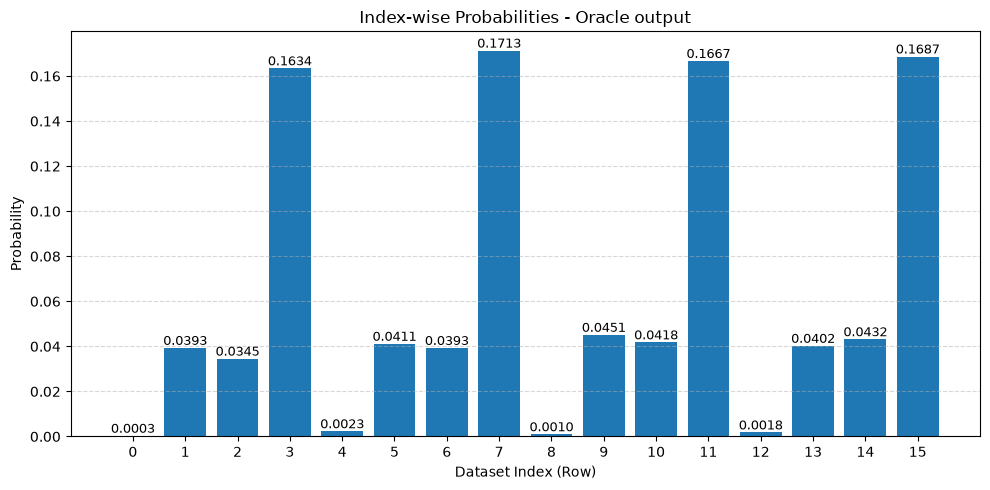



> Diffuser: 
Applying inverse of U...

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (-0.006690127474656153+5.725566367968205e-17j)
|000001> : (0.0038874207139214887+7.15207325768662e-17j)
|000010> : (-0.01618062896033659-7.048046239687908e-18j)
|000011> : (-0.01389625545379825-9.095007102737474e-17j)
|000100> : (-0.0774420035703081-5.139214133081932e-17j)
|000101> : (-0.1251687866108988+7.598446742637199e-17j)
|000110> : (-0.010190499000912881-6.626862620822186e-17j)
|000111> : (-0.07535864332529937-9.840585599763482e-17j)
|001000> : (-0.07259987325841351-6.572216201171282e-18j)
|001001> : (0.12034329615191373+2.835719248606809e-17j)
|001010> : (0.0022014173109625723-1.9856607243137874e-17j)
|001011> : (0.06363004251787333+2.782123610740665e-17j)
|001100> : (-0.15886679506443097+8.006195942285194e-17j)
|001101> : (0.0020309212698081973+2.7114790023900715e-17j)
|001110> : (0.012566987990605427-6.164736970173223e-17j)
|001111> : (0.004276899854919562-3.2386271798522296e-17j)
|010000> : (-0.014908251943976717+1.1971246565333103e-1

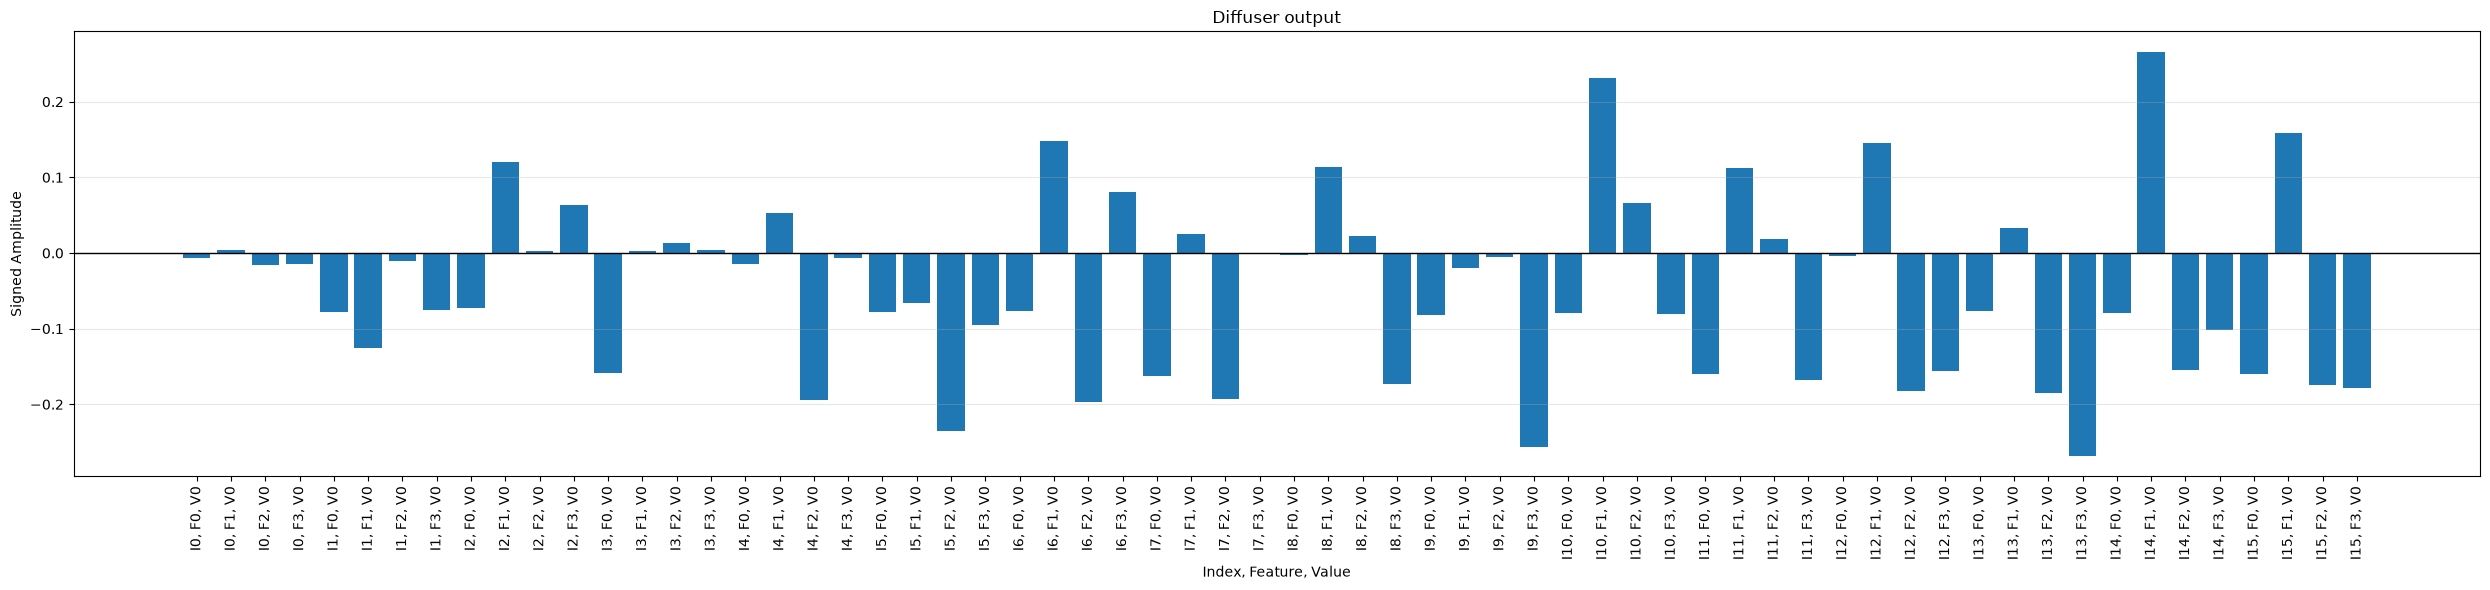


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


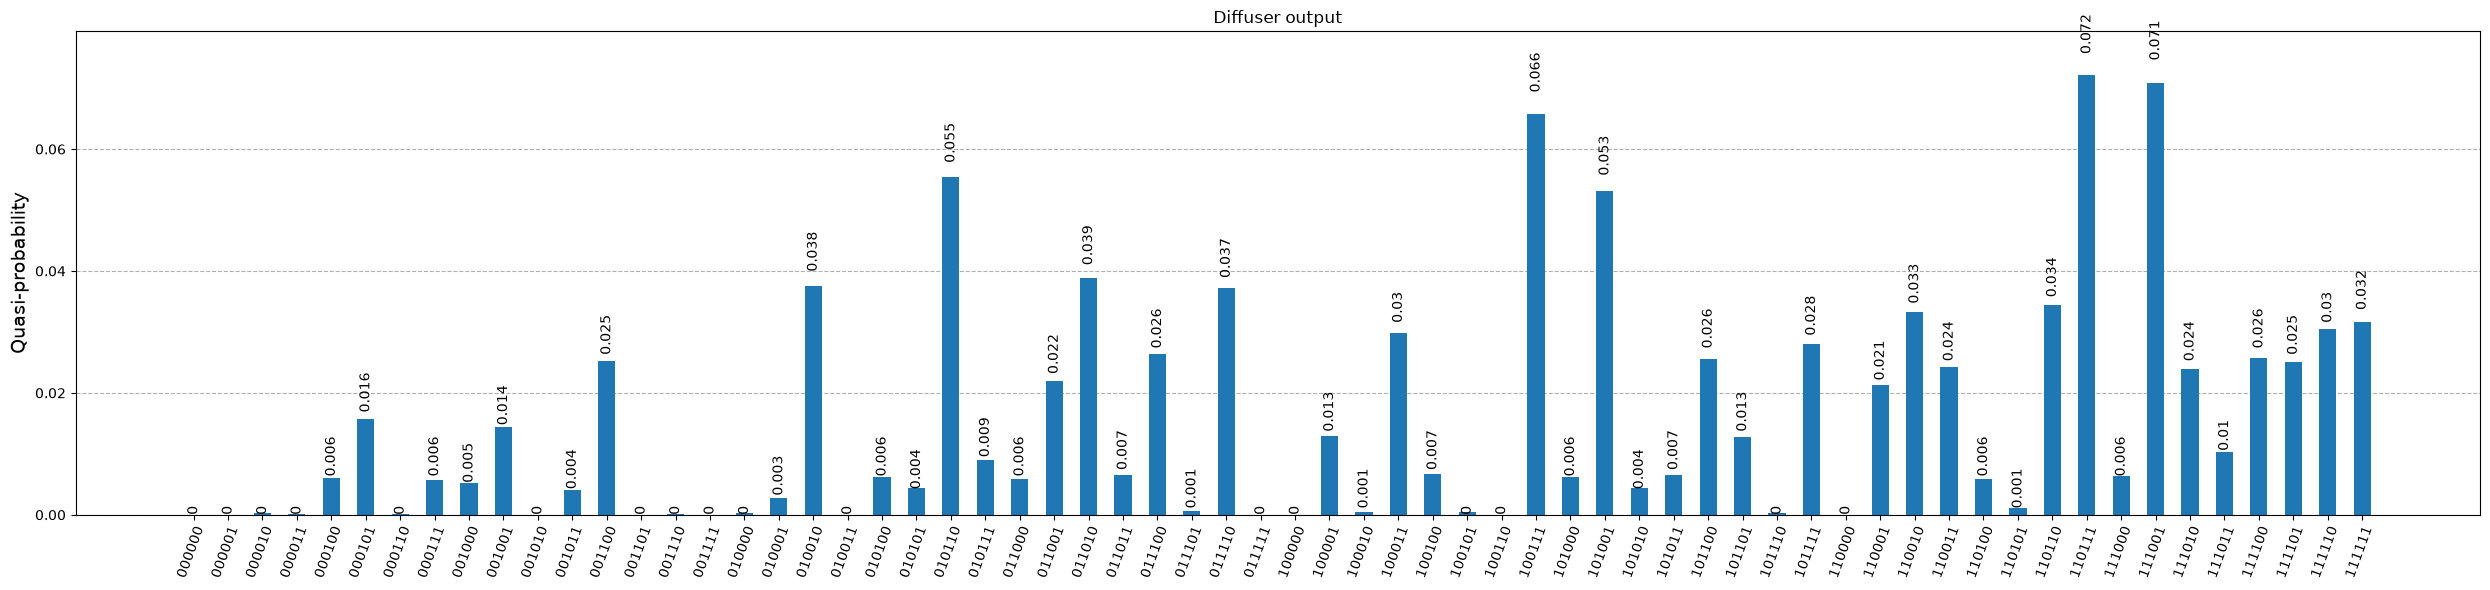

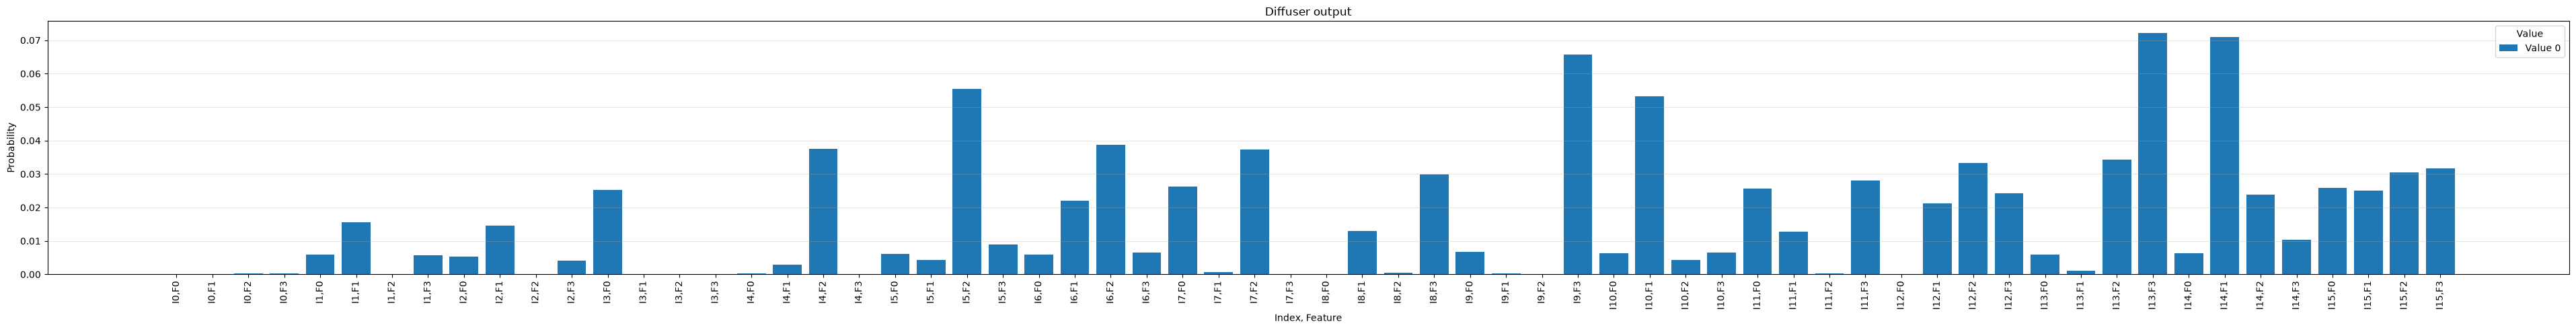


Diffuser output
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        -0.007                   
0                        1                        +0.004                   
0                        2                        -0.016                   
0                        3                        -0.014                   
1                        0                        -0.077                   
1                        1                        -0.125                   
1                        2                        -0.010                   
1                        3                        -0.075                   
2                        0                        -0.073                   
2                        1                        +0.120                   
2                        2                        +0.002               

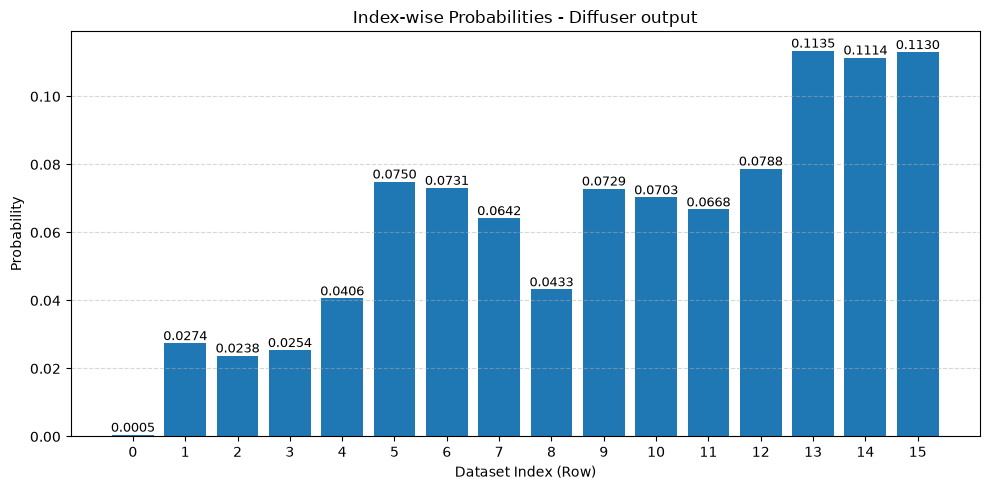




GROVER ITERATION 5


> Oracle: 

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (0.006690127474656152-5.725566367968203e-17j)
|000001> : (0.0038874207139214874+7.15207325768662e-17j)
|000010> : (-0.016180628960336587-7.048046239687905e-18j)
|000011> : (-0.013896255453798247-9.095007102737474e-17j)
|000100> : (0.07744200357030809+5.139214133081931e-17j)
|000101> : (-0.12516878661089878+7.598446742637198e-17j)
|000110> : (-0.010190499000912874-6.626862620822184e-17j)
|000111> : (-0.07535864332529935-9.84058559976348e-17j)
|001000> : (0.0725998732584135+6.5722162011712816e-18j)
|001001> : (0.1203432961519137+2.835719248606808e-17j)
|001010> : (0.0022014173109625727-1.985660724313787e-17j)
|001011> : (0.06363004251787331+2.782123610740665e-17j)
|001100> : (0.15886679506443094-8.006195942285191e-17j)
|001101> : (0.002030921269808197+2.7114790023900712e-17j)
|001110> : (0.012566987990605424-6.164736970173222e-17j)
|001111> : (0.004276899854919561-3.238627179852229e-17j)
|010000> : (0.014908251943976719-1.19712465653331e-16j)
|010

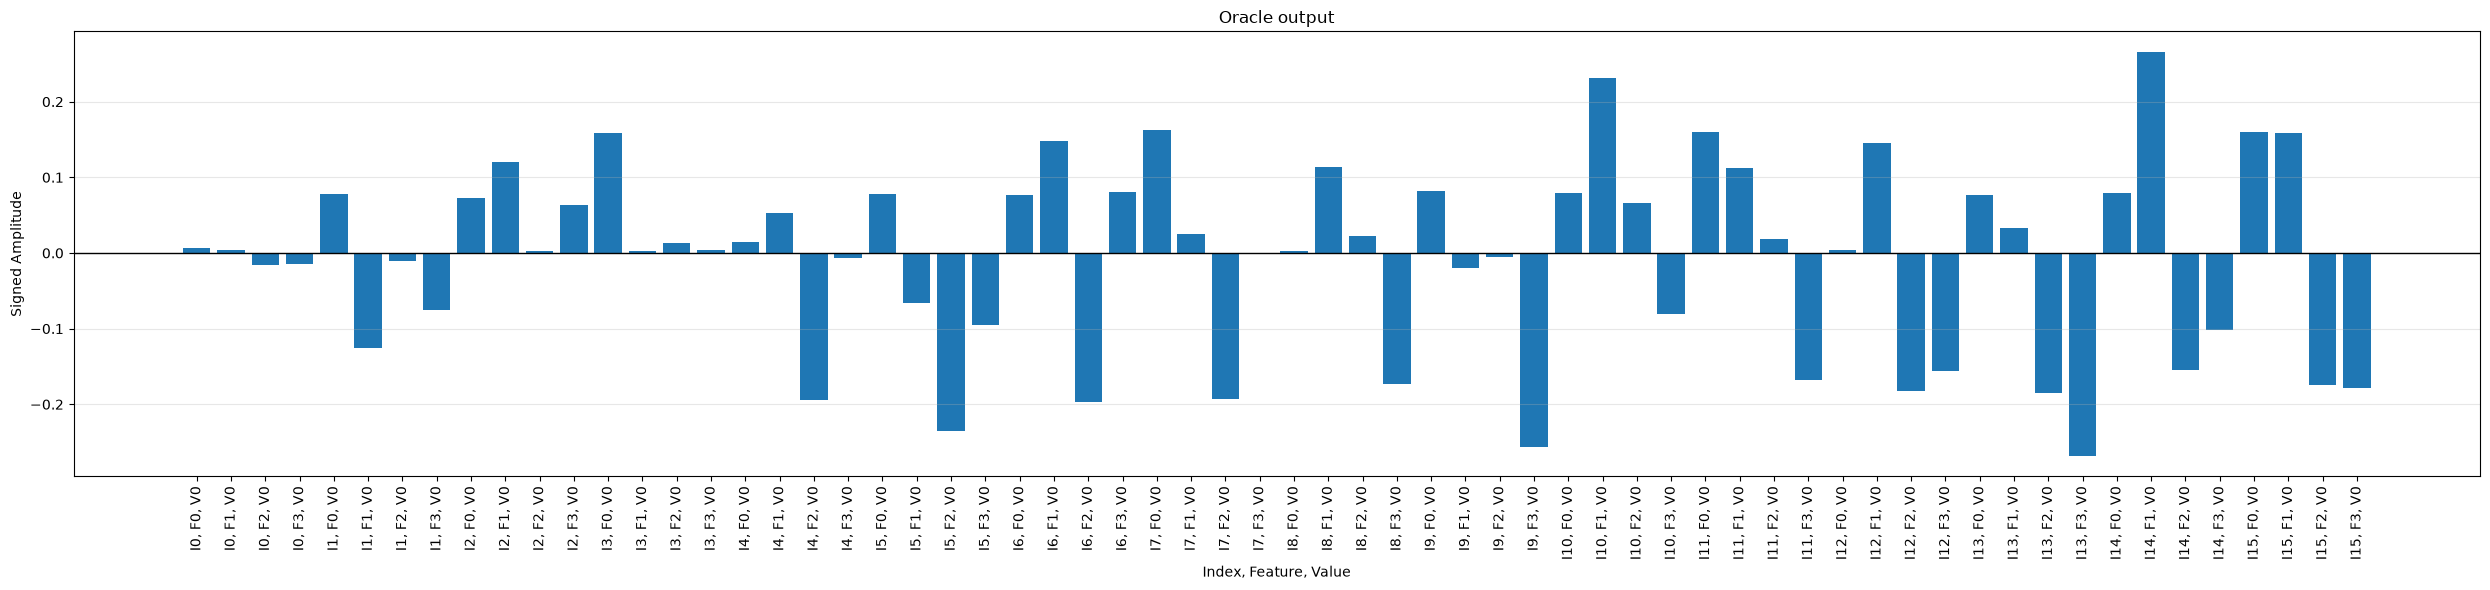


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


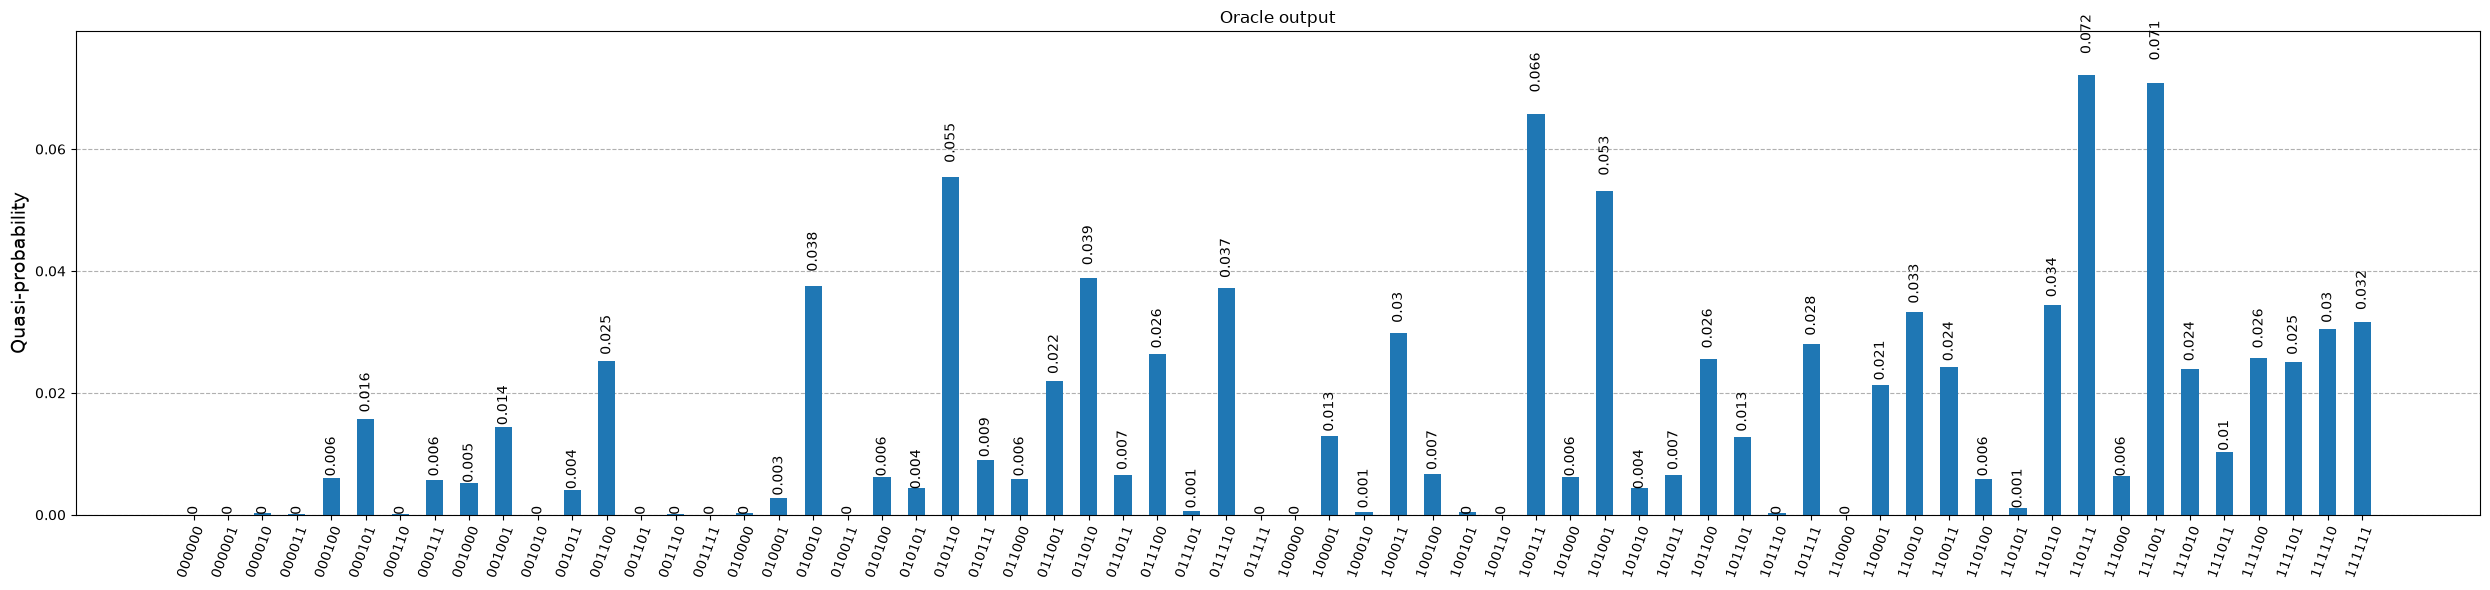

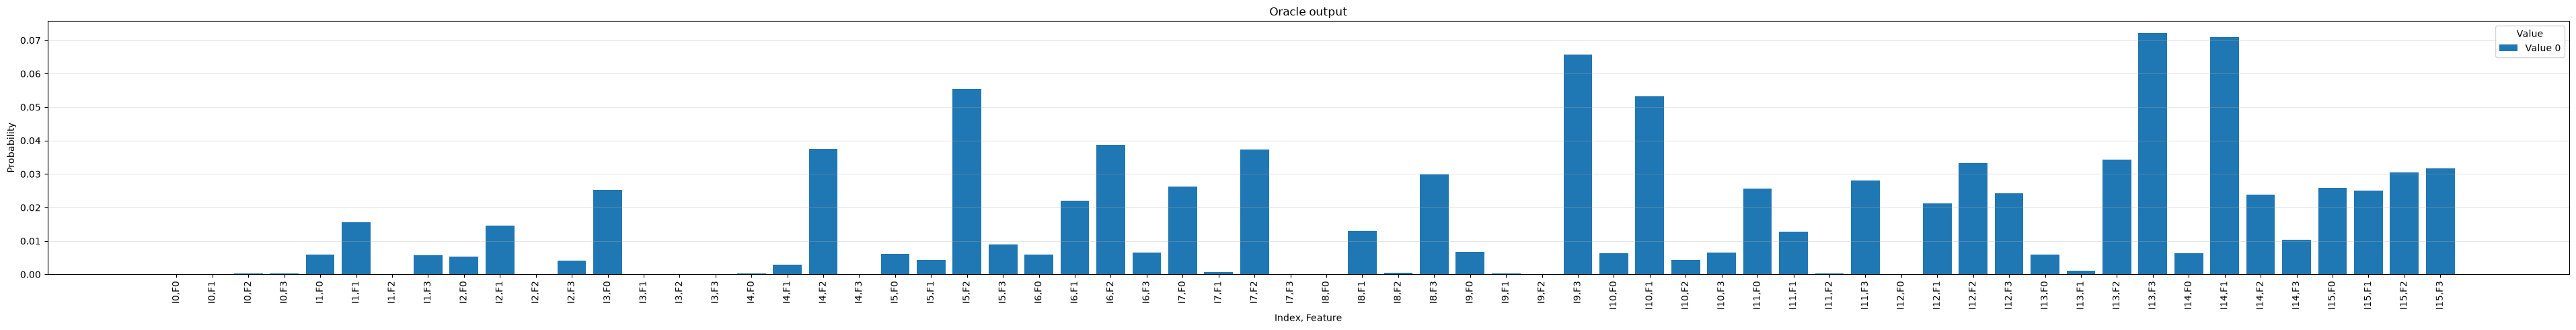


Oracle output
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        +0.007                   
0                        1                        +0.004                   
0                        2                        -0.016                   
0                        3                        -0.014                   
1                        0                        +0.077                   
1                        1                        -0.125                   
1                        2                        -0.010                   
1                        3                        -0.075                   
2                        0                        +0.073                   
2                        1                        +0.120                   
2                        2                        +0.002                 

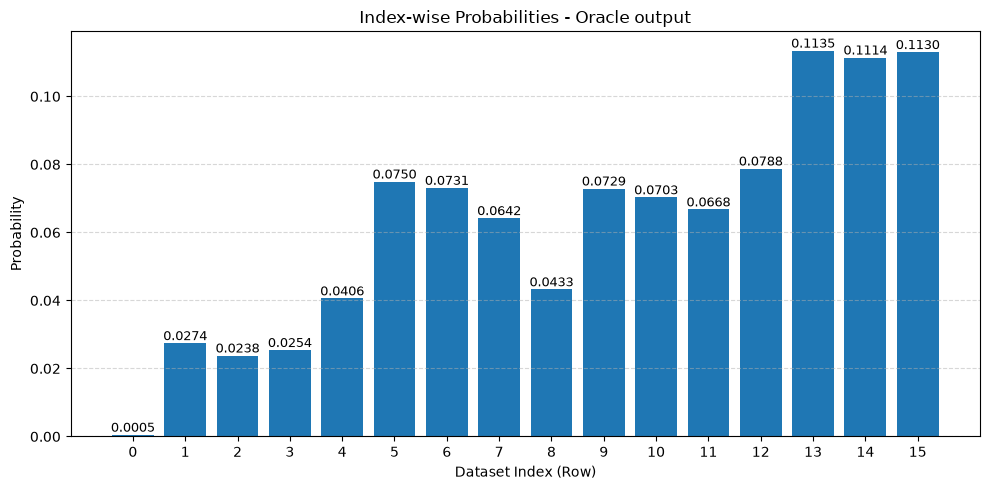



> Diffuser: 
Applying inverse of U...

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000000> : (-0.013539846306189296-4.451240292463754e-17j)
|000001> : (-0.002598642051140602+1.3069032399773413e-16j)
|000010> : (0.010816339656692413-3.258878771305347e-17j)
|000011> : (0.00928929396458533-1.2546248408083085e-16j)
|000100> : (-0.15673136722095762+1.596642344320906e-16j)
|000101> : (0.0836721559908616+1.0646912049460912e-16j)
|000110> : (0.0068120898597483015-9.065930973223601e-17j)
|000111> : (0.05037533981355307-1.4712826103475975e-16j)
|001000> : (-0.14693159876124376+7.274187452709148e-17j)
|001001> : (-0.08044643813141021+8.159563784728913e-19j)
|001010> : (-0.0014715915815048837-1.4540853077456683e-17j)
|001011> : (-0.04253506794638065+4.894018216663706e-17j)
|001100> : (-0.3215233187226904-6.669828827177774e-17j)
|001101> : (-0.001357619306647062+3.2549153562871474e-17j)
|001110> : (-0.008400712413662066+6.633473405967048e-18j)
|001111> : (-0.002858998968572881+7.052162028680752e-18j)
|010000> : (-0.030172136596809365-7.2729155079470

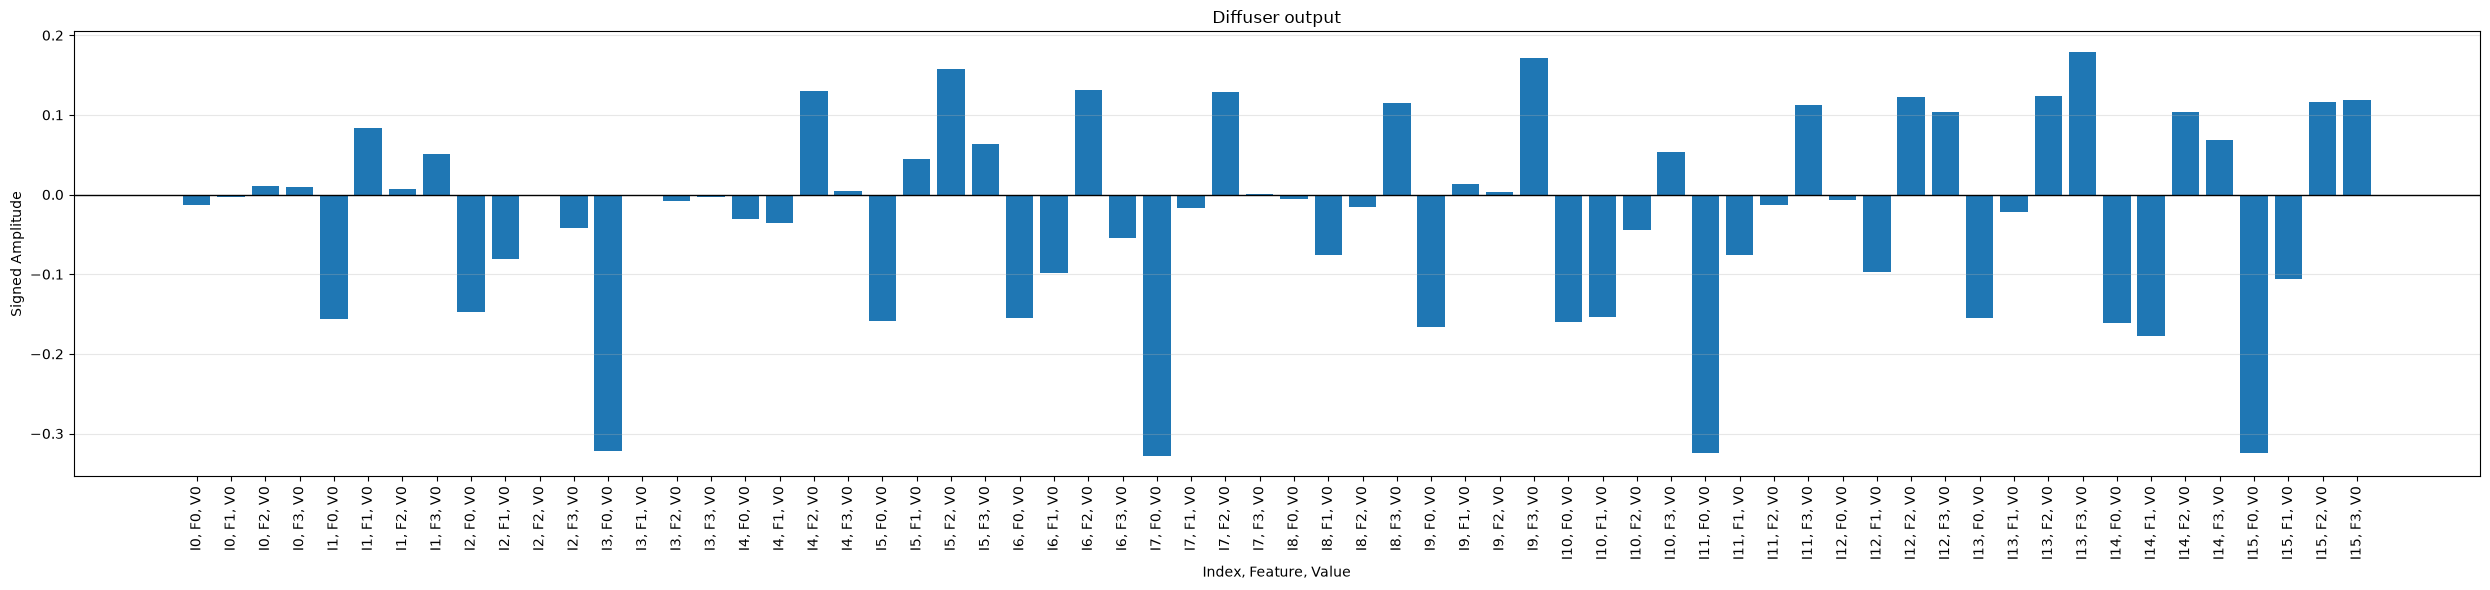


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


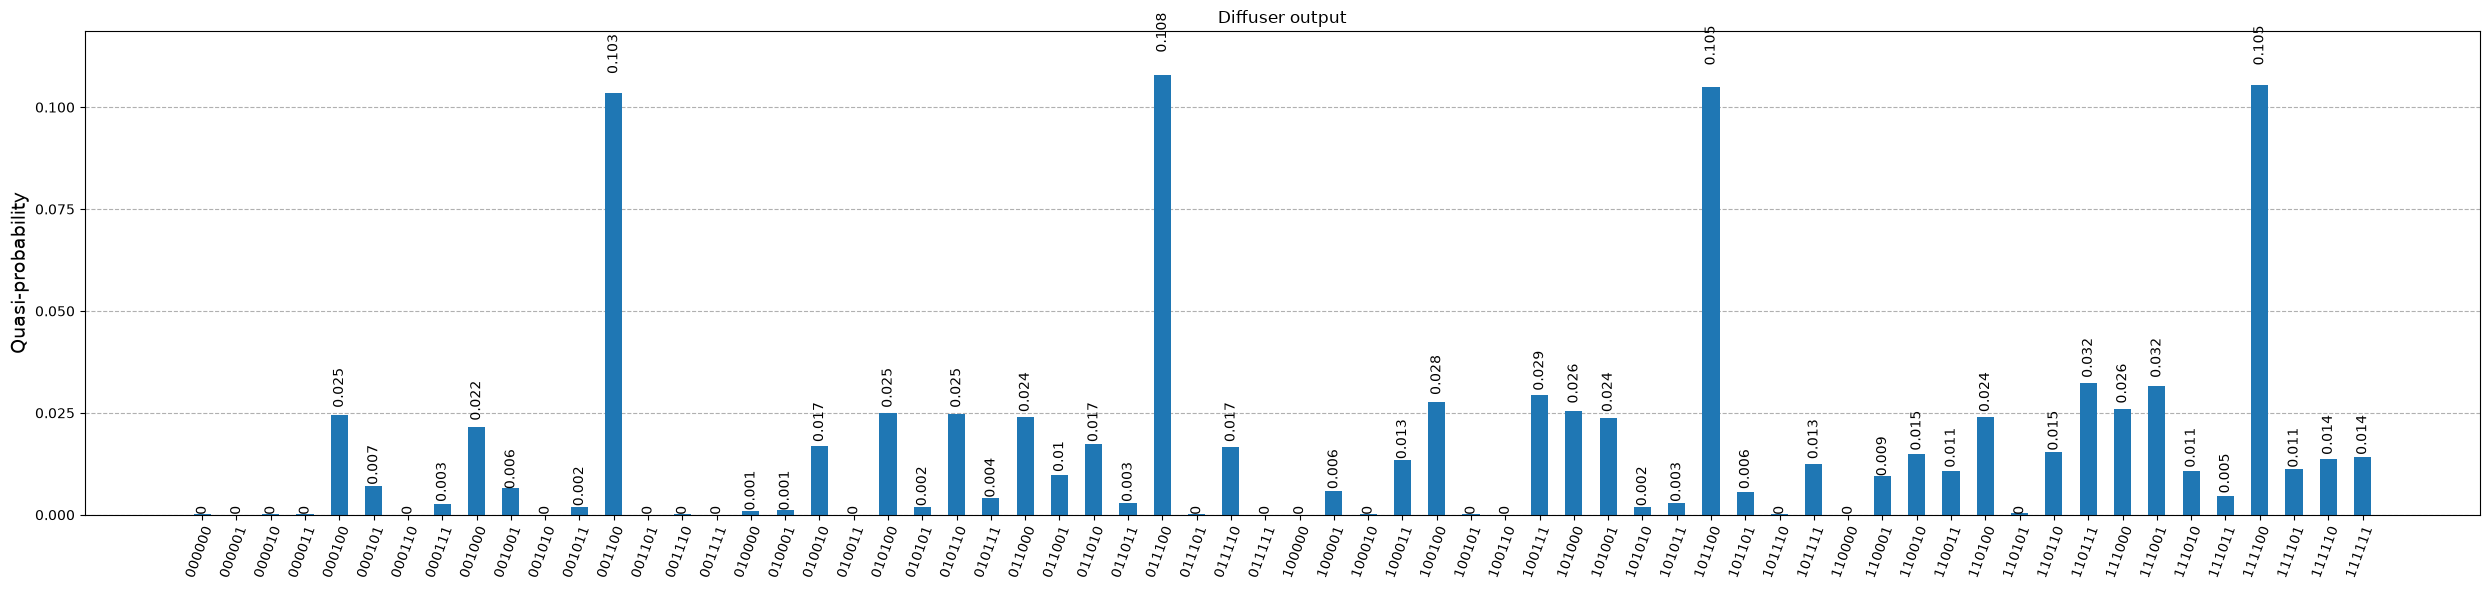

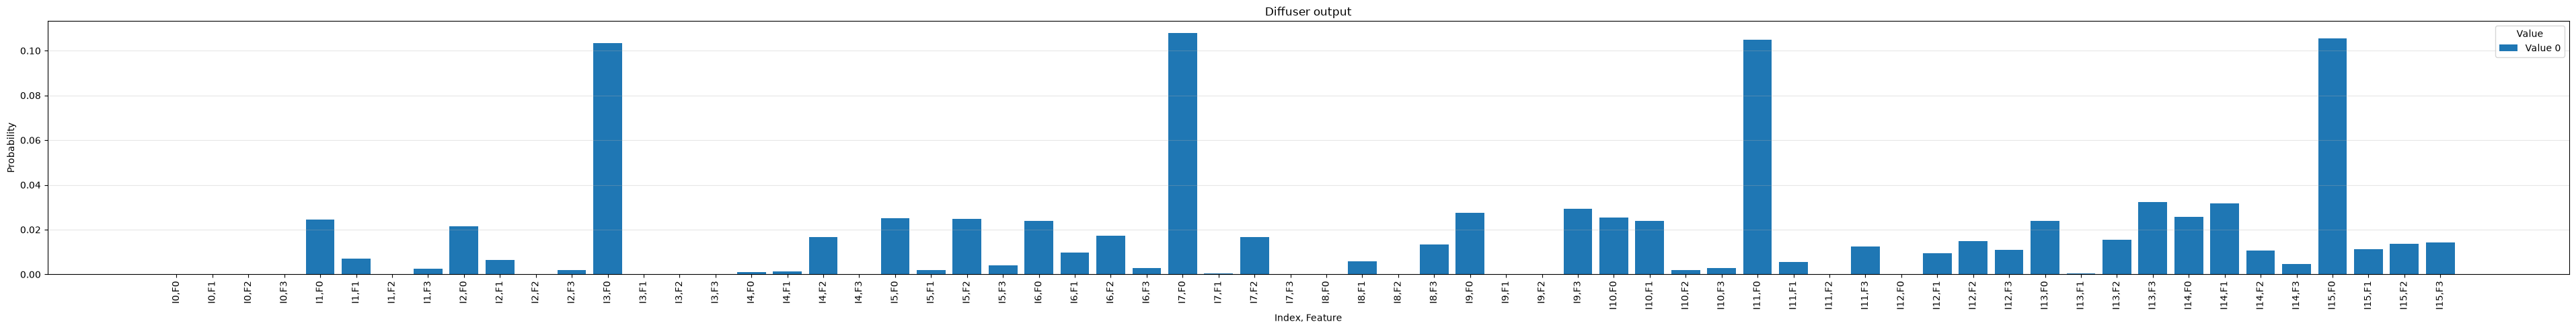


Diffuser output
Row                      Feature                  Value-0-Amplitude        
---------------------------------------------------------------------------
0                        0                        -0.014                   
0                        1                        -0.003                   
0                        2                        +0.011                   
0                        3                        +0.009                   
1                        0                        -0.157                   
1                        1                        +0.084                   
1                        2                        +0.007                   
1                        3                        +0.050                   
2                        0                        -0.147                   
2                        1                        -0.080                   
2                        2                        -0.001               

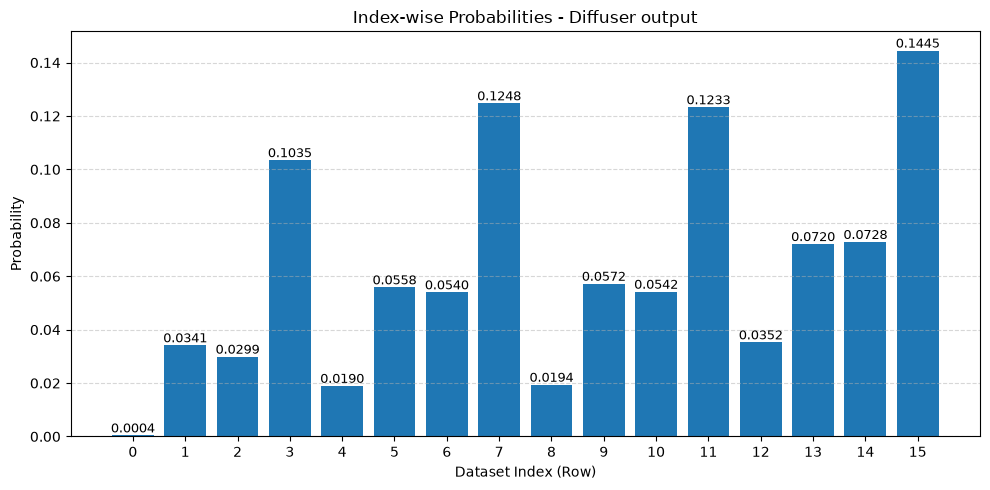


FINAL MEASUREMENT

Index measurement results for (2000) shots:
{'0000': 1, '1000': 51, '0110': 97, '1010': 111, '0100': 37, '1100': 86, '1110': 163, '1001': 104, '0101': 119, '0011': 217, '0001': 82, '0010': 54, '1101': 125, '1111': 275, '0111': 250, '1011': 228}


In [48]:
GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters, B_parameters=B_parameters_ampl_fidelity,
    depth_A=pqc_depth_for_dataset_encoder, depth_B=pqc_depth_for_query_encoder,
    num_of_iter=5, scheme="AMPL"
)

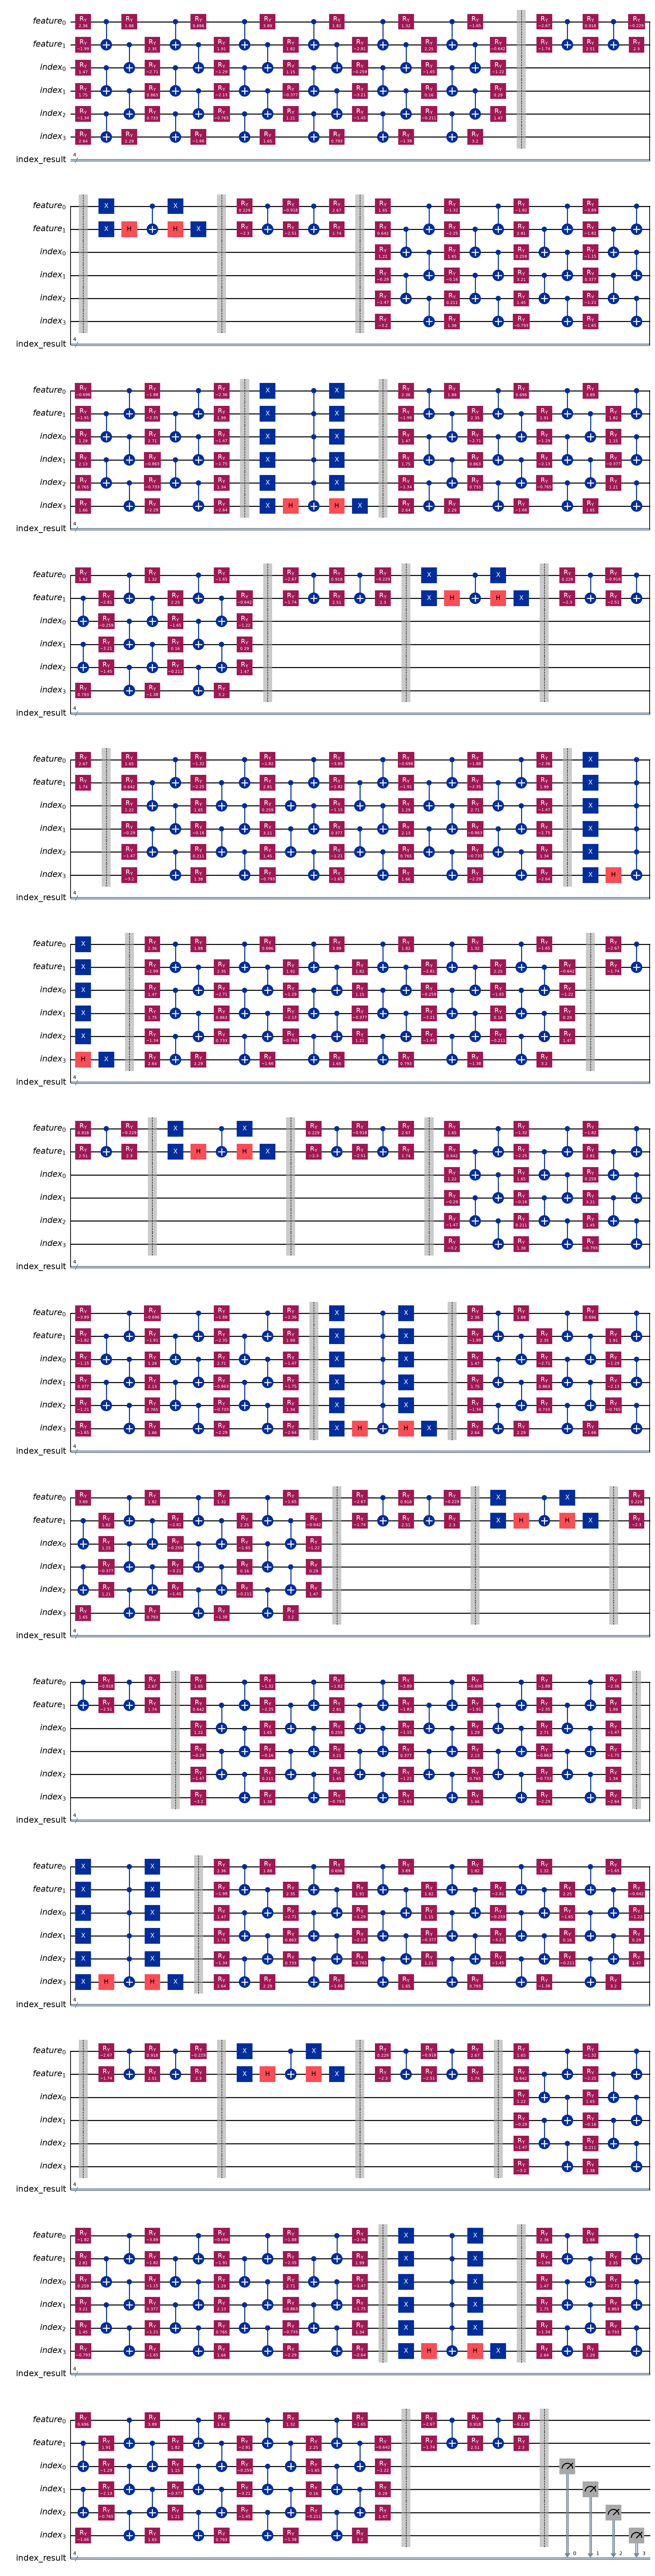

In [49]:
GS.draw_circuit()

In [50]:
GS.analysis()

REGISTER ANALYSIS
Dataset size (N): 16
Index qubits: 4
Data qubits: 2
Total qubits: 6
Classical bits: 4

CIRCUIT ANALYSIS
Circuit width: 10
Circuit size: 994
Circuit depth/layers: 315

OPERATION COUNT
OrderedDict({'ry': 528, 'cx': 357, 'x': 80, 'barrier': 32, 'h': 20, 'mcx': 5, 'measure': 4})
